# Semana 2 — Aprendizaje Supervisado
Dataset: Olist Brazilian E-commerce | Modelos: Regresión Lineal, Ridge, Árbol, Random Forest, XGBoost · Clasificación binaria y multiclase

## Importamos librerías, pandas para trabajar en dataframes, seabron y matplotlib para graficar

In [5]:
import pandas as pd #importamos pandas para el manejo de dataframes (tablas)
import seaborn as sns #importamos seaborn para graficas avanzadas
import matplotlib.pyplot as plt #importamos matplotlib para gráficas 
import matplotlib.gridspec as gridspec #importamos matplotlib para gráficas 
from scipy import stats #importamos scipy para cálculo stadístico
import matplotlib.ticker as mticker 
import numpy as np #importamos numpy para manipular arreglos. 

In [6]:
#Carga de archivos dataset a utilizar, se basará en análisis 
orders = pd.read_csv('olist_orders_dataset.csv')
items = pd.read_csv('olist_order_items_dataset.csv')
customers = pd.read_csv('olist_customers_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
payments = pd.read_csv('olist_order_payments_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

In [7]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## Procesamiento de las bases de datos. 

Previo a generar el modelado de la base de datos en Python, vamos a proceder a revisar cada uno de los dataset, procesar y limpiar conforme sea necesario

In [8]:
# 2. INSPECCIÓN INDIVIDUAL
# ─────────────────────────────────────────────
datasets = {
    'orders': orders, 'items': items, 'customers': customers,
    'reviews': reviews, 'payments': payments,
    'products': products, 'sellers': sellers
}

for nombre, df in datasets.items():
    print(f"\n{'='*50}")
    print(f"  {nombre.upper()}  →  {df.shape[0]:,} filas | {df.shape[1]} columnas")
    print(f"{'='*50}")
    print(df.dtypes.to_string())
    print(f"\nNulos:\n{df.isnull().sum()[df.isnull().sum() > 0].to_string()}")
    print(f"\nMuestra:\n{df.head(2).to_string()}")


  ORDERS  →  99,441 filas | 8 columnas
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str

Nulos:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

Muestra:
                           order_id                       customer_id order_status order_purchase_timestamp    order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-

In [9]:
orders
print("=" * 60)
print("1. DIMENSIONES Y TIPOS DE DATOS")
print("=" * 60)
print(f"Filas: {orders.shape[0]:,}  |  Columnas: {orders.shape[1]}")
print(f"\nTipos de datos:\n{orders.dtypes}")

1. DIMENSIONES Y TIPOS DE DATOS
Filas: 99,441  |  Columnas: 8

Tipos de datos:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object



2. DISTRIBUCIÓN DE order_status
              cantidad  porcentaje
order_status                      
delivered        96478       97.02
shipped           1107        1.11
canceled           625        0.63
unavailable        609        0.61
invoiced           314        0.32
processing         301        0.30
created              5        0.01
approved             2        0.00


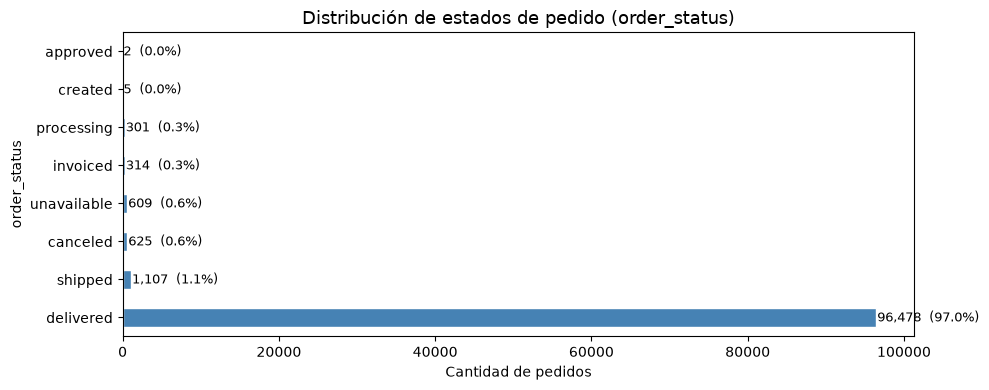


INTERPRETACIÓN:
- 'delivered' domina con ~97% → dataset muy sesgado hacia pedidos completados.
- Los estados 'shipped', 'canceled', 'unavailable' son minoritarios.
- Para modelos predictivos, si usamos order_status como target necesitaremos
  técnicas de balanceo (SMOTE, class_weight) dado el desbalance.



In [10]:
#ESTADÍSTICOS DESCRIPTIVOS BÁSICOS
#    (antes de convertir fechas, para ver qué tenemos crudo)
# ─────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("2. DISTRIBUCIÓN DE order_status")
print("=" * 60)
status_counts = orders['order_status'].value_counts()
status_pct    = orders['order_status'].value_counts(normalize=True) * 100

resumen_status = pd.DataFrame({
    'cantidad': status_counts,
    'porcentaje': status_pct.round(2)
})
print(resumen_status)

# Visualización
fig, ax = plt.subplots(figsize=(10, 4))
status_counts.plot(kind='barh', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Distribución de estados de pedido (order_status)', fontsize=13)
ax.set_xlabel('Cantidad de pedidos')
for i, v in enumerate(status_counts):
    ax.text(v + 100, i, f'{v:,}  ({v/len(orders)*100:.1f}%)', va='center', fontsize=9)
plt.tight_layout()
plt.show()

# INTERPRETACIÓN PEDAGÓGICA
print("""
INTERPRETACIÓN:
- 'delivered' domina con ~97% → dataset muy sesgado hacia pedidos completados.
- Los estados 'shipped', 'canceled', 'unavailable' son minoritarios.
- Para modelos predictivos, si usamos order_status como target necesitaremos
  técnicas de balanceo (SMOTE, class_weight) dado el desbalance.
""")

3. MAPA DE NULOS
                               nulos  porcentaje
order_delivered_customer_date   2965        2.98
order_delivered_carrier_date    1783        1.79
order_approved_at                160        0.16


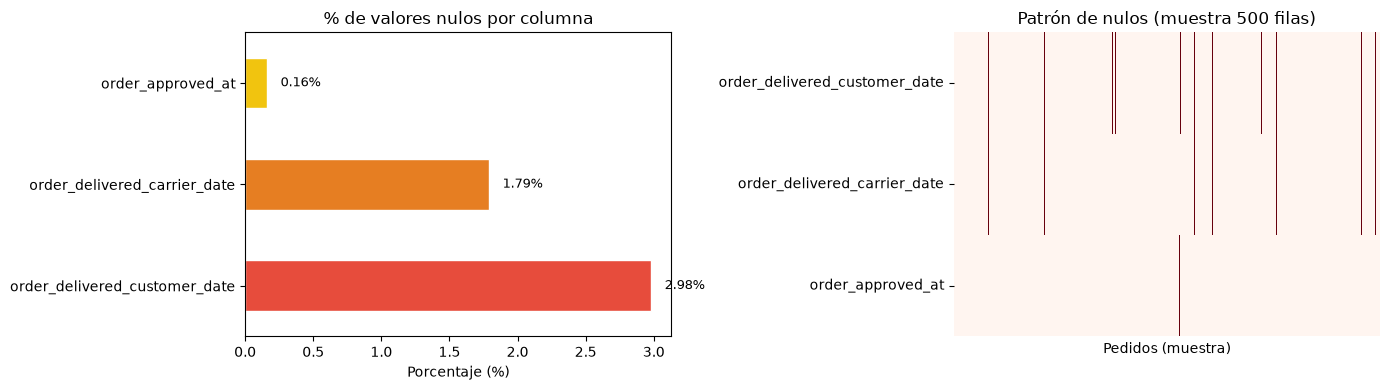

In [11]:
print("=" * 60)
print("3. MAPA DE NULOS")
print("=" * 60)

nulos = pd.DataFrame({
    'nulos':      orders.isnull().sum(),
    'porcentaje': (orders.isnull().sum() / len(orders) * 100).round(2)
})
nulos = nulos[nulos['nulos'] > 0].sort_values('nulos', ascending=False)
print(nulos)

# Visualización mapa de nulos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Barras de % nulos
nulos['porcentaje'].plot(kind='barh', ax=axes[0],
                         color=['#e74c3c','#e67e22','#f1c40f'],
                         edgecolor='white')
axes[0].set_title('% de valores nulos por columna', fontsize=12)
axes[0].set_xlabel('Porcentaje (%)')
for i, v in enumerate(nulos['porcentaje']):
    axes[0].text(v + 0.1, i, f'{v}%', va='center', fontsize=9)

# Heatmap de nulos (muestra de 500 filas para visualizar el patrón)
muestra_nulos = orders[nulos.index].isnull().astype(int).sample(500, random_state=42)
sns.heatmap(muestra_nulos.T, cmap='Reds', cbar=False,
            yticklabels=True, xticklabels=False, ax=axes[1])
axes[1].set_title('Patrón de nulos (muestra 500 filas)', fontsize=12)
axes[1].set_xlabel('Pedidos (muestra)')

plt.tight_layout()
plt.show()

In [12]:
print("=" * 60)
print("4. NULOS SEGÚN order_status (nulos con lógica de negocio)")
print("=" * 60)

cols_fecha = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date'
]

for col in cols_fecha:
    print(f"\n--- {col} ---")
    tabla = orders.groupby('order_status')[col].apply(
        lambda x: x.isnull().sum()
    ).reset_index()
    tabla.columns = ['order_status', 'nulos']
    tabla['total_status'] = tabla['order_status'].map(
        orders['order_status'].value_counts()
    )
    tabla['pct_nulo'] = (tabla['nulos'] / tabla['total_status'] * 100).round(1)
    tabla = tabla[tabla['nulos'] > 0].sort_values('nulos', ascending=False)
    print(tabla.to_string(index=False))

print("""
CONCLUSIÓN PEDAGÓGICA — nulos con lógica de negocio:
┌─────────────────────────────────────────────────────────────┐
│ order_approved_at      → nulo si pedido fue cancelado       │
│                          antes de aprobarse (160 casos)     │
│                                                             │
│ order_delivered_       → nulo si el pedido aún no salió     │
│ carrier_date             al transportista (shipped, etc.)   │
│                                                             │
│ order_delivered_       → nulo si el cliente AÚN no recibió  │
│ customer_date            (shipped, processing, canceled)    │
└─────────────────────────────────────────────────────────────┘
DECISIÓN: NO imputar con media/mediana. Son MCAR* estructurales.
(*Missing Completely At Random por diseño del proceso)
""")

4. NULOS SEGÚN order_status (nulos con lógica de negocio)

--- order_approved_at ---
order_status  nulos  total_status  pct_nulo
    canceled    141           625      22.6
   delivered     14         96478       0.0
     created      5             5     100.0

--- order_delivered_carrier_date ---
order_status  nulos  total_status  pct_nulo
 unavailable    609           609     100.0
    canceled    550           625      88.0
    invoiced    314           314     100.0
  processing    301           301     100.0
     created      5             5     100.0
    approved      2             2     100.0
   delivered      2         96478       0.0

--- order_delivered_customer_date ---
order_status  nulos  total_status  pct_nulo
     shipped   1107          1107     100.0
    canceled    619           625      99.0
 unavailable    609           609     100.0
    invoiced    314           314     100.0
  processing    301           301     100.0
   delivered      8         96478       0.0
  

In [13]:
# ─────────────────────────────────────────────
# CONVERSIÓN DE FECHAS  (orders)
# ─────────────────────────────────────────────
date_cols = [
    'order_purchase_timestamp', 'order_approved_at',
    'order_delivered_carrier_date', 'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# ─────────────────────────────────────────────
# 4. AGREGACIONES PREVIAS AL JOIN
#    (evita duplicar filas en el merge)
# ─────────────────────────────────────────────

# items → un registro por order_id
# Si un pedido tiene 3 ítems los consolida en una fila
items_agg = items.groupby('order_id').agg(
    n_items            = ('order_item_id', 'count'),
    precio_total_items = ('price', 'sum'),
    flete_total        = ('freight_value', 'sum'),
    precio_unitario_max= ('price', 'max'),
    precio_unitario_min= ('price', 'min'),
    # seller más frecuente del pedido (modo)
    seller_id_principal= ('seller_id', lambda x: x.mode()[0]),
    product_id_principal=('product_id', lambda x: x.mode()[0]),
    shipping_limit_date= ('shipping_limit_date', 'max')
).reset_index()

# payments → un registro por order_id
payments_agg = payments.groupby('order_id').agg(
    payment_value_total  = ('payment_value', 'sum'),
    payment_installments = ('payment_installments', 'max'),
    payment_type         = ('payment_type', lambda x: x.mode()[0]),
    n_payment_methods    = ('payment_type', 'nunique')
).reset_index()

# reviews → un registro por order_id (tomar la más reciente si hay varias)
reviews_last = (
    reviews
    .sort_values('review_answer_timestamp')
    .groupby('order_id')
    .last()
    .reset_index()
    [['order_id', 'review_score', 'review_creation_date', 'review_answer_timestamp']]
)

# Construcción del modelo, creación de una sábana de datos completa para procesamiento con ML. 

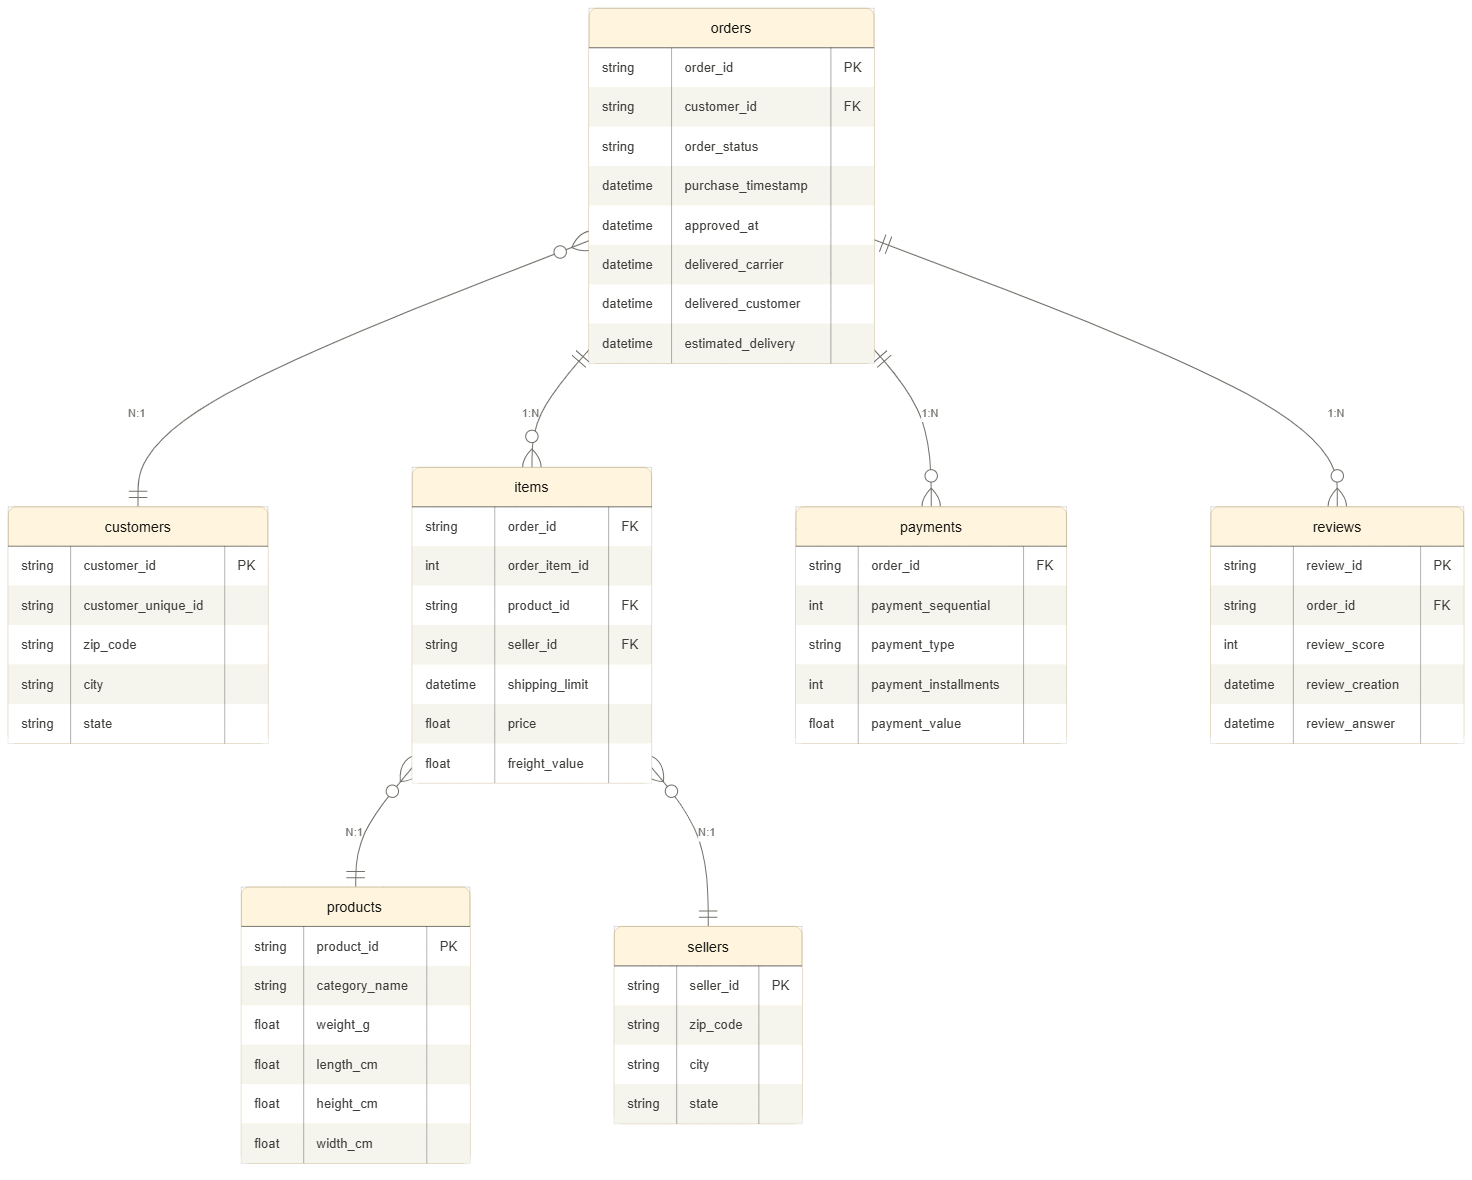

In [14]:
# ─────────────────────────────────────────────
# 5. CONSTRUCCIÓN DE LA SÁBANA  (LEFT JOINs)
#    Tabla base: orders (99.441 pedidos)
# ─────────────────────────────────────────────

sabana = (
    orders
    # → customers (info del comprador)
    .merge(customers, on='customer_id', how='left')

    # → items agregados (precios, cantidad de ítems)
    .merge(items_agg, on='order_id', how='left')

    # → payments agregados (valor pagado, cuotas, método)
    .merge(payments_agg, on='order_id', how='left')

    # → reviews (score)
    .merge(reviews_last, on='order_id', how='left')

    # → products (del ítem principal del pedido)
    .merge(
        products[['product_id', 'product_category_name',
                  'product_weight_g', 'product_length_cm',
                  'product_height_cm', 'product_width_cm']],
        left_on='product_id_principal',
        right_on='product_id',
        how='left'
    )

    # → sellers (del seller principal del pedido)
    .merge(
        sellers[['seller_id', 'seller_city', 'seller_state']],
        left_on='seller_id_principal',
        right_on='seller_id',
        how='left'
    )
)

print(f"\nSábana construida: {sabana.shape[0]:,} filas × {sabana.shape[1]} columnas")


Sábana construida: 99,441 filas × 36 columnas


In [15]:
sabana.describe()

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_zip_code_prefix,n_items,precio_total_items,flete_total,precio_unitario_max,precio_unitario_min,payment_value_total,payment_installments,n_payment_methods,review_score,product_weight_g,product_length_cm,product_height_cm,product_width_cm
count,99441,99281,97658,96476,99441,99441.000000,98666.000000,98666.000000,98666.000000,98666.000000,98666.000000,99440.000000,99440.000000,99440.000000,98673.000000,98650.000000,98650.000000,98650.000000,98650.000000
mean,2017-12-31 08:43:12.776581,2017-12-31 18:35:24.098800,2018-01-04 21:49:48.138278,2018-01-14 12:09:19.035542,2018-01-24 03:08:37.730111,35137.474583,1.141731,137.754076,22.823562,126.631705,125.291581,160.990267,2.930521,1.022586,4.086386,2101.176229,30.097790,16.479078,23.020020
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00,1003.000000,1.000000,0.850000,0.000000,0.850000,0.850000,0.000000,0.000000,1.000000,1.000000,0.000000,7.000000,2.000000,6.000000
25%,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.250000,2017-09-25 22:07:22.250000,2017-10-03 00:00:00,11347.000000,1.000000,45.900000,13.850000,42.200000,40.000000,62.010000,1.000000,1.000000,4.000000,300.000000,18.000000,8.000000,15.000000
50%,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00,24416.000000,1.000000,86.900000,17.170000,79.900000,79.000000,105.290000,2.000000,1.000000,5.000000,700.000000,25.000000,13.000000,20.000000
75%,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.250000,2018-05-25 00:00:00,58900.000000,1.000000,149.900000,24.040000,139.900000,139.840000,176.970000,4.000000,1.000000,5.000000,1800.000000,38.000000,20.000000,30.000000
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00,99990.000000,21.000000,13440.000000,1794.960000,6735.000000,6735.000000,13664.080000,24.000000,2.000000,5.000000,40425.000000,105.000000,105.000000,118.000000
std,NaN,NaN,NaN,NaN,NaN,29797.938996,0.538452,210.645145,21.650909,191.688201,190.884740,221.951257,2.715685,0.148582,1.347618,3763.203914,16.125854,13.310002,11.746284


In [16]:
# ═══════════════════════════════════════════════════════════════
# Feature engineering sobre la sábana en memoria
# (ejecutar antes del EDA)
# ═══════════════════════════════════════════════════════════════

# Tiempo de entrega real (días)
sabana['dias_entrega_real'] = (
    sabana['order_delivered_customer_date'] -
    sabana['order_purchase_timestamp']
).dt.days

# Retraso vs fecha estimada (negativo = adelantado)
sabana['dias_retraso'] = (
    sabana['order_delivered_customer_date'] -
    sabana['order_estimated_delivery_date']
).dt.days

# Target binario: entregado a tiempo
sabana['entrega_a_tiempo'] = (sabana['dias_retraso'] <= 0).astype(int)

# Variables temporales
sabana['anio_compra'] = sabana['order_purchase_timestamp'].dt.year
sabana['mes_compra']  = sabana['order_purchase_timestamp'].dt.month
sabana['dia_semana']  = sabana['order_purchase_timestamp'].dt.dayofweek
sabana['hora_compra'] = sabana['order_purchase_timestamp'].dt.hour

# Ticket promedio por ítem
sabana['ticket_promedio'] = sabana['precio_total_items'] / sabana['n_items']

# Proporción flete / precio total
sabana['prop_flete'] = (
    sabana['flete_total'] /
    (sabana['precio_total_items'] + sabana['flete_total'])
)

# Volumen del producto (cm³)
sabana['volumen_cm3'] = (
    sabana['product_length_cm'] *
    sabana['product_height_cm'] *
    sabana['product_width_cm']
)

# Target binario: reseña positiva
sabana['resena_positiva'] = (sabana['review_score'] >= 4).astype(int)

print(f"Sábana lista: {sabana.shape[0]:,} filas × {sabana.shape[1]} columnas")
print(f"\nColumnas nuevas agregadas:")
nuevas = ['dias_entrega_real','dias_retraso','entrega_a_tiempo',
          'anio_compra','mes_compra','dia_semana','hora_compra',
          'ticket_promedio','prop_flete','volumen_cm3','resena_positiva']
for c in nuevas:
    nulos = sabana[c].isnull().sum()
    print(f"  {c:<25} dtype: {sabana[c].dtype}  |  nulos: {nulos:,}")

Sábana lista: 99,441 filas × 47 columnas

Columnas nuevas agregadas:
  dias_entrega_real         dtype: float64  |  nulos: 2,965
  dias_retraso              dtype: float64  |  nulos: 2,965
  entrega_a_tiempo          dtype: int64  |  nulos: 0
  anio_compra               dtype: int32  |  nulos: 0
  mes_compra                dtype: int32  |  nulos: 0
  dia_semana                dtype: int32  |  nulos: 0
  hora_compra               dtype: int32  |  nulos: 0
  ticket_promedio           dtype: float64  |  nulos: 775
  prop_flete                dtype: float64  |  nulos: 775
  volumen_cm3               dtype: float64  |  nulos: 791
  resena_positiva           dtype: int64  |  nulos: 0


# Análisis exploratorio. Exploratory Data Analyis (EDA).

Procedemos con un análisis exploratorio del conjunto de datos creado, configuramos visualizaciones para poder seleccionar y aplicar criterios de aprendizaje automático. 

Variables numéricas  (25): ['customer_zip_code_prefix', 'n_items', 'precio_total_items', 'flete_total', 'precio_unitario_max', 'precio_unitario_min', 'payment_value_total', 'payment_installments', 'n_payment_methods', 'review_score', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'dias_entrega_real', 'dias_retraso', 'entrega_a_tiempo', 'anio_compra', 'mes_compra', 'dia_semana', 'hora_compra', 'ticket_promedio', 'prop_flete', 'volumen_cm3', 'resena_positiva']

Variables categóricas (17): ['order_id', 'customer_id', 'order_status', 'customer_unique_id', 'customer_city', 'customer_state', 'seller_id_principal', 'product_id_principal', 'shipping_limit_date', 'payment_type', 'review_creation_date', 'review_answer_timestamp', 'product_id', 'product_category_name', 'seller_id', 'seller_city', 'seller_state']

Variables con nulos:
                               nulos  porcentaje
order_delivered_customer_date   2965        2.98
dias_retraso                    

C:\Users\Nicolas\AppData\Local\Temp\ipykernel_33280\2931164134.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = sabana.select_dtypes(include=['object']).columns.tolist()


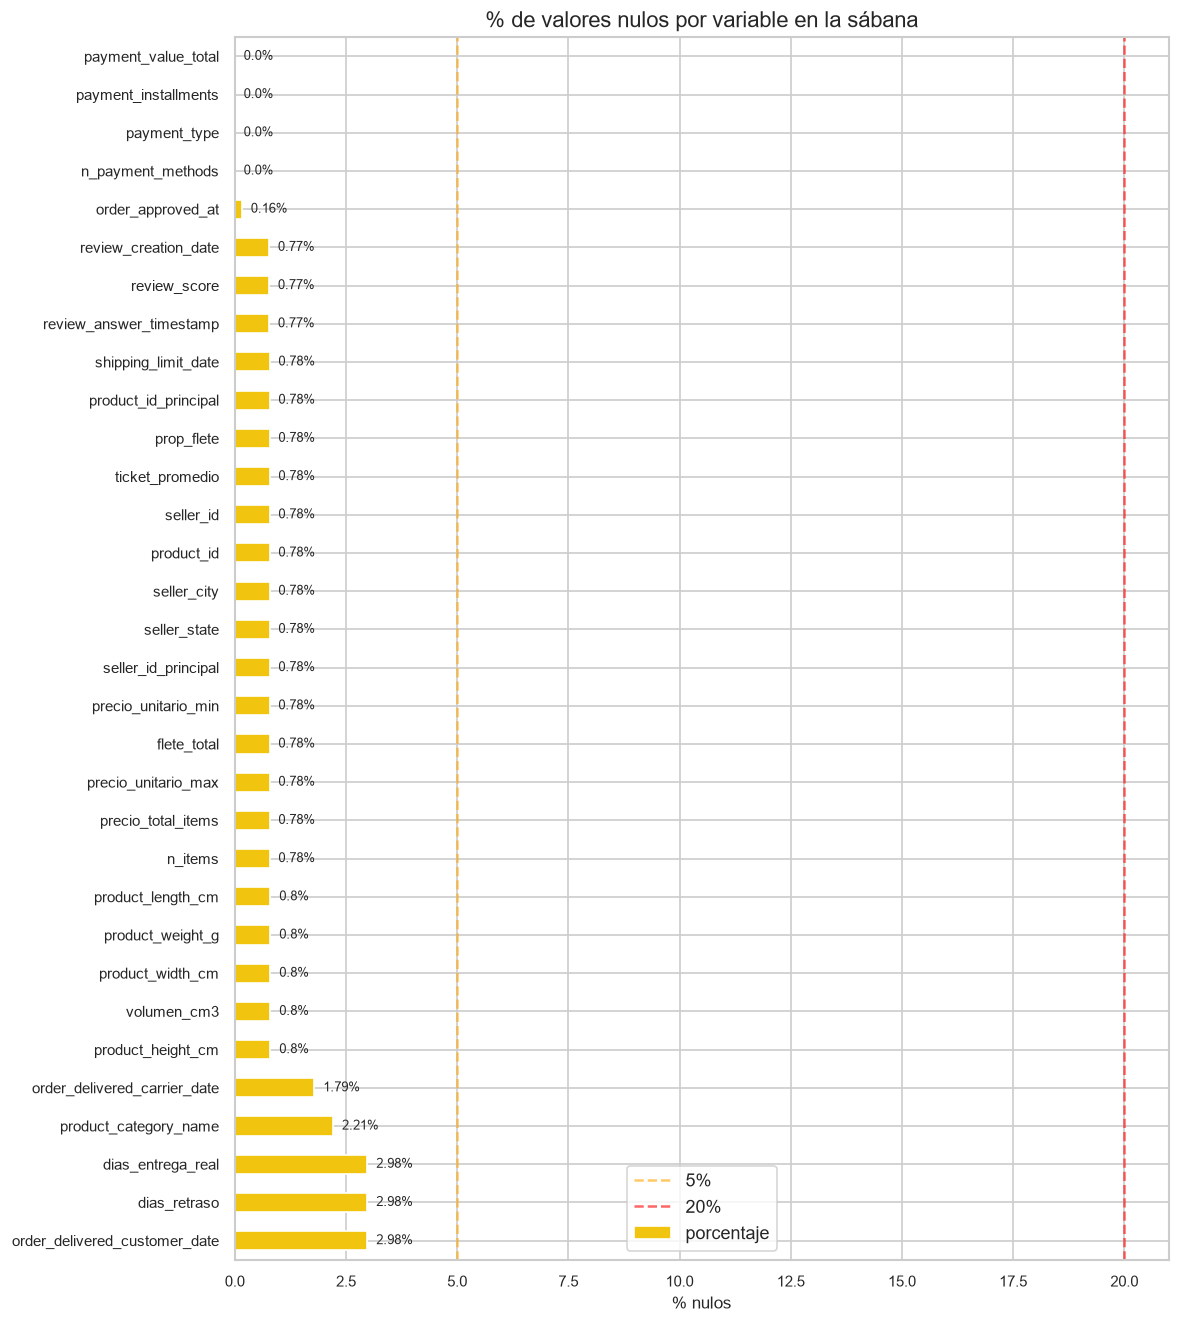

In [17]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 1: VISIÓN GENERAL
# ═══════════════════════════════════════════════════════════════
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.dpi'     : 120,
    'axes.titlesize' : 12,
    'axes.labelsize' : 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})

num_cols = sabana.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = sabana.select_dtypes(include=['object']).columns.tolist()

print(f"Variables numéricas  ({len(num_cols)}): {num_cols}")
print(f"\nVariables categóricas ({len(cat_cols)}): {cat_cols}")

# Mapa de nulos
nulos = pd.DataFrame({
    'nulos'     : sabana.isnull().sum(),
    'porcentaje': (sabana.isnull().sum() / len(sabana) * 100).round(2)
}).query('nulos > 0').sort_values('porcentaje', ascending=False)

print(f"\nVariables con nulos:\n{nulos}")

fig, ax = plt.subplots(figsize=(10, max(4, len(nulos) * 0.35)))
colores = ['#e74c3c' if p > 20 else '#e67e22' if p > 5 else '#f1c40f'
           for p in nulos['porcentaje']]
nulos['porcentaje'].plot(kind='barh', ax=ax, color=colores, edgecolor='white')
ax.set_title('% de valores nulos por variable en la sábana', fontsize=13)
ax.set_xlabel('% nulos')
ax.axvline(5,  color='orange', linestyle='--', alpha=0.6, label='5%')
ax.axvline(20, color='red',    linestyle='--', alpha=0.6, label='20%')
for i, v in enumerate(nulos['porcentaje']):
    ax.text(v + 0.2, i, f'{v}%', va='center', fontsize=8)
ax.legend()
plt.tight_layout()
plt.show()

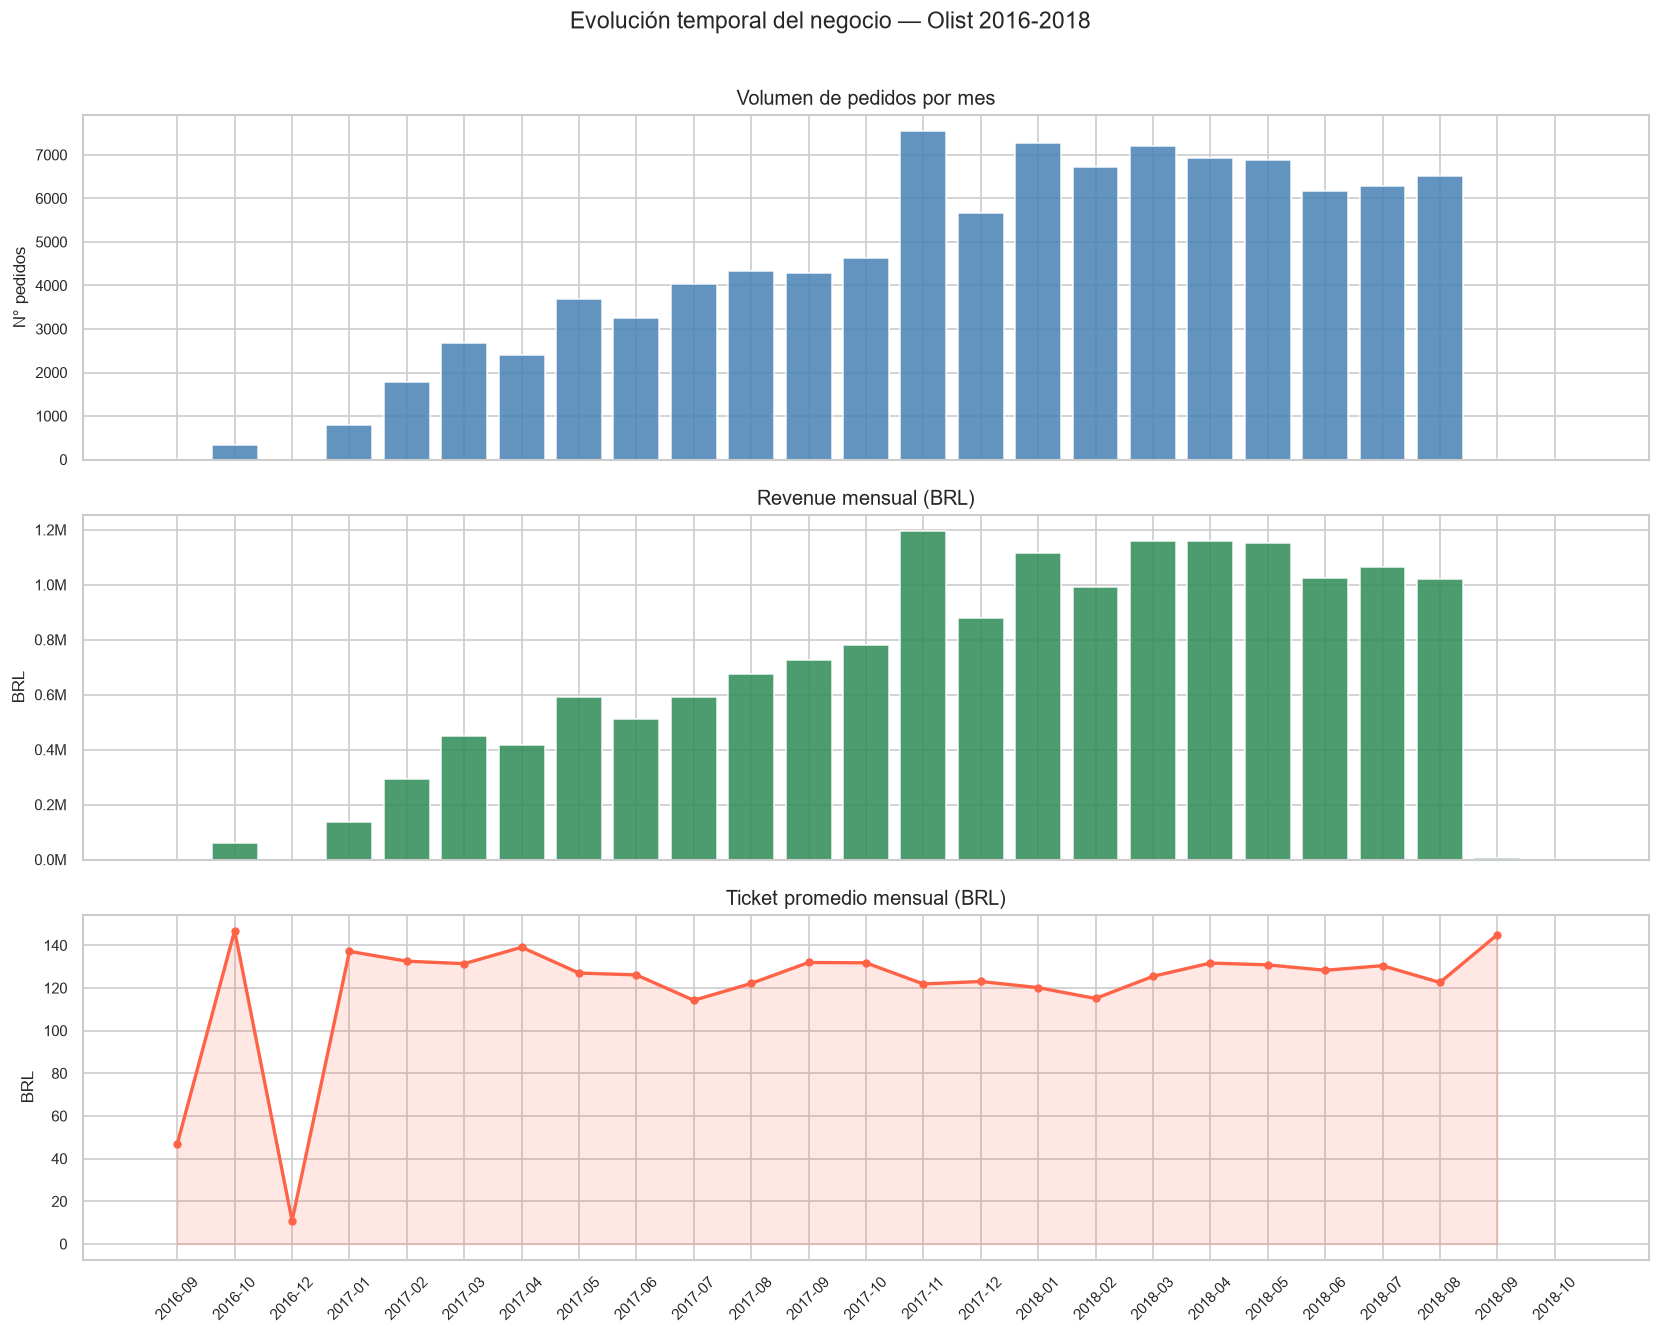


Crecimiento año a año:
             pedidos     revenue  ticket_medio  crec_pedidos_%
anio_compra                                                   
2016             329    59362.34        145.53             NaN
2017           45101  7249746.73        126.26         13608.5
2018           54011  8699763.05        125.52            19.8


In [18]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 2: ANÁLISIS TEMPORAL
# ═══════════════════════════════════════════════════════════════

temporal = sabana.dropna(subset=['order_purchase_timestamp']).copy()
temporal['anio_mes'] = temporal['order_purchase_timestamp'].dt.to_period('M')

pedidos_mes = temporal.groupby('anio_mes').size().reset_index(name='pedidos')
revenue_mes = temporal.groupby('anio_mes')['payment_value_total'].sum().reset_index()
ticket_mes  = temporal.groupby('anio_mes')['ticket_promedio'].mean().reset_index()

# Convertir Period a string para graficar
for df in [pedidos_mes, revenue_mes, ticket_mes]:
    df['anio_mes_str'] = df['anio_mes'].astype(str)

fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)

axes[0].bar(pedidos_mes['anio_mes_str'], pedidos_mes['pedidos'],
            color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Volumen de pedidos por mes')
axes[0].set_ylabel('N° pedidos')

axes[1].bar(revenue_mes['anio_mes_str'], revenue_mes['payment_value_total'],
            color='seagreen', edgecolor='white', alpha=0.85)
axes[1].set_title('Revenue mensual (BRL)')
axes[1].set_ylabel('BRL')
axes[1].yaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

axes[2].plot(ticket_mes['anio_mes_str'], ticket_mes['ticket_promedio'],
             color='tomato', linewidth=2, marker='o', markersize=4)
axes[2].fill_between(range(len(ticket_mes)),
                     ticket_mes['ticket_promedio'],
                     alpha=0.15, color='tomato')
axes[2].set_title('Ticket promedio mensual (BRL)')
axes[2].set_ylabel('BRL')

for ax in axes:
    ax.tick_params(axis='x', rotation=45)

plt.suptitle('Evolución temporal del negocio — Olist 2016-2018',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Crecimiento año a año
por_anio = temporal.groupby('anio_compra').agg(
    pedidos      = ('order_id', 'count'),
    revenue      = ('payment_value_total', 'sum'),
    ticket_medio = ('ticket_promedio', 'mean')
).round(2)
por_anio['crec_pedidos_%'] = por_anio['pedidos'].pct_change().mul(100).round(1)
print("\nCrecimiento año a año:")
print(por_anio)

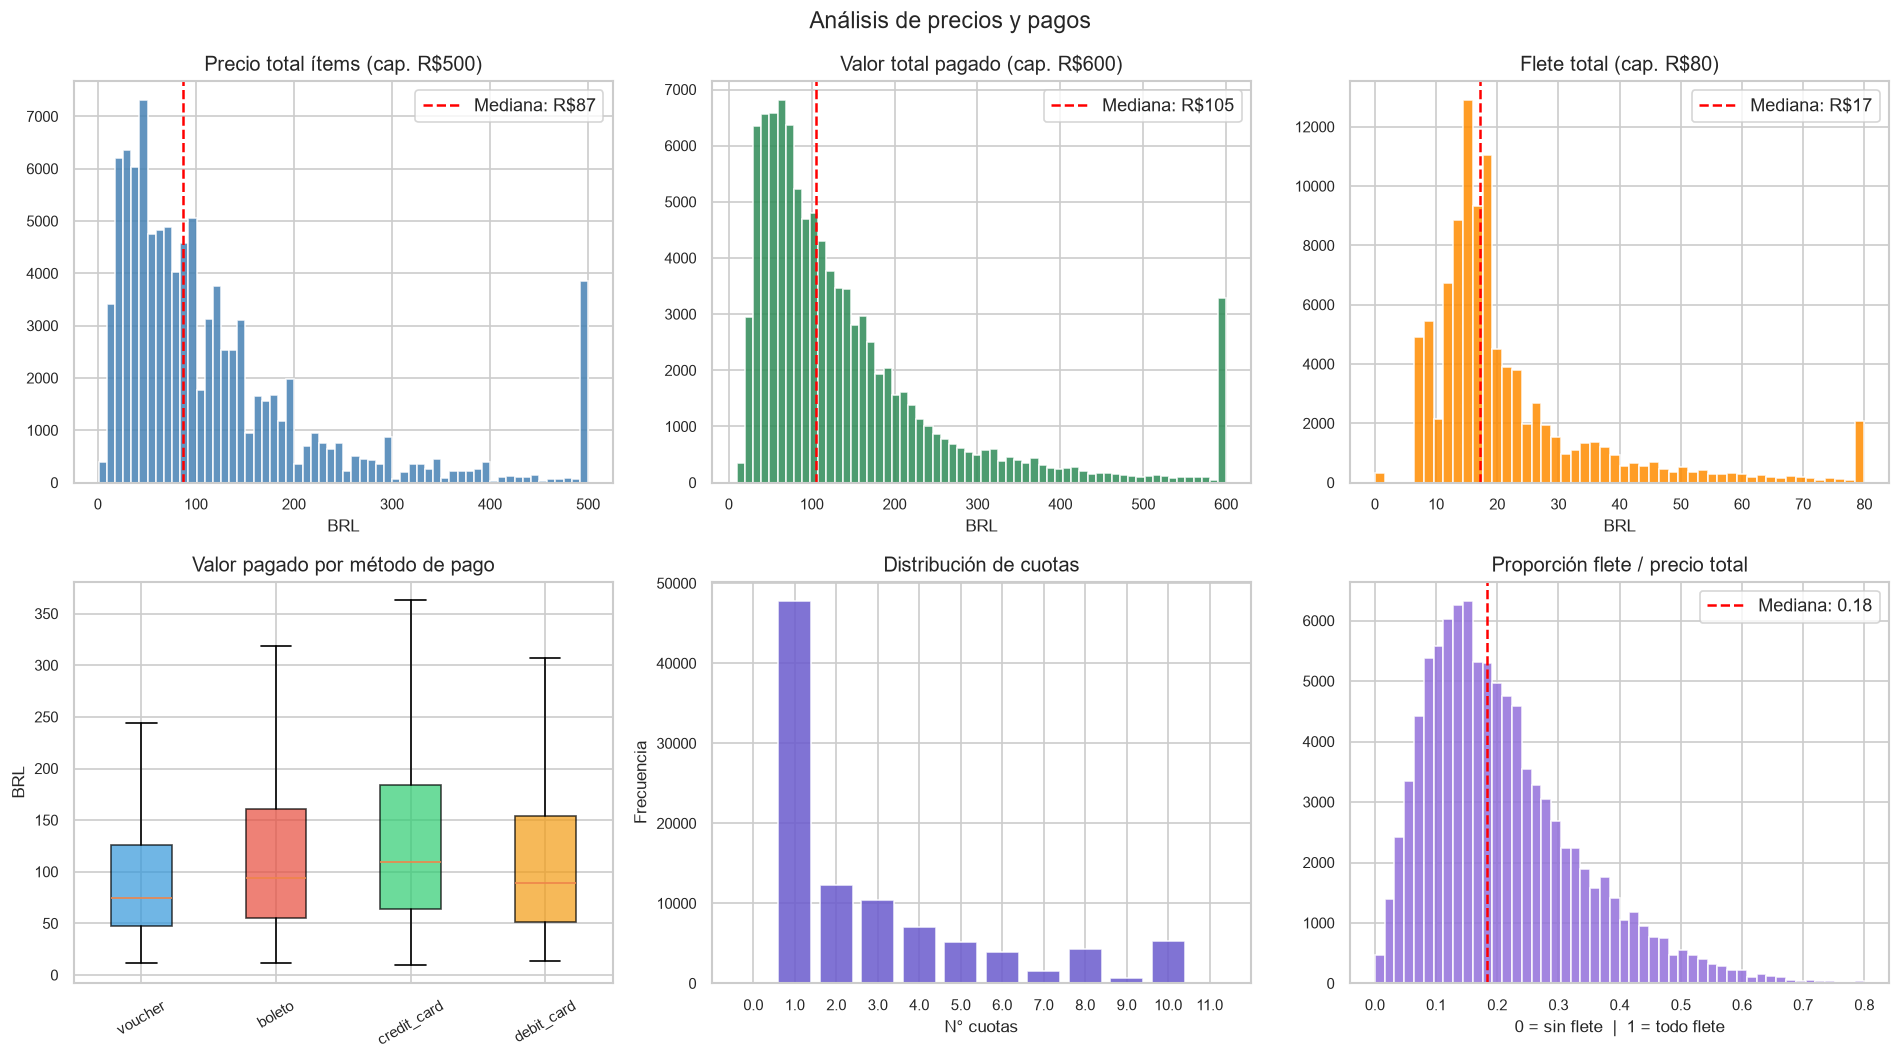


Estadísticos descriptivos — variables de precio:
       precio_total_items  payment_value_total  flete_total  prop_flete  \
count            98665.00             98665.00     98665.00    98665.00   
mean               137.75               160.61        22.82        0.21   
std                210.65               220.48        21.65        0.13   
min                  0.85                 9.59         0.00        0.00   
25%                 45.90                62.00        13.85        0.12   
50%                 86.90               105.29        17.17        0.18   
75%                149.90               176.88        24.04        0.28   
max              13440.00             13664.08      1794.96        0.96   

       payment_installments  
count              98665.00  
mean                   2.93  
std                    2.71  
min                    0.00  
25%                    1.00  
50%                    2.00  
75%                    4.00  
max                   24.00  


In [19]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 3: PRECIOS Y PAGOS
# ═══════════════════════════════════════════════════════════════

df_precio = sabana.dropna(subset=['precio_total_items', 'payment_value_total']).copy()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Histograma precio total ítems
axes[0,0].hist(df_precio['precio_total_items'].clip(upper=500),
               bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0,0].axvline(df_precio['precio_total_items'].median(),
                  color='red', linestyle='--',
                  label=f"Mediana: R${df_precio['precio_total_items'].median():.0f}")
axes[0,0].set_title('Precio total ítems (cap. R$500)')
axes[0,0].set_xlabel('BRL')
axes[0,0].legend()

# Histograma valor pagado
axes[0,1].hist(df_precio['payment_value_total'].clip(upper=600),
               bins=60, color='seagreen', edgecolor='white', alpha=0.85)
axes[0,1].axvline(df_precio['payment_value_total'].median(),
                  color='red', linestyle='--',
                  label=f"Mediana: R${df_precio['payment_value_total'].median():.0f}")
axes[0,1].set_title('Valor total pagado (cap. R$600)')
axes[0,1].set_xlabel('BRL')
axes[0,1].legend()

# Histograma flete
axes[0,2].hist(df_precio['flete_total'].clip(upper=80),
               bins=50, color='darkorange', edgecolor='white', alpha=0.85)
axes[0,2].axvline(df_precio['flete_total'].median(),
                  color='red', linestyle='--',
                  label=f"Mediana: R${df_precio['flete_total'].median():.0f}")
axes[0,2].set_title('Flete total (cap. R$80)')
axes[0,2].set_xlabel('BRL')
axes[0,2].legend()

# Boxplot precio por método de pago
metodos = df_precio['payment_type'].dropna().unique()
data_box = [df_precio[df_precio['payment_type']==m]['payment_value_total']
                .clip(upper=800).dropna().values
            for m in metodos]
bp = axes[1,0].boxplot(data_box, patch_artist=True, showfliers=False)
colores_box = ['#3498db','#e74c3c','#2ecc71','#f39c12']
for patch, color in zip(bp['boxes'], colores_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1,0].set_xticklabels(metodos, rotation=30)
axes[1,0].set_title('Valor pagado por método de pago')
axes[1,0].set_ylabel('BRL')

# Cuotas
cuotas = df_precio['payment_installments'].value_counts().sort_index().head(12)
axes[1,1].bar(cuotas.index.astype(str), cuotas.values,
              color='slateblue', edgecolor='white', alpha=0.85)
axes[1,1].set_title('Distribución de cuotas')
axes[1,1].set_xlabel('N° cuotas')
axes[1,1].set_ylabel('Frecuencia')

# Proporción flete
axes[1,2].hist(df_precio['prop_flete'].dropna().clip(0, 0.8),
               bins=50, color='mediumpurple', edgecolor='white', alpha=0.85)
axes[1,2].axvline(df_precio['prop_flete'].median(),
                  color='red', linestyle='--',
                  label=f"Mediana: {df_precio['prop_flete'].median():.2f}")
axes[1,2].set_title('Proporción flete / precio total')
axes[1,2].set_xlabel('0 = sin flete  |  1 = todo flete')
axes[1,2].legend()

plt.suptitle('Análisis de precios y pagos', fontsize=14)
plt.tight_layout()
plt.show()

print("\nEstadísticos descriptivos — variables de precio:")
print(df_precio[['precio_total_items','payment_value_total',
                 'flete_total','prop_flete',
                 'payment_installments']].describe().round(2))

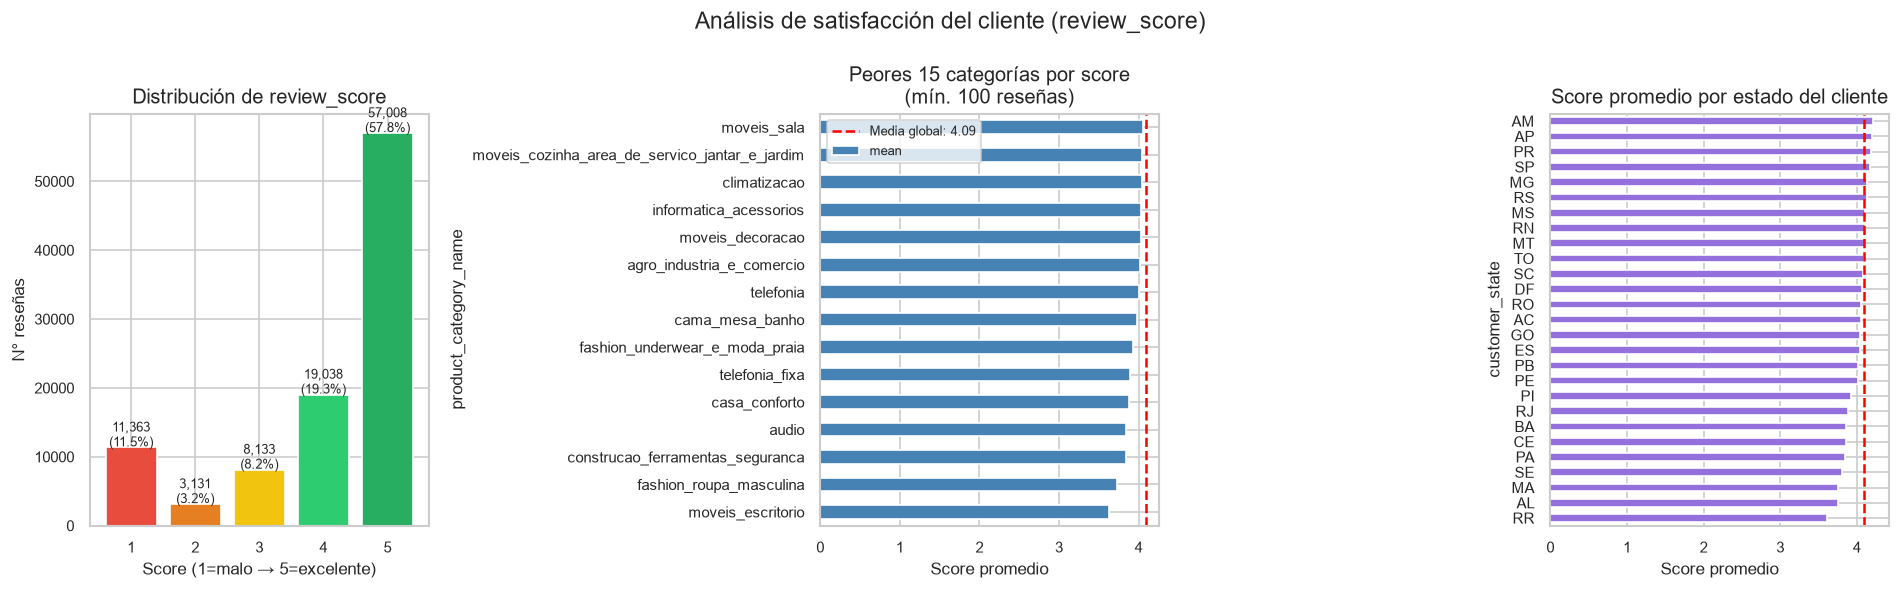


Score promedio global   : 4.086
Score mediana           : 5.0
Reseñas positivas (≥4) : 77.1%
Reseñas negativas (≤2) : 14.7%

Desbalance para clasificación:
resena_positiva
1    77.1
0    22.9
Name: proportion, dtype: float64


In [20]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 4: REVIEW SCORE (target de clasificación)
# ═══════════════════════════════════════════════════════════════

df_rev = sabana.dropna(subset=['review_score']).copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Distribución del score
score_counts = df_rev['review_score'].value_counts().sort_index()
colores_score = ['#e74c3c','#e67e22','#f1c40f','#2ecc71','#27ae60']
bars = axes[0].bar(score_counts.index, score_counts.values,
                   color=colores_score, edgecolor='white')
axes[0].set_title('Distribución de review_score')
axes[0].set_xlabel('Score (1=malo → 5=excelente)')
axes[0].set_ylabel('N° reseñas')
for bar, v in zip(bars, score_counts.values):
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 150,
                 f'{v:,}\n({v/len(df_rev)*100:.1f}%)',
                 ha='center', fontsize=8)

# Peores categorías por score promedio
top_cats = (df_rev.dropna(subset=['product_category_name'])
            .groupby('product_category_name')['review_score']
            .agg(['mean','count'])
            .query('count >= 100')
            .sort_values('mean')
            .head(15))
top_cats['mean'].plot(kind='barh', ax=axes[1], color='steelblue', edgecolor='white')
axes[1].axvline(df_rev['review_score'].mean(), color='red', linestyle='--',
                label=f"Media global: {df_rev['review_score'].mean():.2f}")
axes[1].set_title('Peores 15 categorías por score\n(mín. 100 reseñas)')
axes[1].set_xlabel('Score promedio')
axes[1].legend(fontsize=8)

# Score por estado del cliente
score_estado = (df_rev.dropna(subset=['customer_state'])
                .groupby('customer_state')['review_score']
                .mean().sort_values())
score_estado.plot(kind='barh', ax=axes[2],
                  color='mediumpurple', edgecolor='white')
axes[2].axvline(df_rev['review_score'].mean(), color='red', linestyle='--')
axes[2].set_title('Score promedio por estado del cliente')
axes[2].set_xlabel('Score promedio')

plt.suptitle('Análisis de satisfacción del cliente (review_score)', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nScore promedio global   : {df_rev['review_score'].mean():.3f}")
print(f"Score mediana           : {df_rev['review_score'].median():.1f}")
print(f"Reseñas positivas (≥4) : {(df_rev['review_score']>=4).mean()*100:.1f}%")
print(f"Reseñas negativas (≤2) : {(df_rev['review_score']<=2).mean()*100:.1f}%")
print(f"\nDesbalance para clasificación:")
print(df_rev['resena_positiva'].value_counts(normalize=True).mul(100).round(1))

Pedidos entregados con fechas completas: 96,470


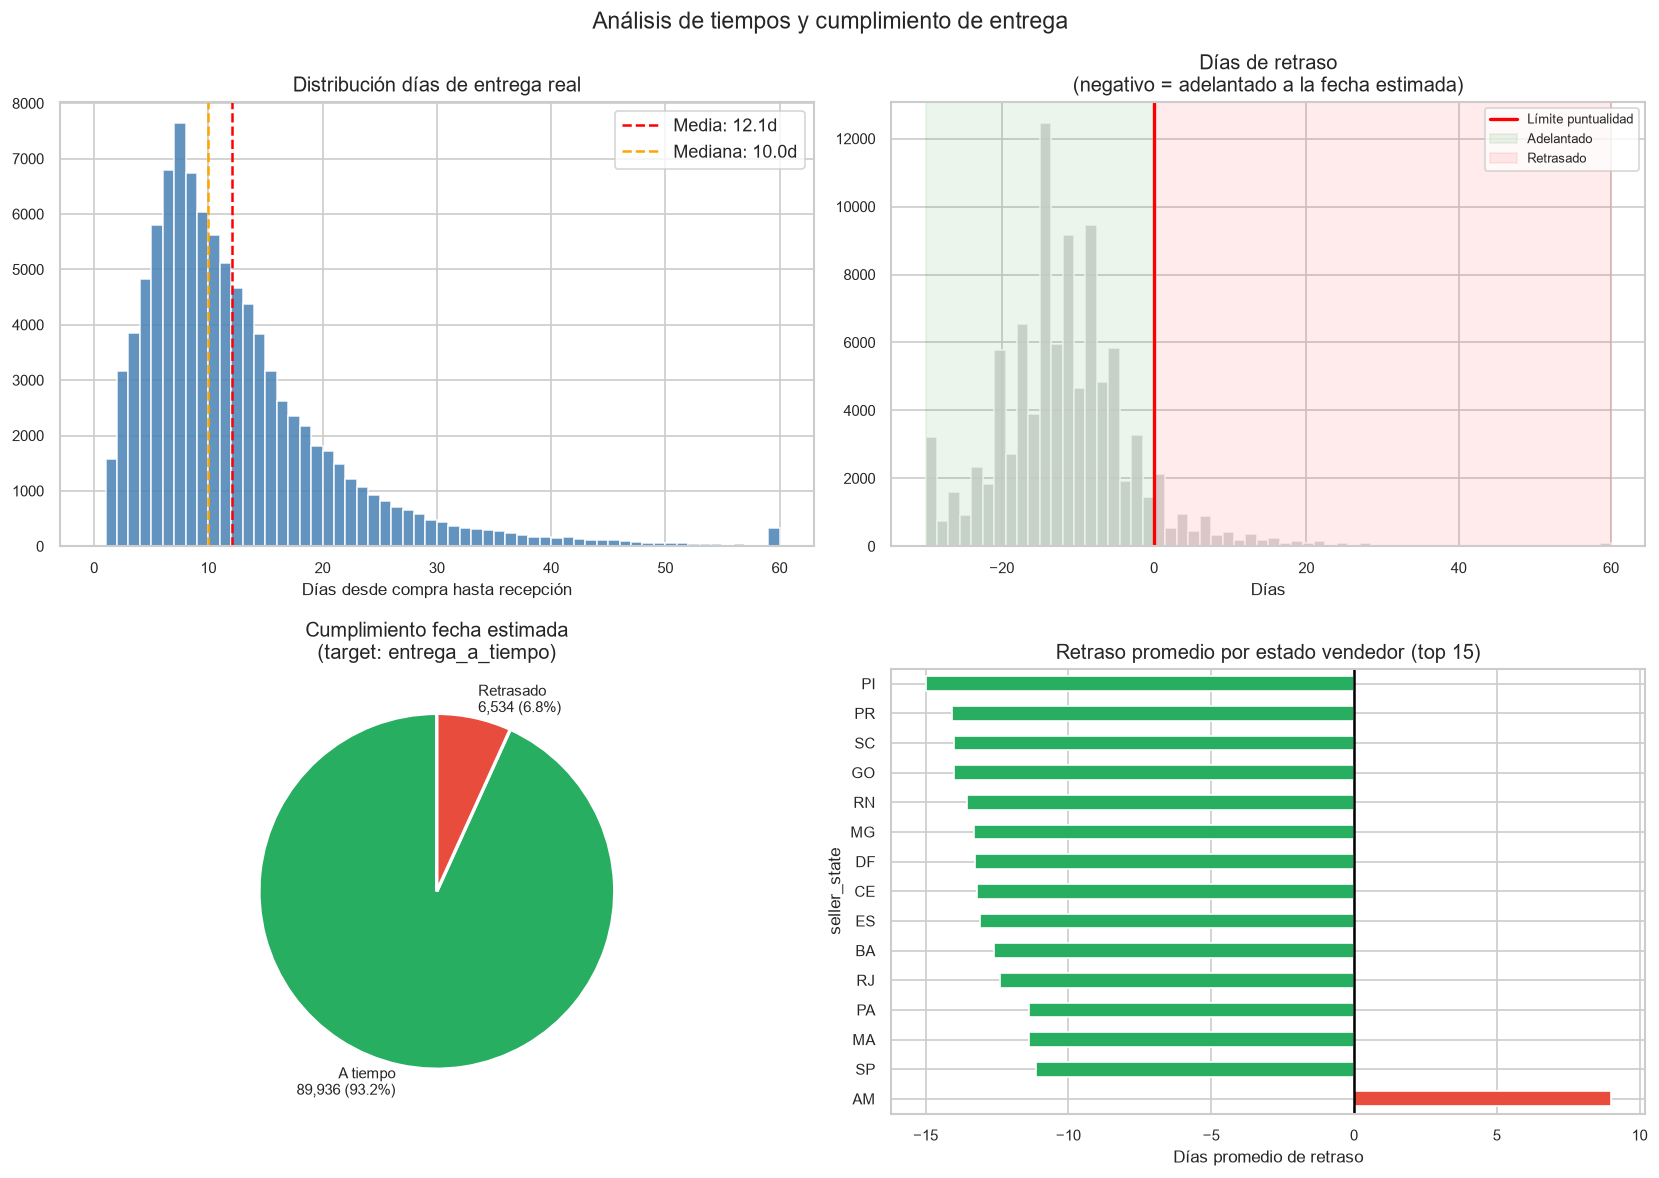


Estadísticos días entrega:
       dias_entrega_real  dias_retraso
count           96470.00      96470.00
mean               12.09        -11.88
std                 9.55         10.18
min                 0.00       -147.00
25%                 6.00        -17.00
50%                10.00        -12.00
75%                15.00         -7.00
max               209.00        188.00


In [21]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 5: TIEMPOS DE ENTREGA (target regresión/clasif.)
# ═══════════════════════════════════════════════════════════════

df_ent = sabana[
    (sabana['order_status'] == 'delivered') &
    sabana['dias_entrega_real'].notna() &
    sabana['dias_retraso'].notna()
].copy()

print(f"Pedidos entregados con fechas completas: {len(df_ent):,}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Distribución días entrega
axes[0,0].hist(df_ent['dias_entrega_real'].clip(0, 60),
               bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0,0].axvline(df_ent['dias_entrega_real'].mean(),   color='red',
                  linestyle='--', label=f"Media: {df_ent['dias_entrega_real'].mean():.1f}d")
axes[0,0].axvline(df_ent['dias_entrega_real'].median(), color='orange',
                  linestyle='--', label=f"Mediana: {df_ent['dias_entrega_real'].median():.1f}d")
axes[0,0].set_title('Distribución días de entrega real')
axes[0,0].set_xlabel('Días desde compra hasta recepción')
axes[0,0].legend()

# Distribución días retraso
axes[0,1].hist(df_ent['dias_retraso'].clip(-30, 60),
               bins=60, color='lightgray', edgecolor='white', alpha=0.85)
axes[0,1].axvline(0, color='red', linewidth=2, label='Límite puntualidad')
axes[0,1].axvspan(-30, 0, alpha=0.08, color='green', label='Adelantado')
axes[0,1].axvspan(  0,60, alpha=0.08, color='red',   label='Retrasado')
axes[0,1].set_title('Días de retraso\n(negativo = adelantado a la fecha estimada)')
axes[0,1].set_xlabel('Días')
axes[0,1].legend(fontsize=8)

# Pie a tiempo vs retrasado
a_tiempo  = (df_ent['dias_retraso'] <= 0).sum()
retrasado = (df_ent['dias_retraso'] >  0).sum()
axes[1,0].pie(
    [a_tiempo, retrasado],
    labels=[f'A tiempo\n{a_tiempo:,} ({a_tiempo/len(df_ent)*100:.1f}%)',
            f'Retrasado\n{retrasado:,} ({retrasado/len(df_ent)*100:.1f}%)'],
    colors=['#27ae60','#e74c3c'],
    startangle=90,
    wedgeprops={'edgecolor':'white','linewidth':2}
)
axes[1,0].set_title('Cumplimiento fecha estimada\n(target: entrega_a_tiempo)')

# Retraso promedio por estado vendedor
retraso_estado = (df_ent.dropna(subset=['seller_state'])
                  .groupby('seller_state')['dias_retraso']
                  .mean()
                  .sort_values(ascending=False)
                  .head(15))
colores_est = ['#e74c3c' if x > 0 else '#27ae60' for x in retraso_estado]
retraso_estado.plot(kind='barh', ax=axes[1,1],
                    color=colores_est, edgecolor='white')
axes[1,1].axvline(0, color='black', linewidth=1.5)
axes[1,1].set_title('Retraso promedio por estado vendedor (top 15)')
axes[1,1].set_xlabel('Días promedio de retraso')

plt.suptitle('Análisis de tiempos y cumplimiento de entrega', fontsize=14)
plt.tight_layout()
plt.show()

print(f"\nEstadísticos días entrega:")
print(df_ent[['dias_entrega_real','dias_retraso']].describe().round(2))

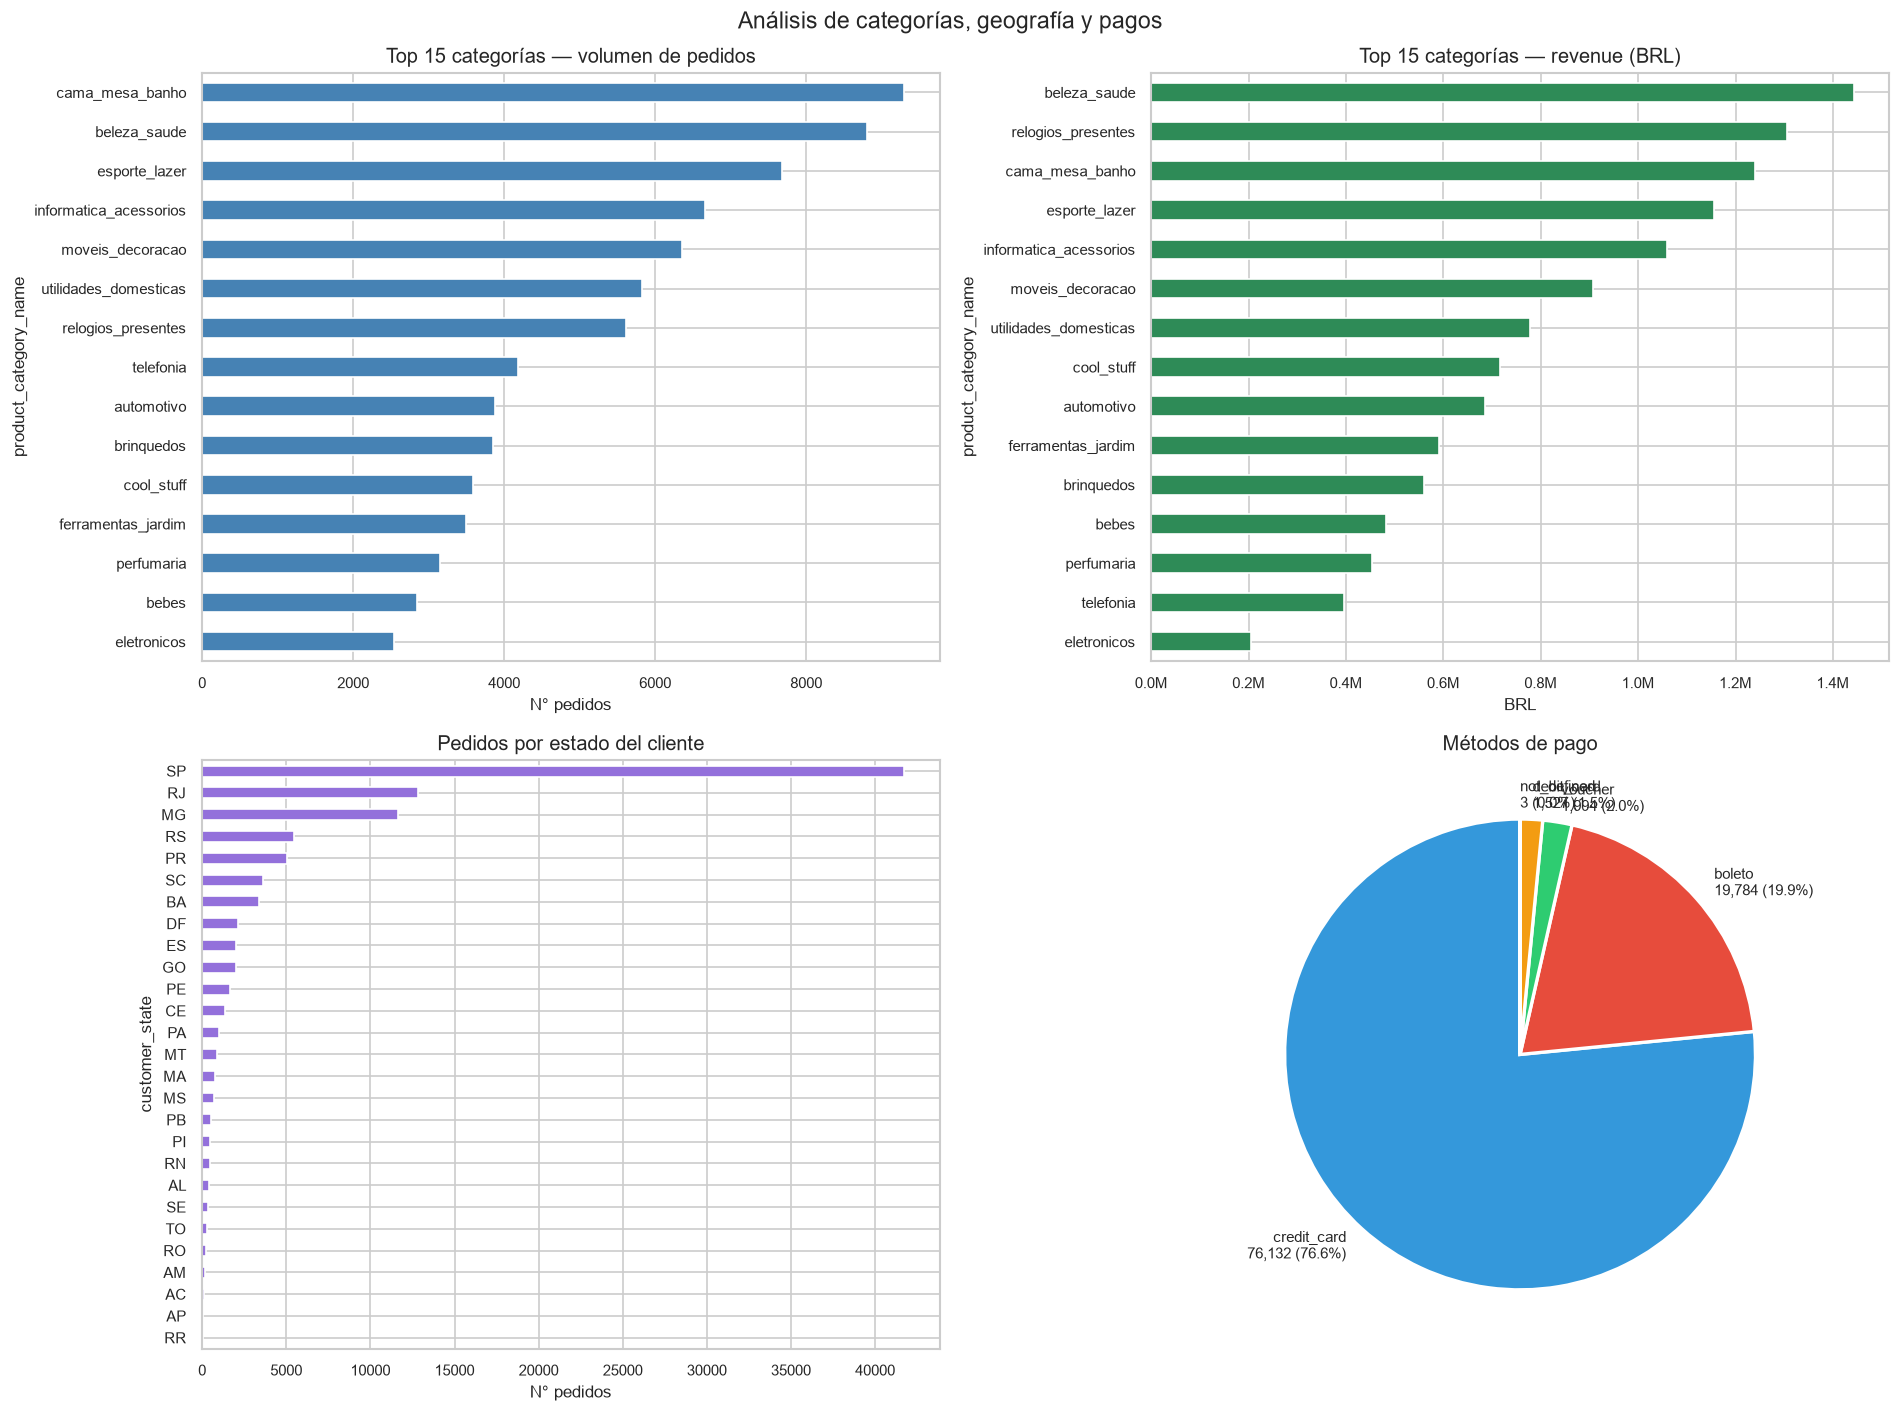

In [22]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 6: CATEGORÍAS
# ═══════════════════════════════════════════════════════════════

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Top 15 categorías por volumen
top15 = (sabana.dropna(subset=['product_category_name'])
         .groupby('product_category_name')
         .agg(pedidos=('order_id','count'),
              revenue=('payment_value_total','sum'))
         .sort_values('pedidos', ascending=False)
         .head(15))

top15.sort_values('pedidos')['pedidos'].plot(
    kind='barh', ax=axes[0,0], color='steelblue', edgecolor='white')
axes[0,0].set_title('Top 15 categorías — volumen de pedidos')
axes[0,0].set_xlabel('N° pedidos')

top15.sort_values('revenue')['revenue'].plot(
    kind='barh', ax=axes[0,1], color='seagreen', edgecolor='white')
axes[0,1].set_title('Top 15 categorías — revenue (BRL)')
axes[0,1].set_xlabel('BRL')
axes[0,1].xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))

# Pedidos por estado del cliente
pedidos_estado = (sabana.groupby('customer_state')
                  .size().sort_values())
pedidos_estado.plot(kind='barh', ax=axes[1,0],
                    color='mediumpurple', edgecolor='white')
axes[1,0].set_title('Pedidos por estado del cliente')
axes[1,0].set_xlabel('N° pedidos')

# Métodos de pago
pago_dist = sabana['payment_type'].value_counts()
axes[1,1].pie(
    pago_dist.values,
    labels=[f'{k}\n{v:,} ({v/pago_dist.sum()*100:.1f}%)'
            for k, v in pago_dist.items()],
    colors=['#3498db','#e74c3c','#2ecc71','#f39c12'],
    startangle=90,
    wedgeprops={'edgecolor':'white','linewidth':2}
)
axes[1,1].set_title('Métodos de pago')

plt.suptitle('Análisis de categorías, geografía y pagos', fontsize=14)
plt.tight_layout()
plt.show()

Registros completos para correlación: 95,813


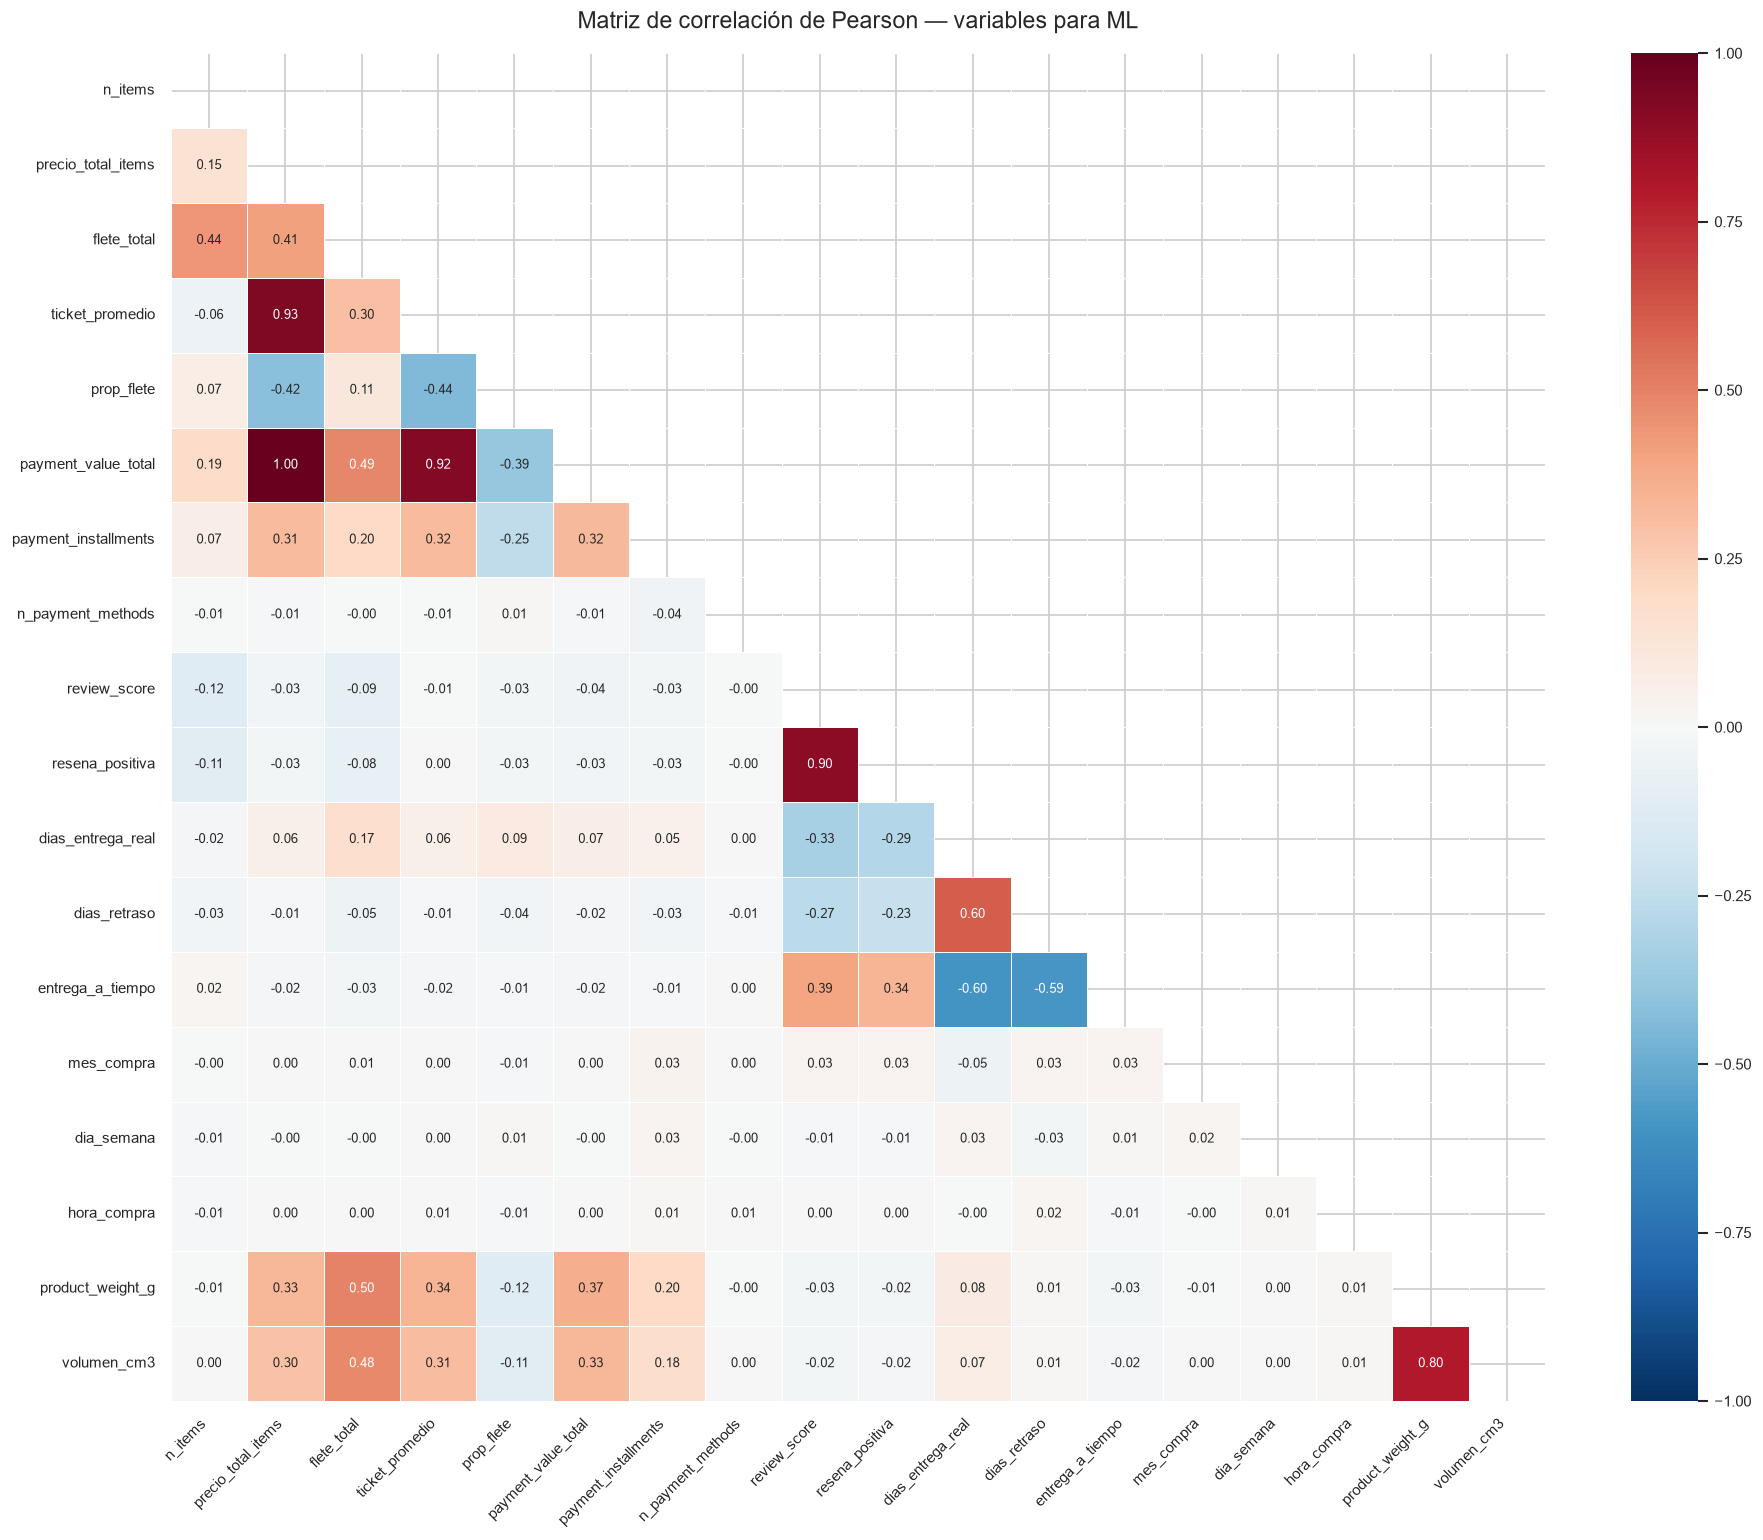

In [23]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 7: MATRIZ DE CORRELACIÓN COMPLETA
# ═══════════════════════════════════════════════════════════════

vars_ml = [
    'n_items', 'precio_total_items', 'flete_total',
    'ticket_promedio', 'prop_flete',
    'payment_value_total', 'payment_installments', 'n_payment_methods',
    'review_score', 'resena_positiva',
    'dias_entrega_real', 'dias_retraso', 'entrega_a_tiempo',
    'mes_compra', 'dia_semana', 'hora_compra',
    'product_weight_g', 'volumen_cm3',
]
vars_ml = [v for v in vars_ml if v in sabana.columns]

df_corr = sabana[vars_ml].dropna()
corr_matrix = df_corr.corr()

print(f"Registros completos para correlación: {len(df_corr):,}")

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask,
    annot=True, fmt='.2f',
    cmap='RdBu_r', center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    annot_kws={'size': 8},
    ax=ax
)
ax.set_title('Matriz de correlación de Pearson — variables para ML',
             fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

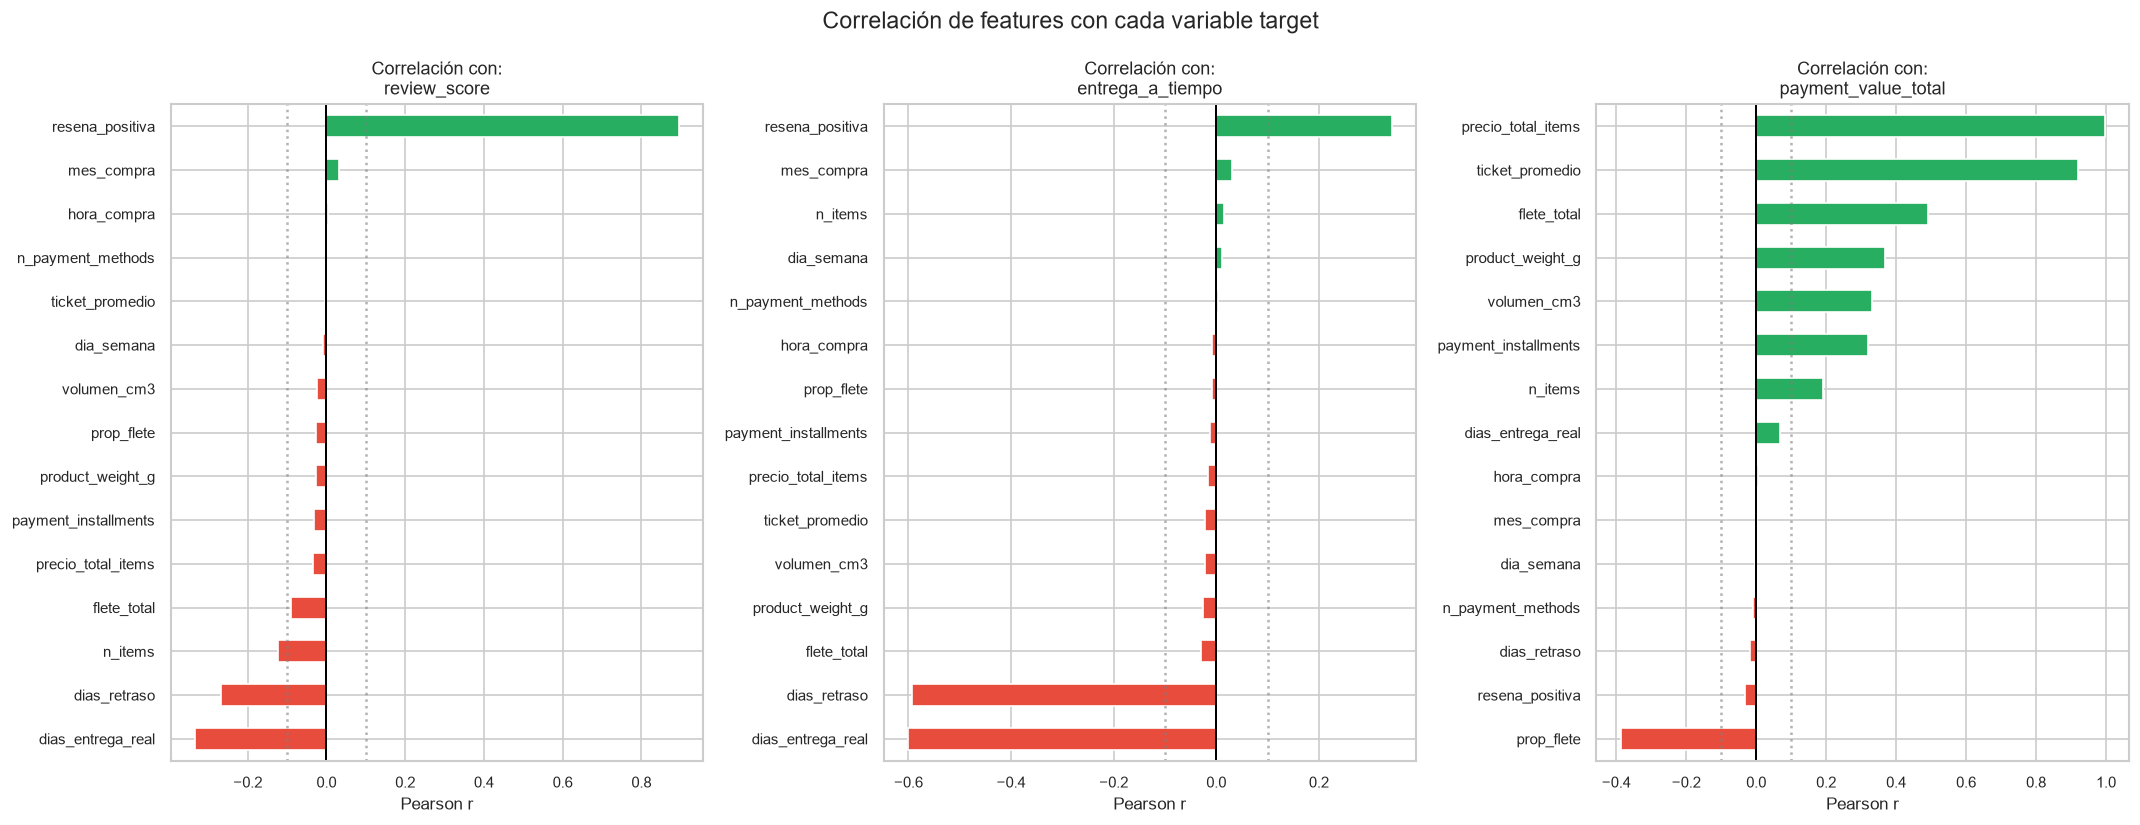


RANKING DE FEATURES POR RELEVANCIA PROMEDIO PARA ML
                      review_score  entrega_a_tiempo  payment_value_total  relevancia_media
resena_positiva              0.895             0.342                0.033             0.423
precio_total_items           0.034             0.016                0.996             0.349
dias_entrega_real            0.334             0.601                0.069             0.335
ticket_promedio              0.005             0.022                0.920             0.316
dias_retraso                 0.267             0.592                0.019             0.293
flete_total                  0.090             0.030                0.491             0.203
prop_flete                   0.027             0.008                0.388             0.141
product_weight_g             0.028             0.026                0.367             0.140
volumen_cm3                  0.024             0.022                0.330             0.126
payment_installments       

In [24]:
# ═══════════════════════════════════════════════════════════════
# EDA — SECCIÓN 8: CORRELACIONES CON CADA TARGET
# Selección de features para ML
# ═══════════════════════════════════════════════════════════════

targets = ['review_score', 'entrega_a_tiempo', 'payment_value_total']

fig, axes = plt.subplots(1, 3, figsize=(18, 7))

for ax, target in zip(axes, targets):
    corr_target = (df_corr.corr()[target]
                   .drop(targets, errors='ignore')
                   .sort_values())
    colores = ['#e74c3c' if v < 0 else '#27ae60' for v in corr_target]
    corr_target.plot(kind='barh', ax=ax, color=colores, edgecolor='white')
    ax.axvline( 0,   color='black', linewidth=1.2)
    ax.axvline( 0.1, color='gray',  linestyle=':', alpha=0.6)
    ax.axvline(-0.1, color='gray',  linestyle=':', alpha=0.6)
    ax.set_title(f'Correlación con:\n{target}', fontsize=11)
    ax.set_xlabel('Pearson r')

plt.suptitle('Correlación de features con cada variable target',
             fontsize=14)
plt.tight_layout()
plt.show()

# Tabla ranking de relevancia
print("\n" + "=" * 60)
print("RANKING DE FEATURES POR RELEVANCIA PROMEDIO PARA ML")
print("=" * 60)
corr_resumen = pd.DataFrame({
    t: df_corr.corr()[t].abs()
    for t in targets if t in df_corr.columns
}).drop(index=[t for t in targets if t in df_corr.columns], errors='ignore')

corr_resumen['relevancia_media'] = corr_resumen.mean(axis=1)
corr_resumen = corr_resumen.sort_values('relevancia_media', ascending=False)
print(corr_resumen.round(3).to_string())

print("""
─────────────────────────────────────────────────────────
CONCLUSIONES PARA SELECCIÓN DE FEATURES
─────────────────────────────────────────────────────────
Para predecir review_score (regresión / clasificación):
  → dias_retraso, entrega_a_tiempo, flete_total, prop_flete

Para predecir entrega_a_tiempo (clasificación binaria):
  → dias_retraso, precio_total_items, n_items, product_weight_g

Para regresión de precio (payment_value_total):
  → n_items, precio_total_items, volumen_cm3, payment_installments

NOTA: Pearson captura relaciones LINEALES solamente.
En la siguiente etapa usaremos Random Forest cuyo feature
importance captura también relaciones no lineales.
─────────────────────────────────────────────────────────
""")

## Flujo para implementación de aprendizaje automático. 

A continuación se detalla el flujo que hemos realizado y los procesos adicionales hasta la valoración de modelos. Los procesos de feature engineering y modelado se realizan en cada apartado de los módelos explicados. Se deja una nota al inicio, considerando que depende de los hallazgos del modelo arriba, aplicamos ciertos ajustes como se verán a continuación. Para todos los modelos seguimos este flujo de limpieza, ajuste y adecuación de los modelos, así como entrenamiento en cada celda hasta interpretar resultados. 

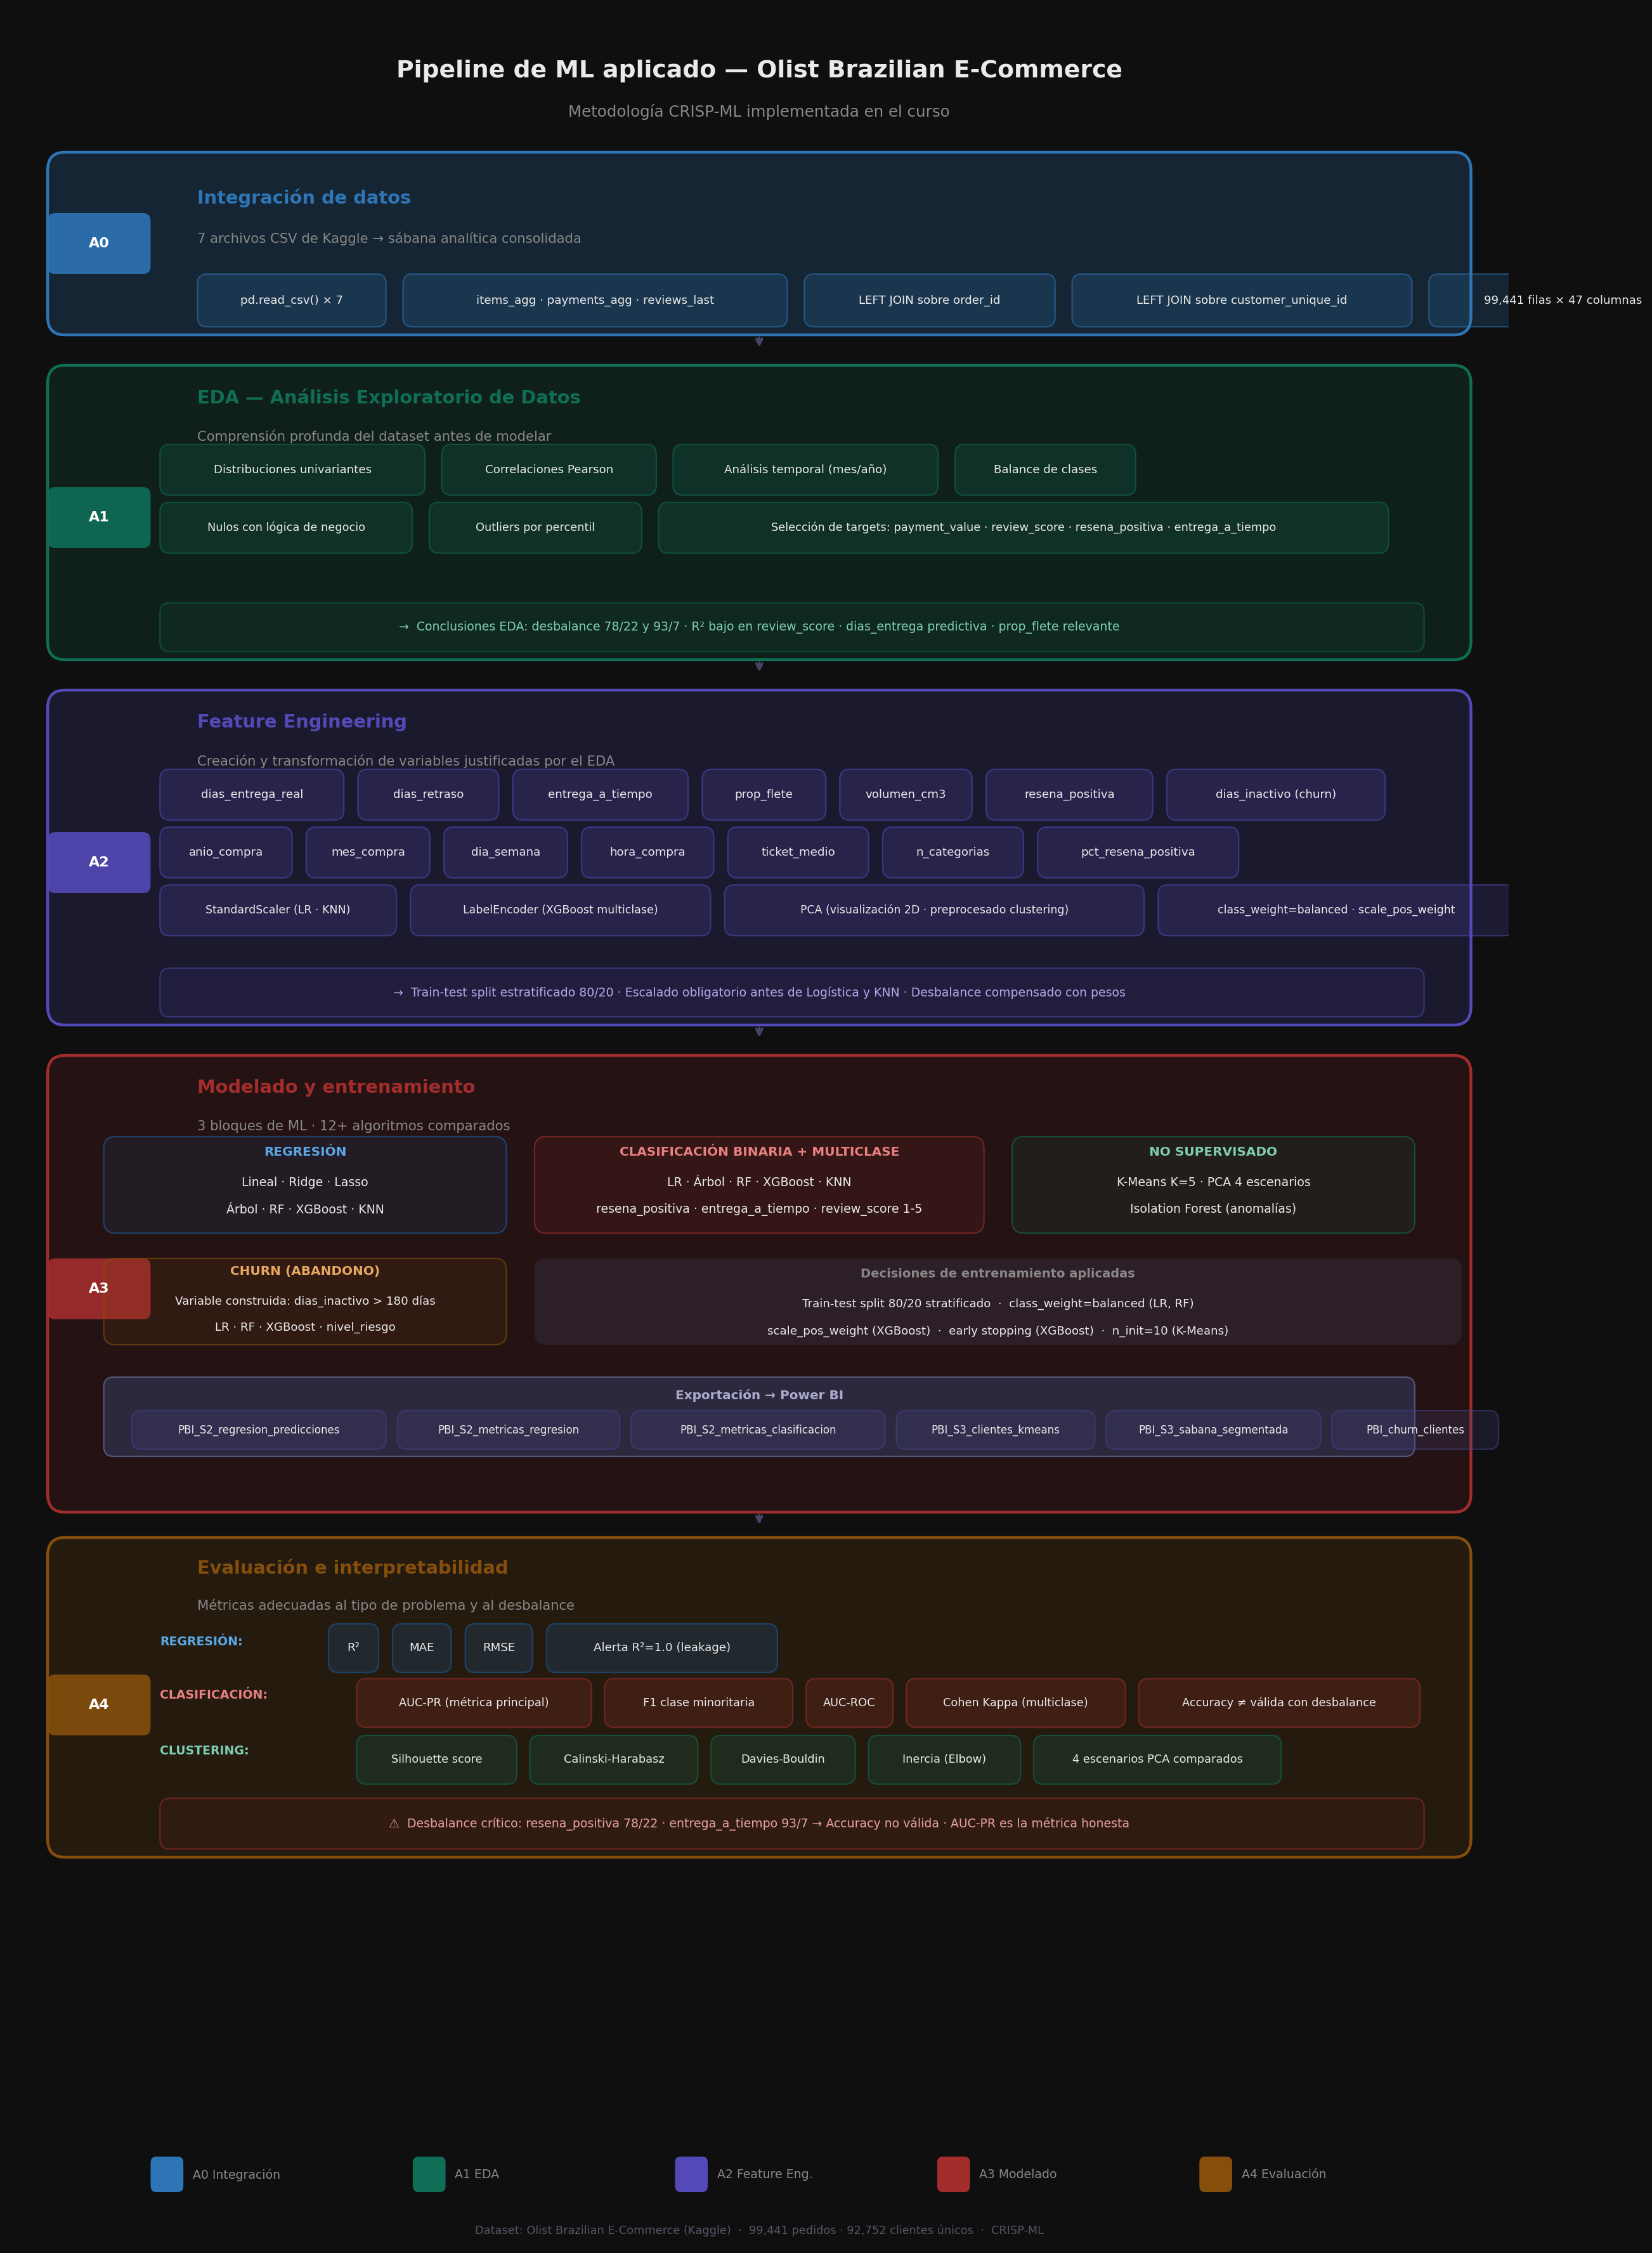

# Selección de modelos de ML para predecir variables críticas del negocio. 

Iniciaremos con modelos de regresión para dos variables de alta relevancia en el negocio, por el modelo más sencillo de aplicación de ML, la regresión lineal simple. 

## ¿Qué es la regresión lineal?
Es el modelo supervisado más fundamental. Dado un conjunto de variables independientes (features) X, aprende una función lineal que predice una variable continua y minimizando el error cuadrático medio entre los valores reales y los predichos.

A diferencia de clasificación, el output no es una categoría sino un número real — en nuestro caso: el valor total pagado por un pedido o su score de reseña.

##                                          Fórmula Geneal

ŷ = β₀ + β₁x₁ + β₂x₂ + ... + βₙxₙ + ε

ŷ
Valor predicho (output del modelo)

β₀
Intercepto — valor de ŷ cuando todo X=0

βᵢ
Coeficiente — cuánto cambia ŷ por unidad de xᵢ

xᵢ
Feature / variable independiente

ε
Error residual — lo que el modelo no explica

n
Número de features (predictores)

## Función de costo — Mínimos cuadrados ordinarios (OLS)
El modelo aprende los β minimizando la suma de errores al cuadrado:

MSE = (1/m) · Σᵢ (yᵢ - ŷᵢ)²

Al cuadrado porque: (1) penaliza más los errores grandes, (2) hace que errores positivos y negativos no se cancelen, (3) la función es diferenciable y tiene solución analítica exacta.


## Construcción modelos problema OLIST

In [25]:
pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -------------------------------------- - 8.1/8.4 MB 72.1 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 72.1 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 18.8 MB/s  0:00:00

   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narwhals]
   -------- ------------------------------- 1/5 [narw


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [26]:
# Importamos librerías para nuestro modelo. 

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("""
╔══════════════════════════════════════════════════════════════╗
║         REGRESIÓN LINEAL MÚLTIPLE — OLIST                   ║
║  Pregunta: ¿Podemos predecir cuánto pagará un cliente?      ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║         REGRESIÓN LINEAL MÚLTIPLE — OLIST                   ║
║  Pregunta: ¿Podemos predecir cuánto pagará un cliente?      ║
╚══════════════════════════════════════════════════════════════╝



In [27]:
# ──────────────────────────────────────────────────────────────
# MODELO 1: Predicción de payment_value_total
# ──────────────────────────────────────────────────────────────

# 1. Preparación
features_precio = [
    'precio_total_items',    # valor de los productos (r≈0.98 con target)
    'n_items',               # cantidad de ítems del pedido
    'flete_total',           # costo de envío (r≈0.44)
    'payment_installments',  # número de cuotas
    'volumen_cm3',           # volumen del producto
    'product_weight_g',      # peso del producto
    'mes_compra',            # estacionalidad
    'dia_semana',            # día de compra
]
TARGET_1 = 'payment_value_total'

df_m1 = sabana[features_precio + [TARGET_1]].dropna()
print(f"Modelo 1 — registros disponibles: {len(df_m1):,}")
print(f"Target: {TARGET_1}")
print(f"  Media  : R$ {df_m1[TARGET_1].mean():.2f}")
print(f"  Mediana: R$ {df_m1[TARGET_1].median():.2f}")
print(f"  Std    : R$ {df_m1[TARGET_1].std():.2f}")

X1 = df_m1[features_precio]
y1 = df_m1[TARGET_1]

# 2. Split estratificado por cuantiles del target
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42
)
print(f"\nTrain: {len(X1_train):,}  |  Test: {len(X1_test):,}")

# 3. Escalado | Feature Engineering (escalado de variables)
scaler1 = StandardScaler()
X1_train_sc = scaler1.fit_transform(X1_train)
X1_test_sc  = scaler1.transform(X1_test)

# 4. Entrenamiento | Modelado
lr1 = LinearRegression()
lr1.fit(X1_train_sc, y1_train)

# 5. Predicción y métricas | Predicciones y evaluación
y1_pred = lr1.predict(X1_test_sc)

mae1  = mean_absolute_error(y1_test, y1_pred)
rmse1 = np.sqrt(mean_squared_error(y1_test, y1_pred))
r2_1  = r2_score(y1_test, y1_pred)
mape1 = np.mean(np.abs((y1_test - y1_pred) / y1_test.clip(lower=1))) * 100

print(f"""
RESULTADOS — Modelo 1: payment_value_total
{'─'*45}
  R²   = {r2_1:.4f}  → el modelo explica el {r2_1*100:.1f}% de la varianza
  MAE  = R$ {mae1:.2f}  → error promedio absoluto
  RMSE = R$ {rmse1:.2f}  → penaliza más los errores grandes
  MAPE = {mape1:.1f}%    → error porcentual promedio
""")

# 6. Coeficientes interpretables
coefs1 = pd.DataFrame({
    'feature'    : features_precio,
    'coeficiente': lr1.coef_,
}).sort_values('coeficiente', key=abs, ascending=False)
print("Coeficientes (estandarizados — comparables entre sí):")
print(coefs1.to_string(index=False))
print(f"Intercepto: {lr1.intercept_:.4f}")
print("""
Interpretación: el coeficiente estandarizado indica cuántos BRL
cambia el precio pagado si esa feature sube 1 desviación estándar,
manteniendo todo lo demás constante.
""")

Modelo 1 — registros disponibles: 98,649
Target: payment_value_total
  Media  : R$ 160.60
  Mediana: R$ 105.29
  Std    : R$ 220.42

Train: 78,919  |  Test: 19,730

RESULTADOS — Modelo 1: payment_value_total
─────────────────────────────────────────────
  R²   = 1.0000  → el modelo explica el 100.0% de la varianza
  MAE  = R$ 0.08  → error promedio absoluto
  RMSE = R$ 0.86  → penaliza más los errores grandes
  MAPE = 0.1%    → error porcentual promedio

Coeficientes (estandarizados — comparables entre sí):
             feature  coeficiente
  precio_total_items   211.431796
         flete_total    21.875038
payment_installments     0.080858
          mes_compra    -0.015589
    product_weight_g     0.009001
             n_items     0.003542
         volumen_cm3    -0.002068
          dia_semana     0.001437
Intercepto: 161.0508

Interpretación: el coeficiente estandarizado indica cuántos BRL
cambia el precio pagado si esa feature sube 1 desviación estándar,
manteniendo todo lo demás co

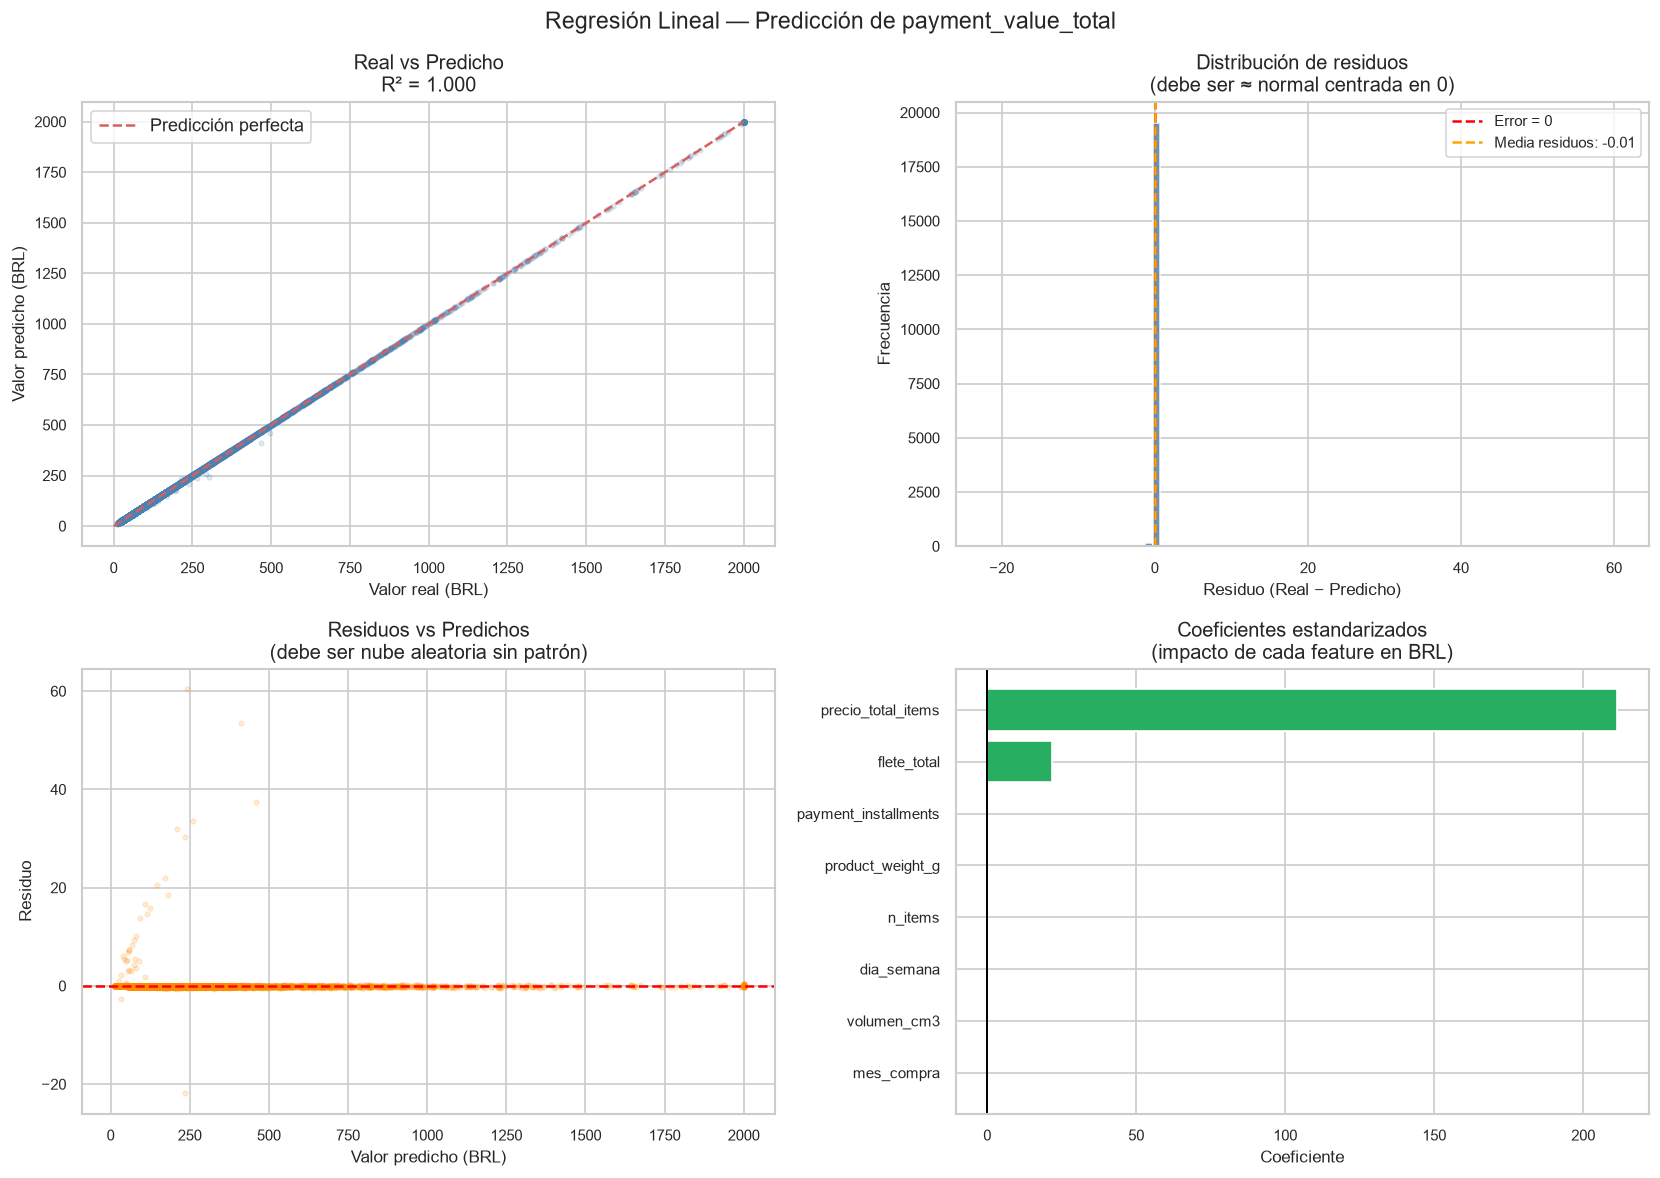

In [28]:
# 7. Visualizaciones Modelo 1
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 7.1 Valores reales vs predichos
lim = min(y1_test.max(), y1_pred.max(), 2000)
axes[0,0].scatter(y1_test.clip(upper=lim),
                  np.clip(y1_pred, 0, lim),
                  alpha=0.15, s=8, color='steelblue')
axes[0,0].plot([0, lim], [0, lim], 'r--', lw=1.5, label='Predicción perfecta')
axes[0,0].set_xlabel('Valor real (BRL)')
axes[0,0].set_ylabel('Valor predicho (BRL)')
axes[0,0].set_title(f'Real vs Predicho\nR² = {r2_1:.3f}')
axes[0,0].legend()

# 7.2 Distribución de residuos
residuos1 = y1_test - y1_pred
axes[0,1].hist(residuos1.clip(-500, 500), bins=80,
               color='steelblue', edgecolor='white', alpha=0.85)
axes[0,1].axvline(0, color='red', linestyle='--', lw=1.5, label='Error = 0')
axes[0,1].axvline(residuos1.mean(), color='orange', linestyle='--', lw=1.5,
                  label=f'Media residuos: {residuos1.mean():.2f}')
axes[0,1].set_xlabel('Residuo (Real − Predicho)')
axes[0,1].set_ylabel('Frecuencia')
axes[0,1].set_title('Distribución de residuos\n(debe ser ≈ normal centrada en 0)')
axes[0,1].legend(fontsize=9)

# 7.3 Residuos vs predichos (homocedasticidad)
axes[1,0].scatter(np.clip(y1_pred, 0, lim), residuos1.clip(-500, 500),
                  alpha=0.15, s=8, color='darkorange')
axes[1,0].axhline(0, color='red', linestyle='--', lw=1.5)
axes[1,0].set_xlabel('Valor predicho (BRL)')
axes[1,0].set_ylabel('Residuo')
axes[1,0].set_title('Residuos vs Predichos\n(debe ser nube aleatoria sin patrón)')

# 7.4 Importancia de features (coeficientes absolutos)
coefs1_sorted = coefs1.sort_values('coeficiente')
colores = ['#e74c3c' if v < 0 else '#27ae60' for v in coefs1_sorted['coeficiente']]
axes[1,1].barh(coefs1_sorted['feature'],
               coefs1_sorted['coeficiente'],
               color=colores, edgecolor='white')
axes[1,1].axvline(0, color='black', lw=1.2)
axes[1,1].set_title('Coeficientes estandarizados\n(impacto de cada feature en BRL)')
axes[1,1].set_xlabel('Coeficiente')

plt.suptitle('Regresión Lineal — Predicción de payment_value_total',
             fontsize=14)
plt.tight_layout()
plt.show()

In [29]:
# ──────────────────────────────────────────────────────────────
# MODELO 2: Predicción de review_score
# ──────────────────────────────────────────────────────────────
print("""
╔══════════════════════════════════════════════════════════════╗
║  Modelo 2: Regresión Lineal — review_score                  ║
║  Pregunta: ¿Podemos predecir la satisfacción del cliente?   ║
╚══════════════════════════════════════════════════════════════╝
NOTA: Excluimos 'resena_positiva' porque es derivada del target
(sería data leakage — el modelo "trampearía" con esa variable).
""")

# Features — SIN resena_positiva (leakage) y SIN dias_retraso si
# queremos predecir antes de que ocurra la entrega
features_score = [
    'dias_retraso',          # días de retraso (disponible post-entrega)
    'flete_total',           # costo de envío — genera fricción
    'prop_flete',            # proporción flete/precio
    'n_items',               # complejidad del pedido
    'precio_total_items',    # valor del pedido
    'payment_installments',  # cuotas — proxy de esfuerzo financiero
    'dias_entrega_real',     # días totales de espera
    'product_weight_g',      # peso → impacta logística
]
TARGET_2 = 'review_score'

df_m2 = sabana[features_score + [TARGET_2]].dropna()
print(f"Modelo 2 — registros disponibles: {len(df_m2):,}")
print(f"\nDistribución del target review_score:")
print(df_m2[TARGET_2].value_counts().sort_index())

X2 = df_m2[features_score]
y2 = df_m2[TARGET_2]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

scaler2 = StandardScaler()
X2_train_sc = scaler2.fit_transform(X2_train)
X2_test_sc  = scaler2.transform(X2_test)

lr2 = LinearRegression()
lr2.fit(X2_train_sc, y2_train)
y2_pred = lr2.predict(X2_test_sc)

# Clampear predicciones al rango válido [1, 5]
y2_pred_clamp = np.clip(y2_pred, 1, 5)

mae2  = mean_absolute_error(y2_test, y2_pred_clamp)
rmse2 = np.sqrt(mean_squared_error(y2_test, y2_pred_clamp))
r2_2  = r2_score(y2_test, y2_pred_clamp)

print(f"""
RESULTADOS — Modelo 2: review_score
{'─'*45}
  R²   = {r2_2:.4f}  → el modelo explica el {r2_2*100:.1f}% de la varianza
  MAE  = {mae2:.4f} puntos (escala 1-5)
  RMSE = {rmse2:.4f} puntos

  ⚠ R² bajo era ESPERADO — lo justificamos a continuación.
""")

coefs2 = pd.DataFrame({
    'feature'    : features_score,
    'coeficiente': lr2.coef_,
}).sort_values('coeficiente', key=abs, ascending=False)
print("Coeficientes:")
print(coefs2.to_string(index=False))


╔══════════════════════════════════════════════════════════════╗
║  Modelo 2: Regresión Lineal — review_score                  ║
║  Pregunta: ¿Podemos predecir la satisfacción del cliente?   ║
╚══════════════════════════════════════════════════════════════╝
NOTA: Excluimos 'resena_positiva' porque es derivada del target
(sería data leakage — el modelo "trampearía" con esa variable).

Modelo 2 — registros disponibles: 95,813

Distribución del target review_score:
review_score
1.0     9352
2.0     2920
3.0     7917
4.0    18887
5.0    56737
Name: count, dtype: int64

RESULTADOS — Modelo 2: review_score
─────────────────────────────────────────────
  R²   = 0.1480  → el modelo explica el 14.8% de la varianza
  MAE  = 0.9091 puntos (escala 1-5)
  RMSE = 1.1787 puntos

  ⚠ R² bajo era ESPERADO — lo justificamos a continuación.

Coeficientes:
             feature  coeficiente
   dias_entrega_real    -0.358573
             n_items    -0.181333
        dias_retraso    -0.135365
         flete

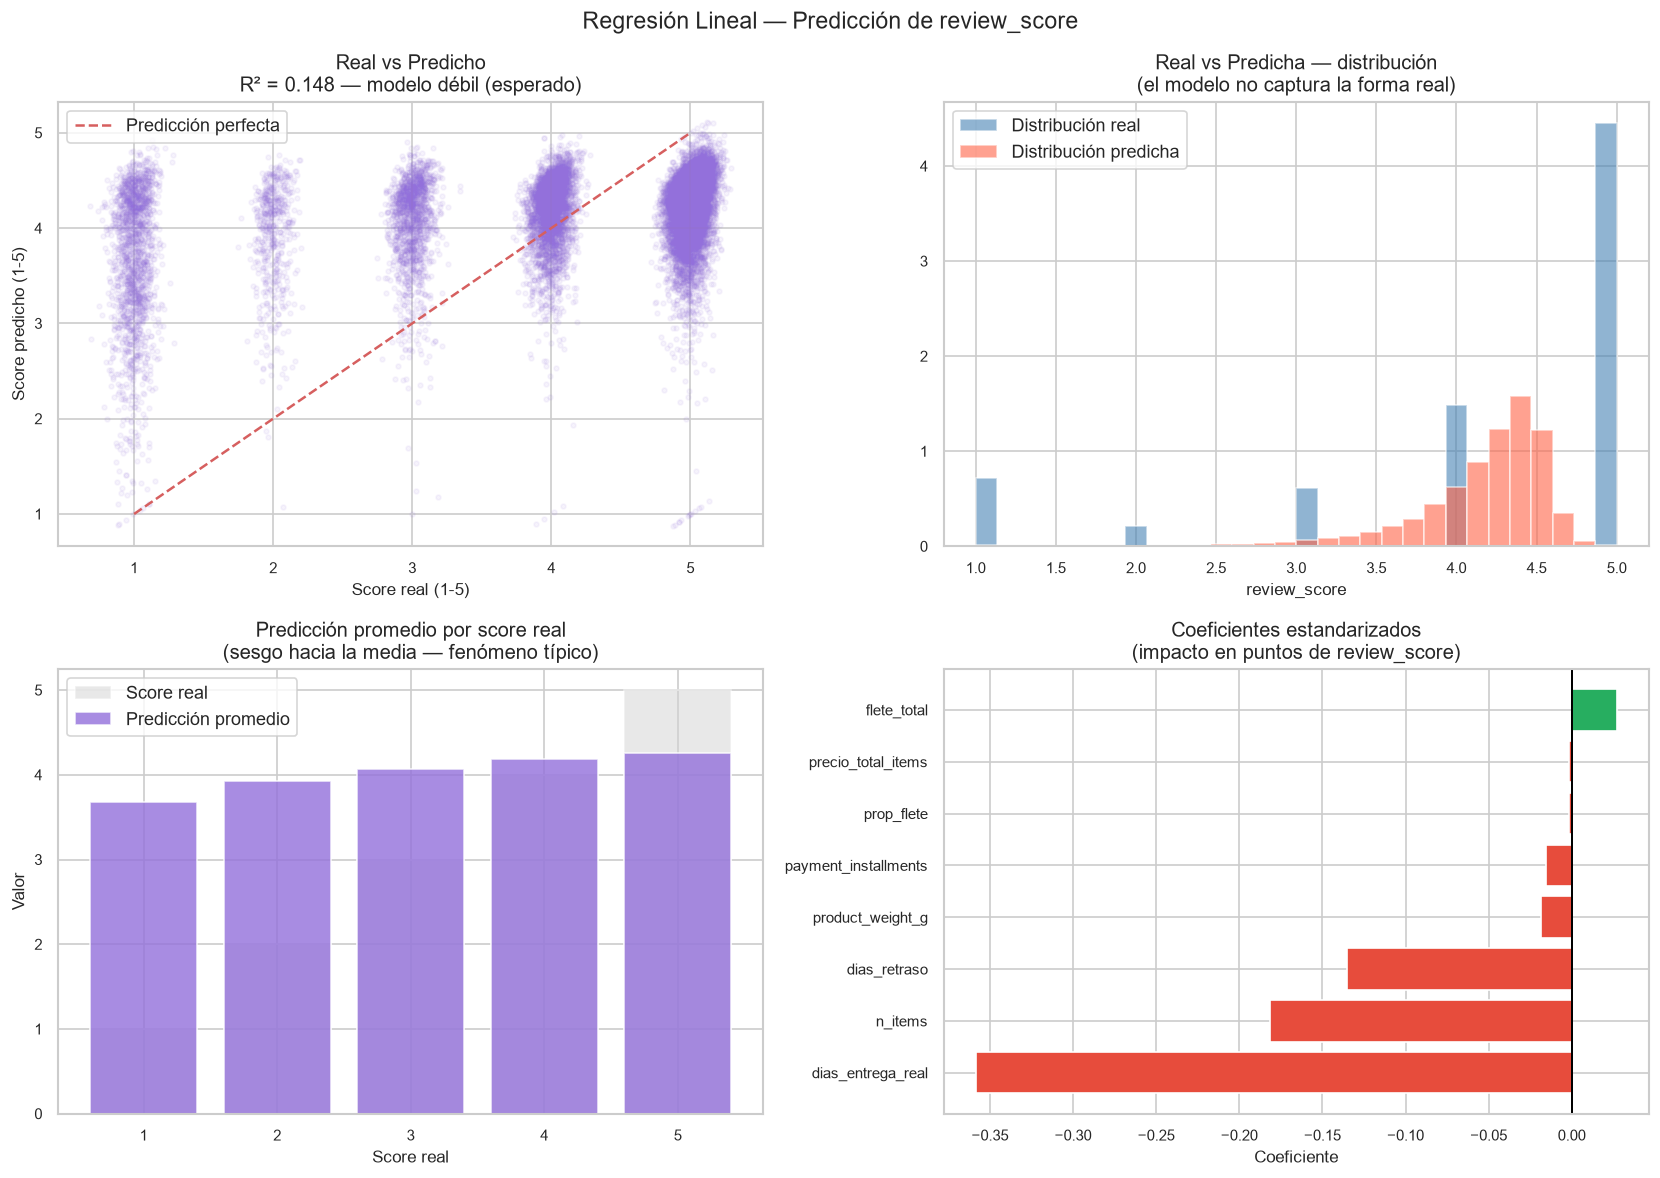

In [30]:
# 7. Visualizaciones Modelo 2
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 7.1 Real vs Predicho (con jitter para ver solapamiento)
jitter = np.random.normal(0, 0.08, size=len(y2_test))
axes[0,0].scatter(y2_test + jitter,
                  y2_pred_clamp + jitter,
                  alpha=0.08, s=8, color='mediumpurple')
axes[0,0].plot([1,5],[1,5],'r--', lw=1.5, label='Predicción perfecta')
axes[0,0].set_xlabel('Score real (1-5)')
axes[0,0].set_ylabel('Score predicho (1-5)')
axes[0,0].set_title(f'Real vs Predicho\nR² = {r2_2:.3f} — modelo débil (esperado)')
axes[0,0].legend()

# 7.2 Distribución real vs predicha
axes[0,1].hist(y2_test, bins=30, alpha=0.6, color='steelblue',
               label='Distribución real', density=True)
axes[0,1].hist(y2_pred_clamp, bins=30, alpha=0.6, color='tomato',
               label='Distribución predicha', density=True)
axes[0,1].set_xlabel('review_score')
axes[0,1].set_title('Real vs Predicha — distribución\n(el modelo no captura la forma real)')
axes[0,1].legend()

# 7.3 Score real promedio vs predicho por valor real
# Agrupa para ver bias del modelo
comparativa = pd.DataFrame({
    'real': y2_test.values,
    'pred': y2_pred_clamp
})
por_score = comparativa.groupby('real')['pred'].mean()
axes[1,0].bar(por_score.index, por_score.index,
              color='lightgray', edgecolor='white',
              label='Score real', alpha=0.5)
axes[1,0].bar(por_score.index, por_score.values,
              color='mediumpurple', edgecolor='white',
              alpha=0.8, label='Predicción promedio')
axes[1,0].set_xlabel('Score real')
axes[1,0].set_ylabel('Valor')
axes[1,0].set_title('Predicción promedio por score real\n(sesgo hacia la media — fenómeno típico)')
axes[1,0].legend()

# 7.4 Coeficientes
coefs2_s = coefs2.sort_values('coeficiente')
colores2 = ['#e74c3c' if v < 0 else '#27ae60' for v in coefs2_s['coeficiente']]
axes[1,1].barh(coefs2_s['feature'], coefs2_s['coeficiente'],
               color=colores2, edgecolor='white')
axes[1,1].axvline(0, color='black', lw=1.2)
axes[1,1].set_title('Coeficientes estandarizados\n(impacto en puntos de review_score)')
axes[1,1].set_xlabel('Coeficiente')

plt.suptitle('Regresión Lineal — Predicción de review_score',
             fontsize=14)
plt.tight_layout()
plt.show()

# CONCLUSIÓN DEL LOS MODELOS DE REGRESIÓN

Modelo 1, alto valor de predicción y puede indicar sobreajuste en el conjunto de entrenamiento, sin embargo se produce por que el pago total tiene un valor lineal con el precio de venta. Es útil de forma operativa, para identificar errores de facturación o ajustes de precios. 

Modelo 2, solo se explica el 14% de la variabilidad de los datos.  R² ≈ bajo → la regresión lineal NO es suficiente. 
¿Por qué? La satisfacción del cliente es:                  
 . No lineal (1 día de retraso ≠ 10x peor que 0.1 días)
 . Discreta (valores 1,2,3,4,5 — no continua)
 . Multifactorial con interacciones complejas

 PRÓXIMO PASO → Random Forest capturará estas relaciones no lineales y debería mejorar el R² del review_score.
 Compararemos ambos modelos con las mismas métricas




## Árboles de decisión y Random Forest

# ¿Qué es un arbol de decisión?
Un árbol de decisión aprende una secuencia de preguntas sobre las features para llegar a una predicción. Cada nodo interno hace una pregunta binaria (xᵢ ≤ umbral), cada rama es la respuesta, y cada hoja contiene el valor predicho.

A diferencia de la regresión lineal, no asume ninguna relación funcional entre X e y — descubre la estructura de los datos por sí mismo particionando el espacio de features de forma recursiva.

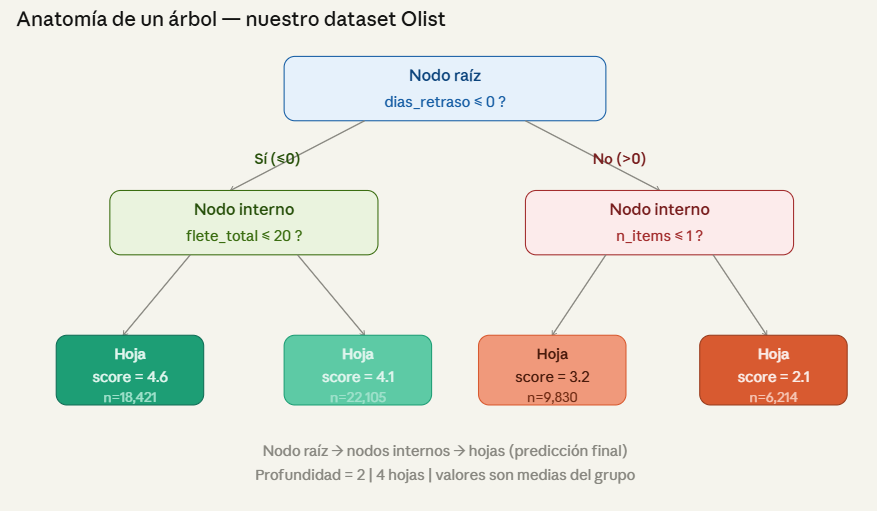

¿Cómo elige el árbol dónde hacer el corte?
En cada nodo evalúa todos los umbrales posibles de todas las features y elige el que minimiza la impureza de los hijos. Para regresión usa la varianza:

Ganancia = Varianza(padre) − [n_izq/n · Varianza(izq) + n_der/n · Varianza(der)]

Para clasificación usa Gini o Entropía:



    Gini = 1 − Σₖ pₖ²
    Entropía = −Σₖ pₖ · log₂(pₖ)

El split con mayor ganancia de información se selecciona. El proceso se repite recursivamente hasta llegar a la profundidad máxima o un nodo puro.

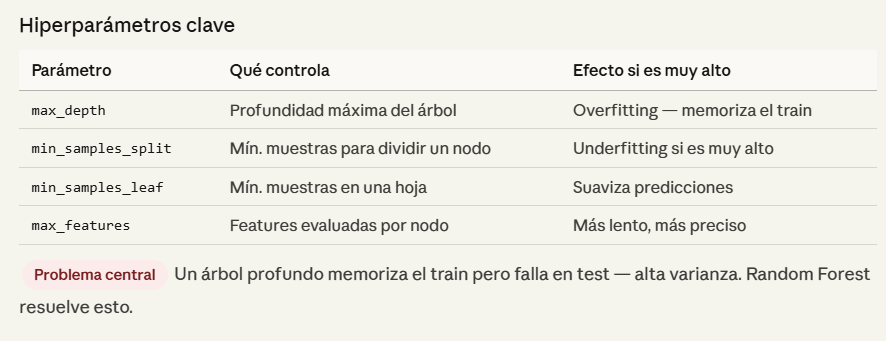

## Random Forest

Para la teoría del Random Forest pasaremos a revisar como se complementan los árboles de decisión y cuál es su idea central. 

De árbol a bosque — la idea central
Un solo árbol tiene alta varianza: cambia mucho si cambian los datos de entrenamiento. Random Forest entrena B árboles independientes sobre muestras bootstrap y promedia sus predicciones. La varianza del promedio cae proporcionalmente a B:

Var(promedio) = ρ·σ² + (1−ρ)/B · σ²

ρ = correlación entre árboles
σ² = varianza de un árbol individual
B = número de árboles

La clave es minimizar ρ — si todos los árboles fueran idénticos, promediarlos no ayudaría. Random Forest reduce ρ con dos mecanismos de aleatoriedad.



### Mecanismo 1

1. Bootstrap sampling
Cada árbol entrena sobre una muestra con reemplazo del dataset original (≈63% de filas únicas). El ~37% restante, llamado Out-of-Bag (OOB), sirve como validación gratuita sin necesitar un set de test separado.

### Mecanismo 2

2. Feature subsampling
En cada nodo, el árbol solo evalúa un subconjunto aleatorio de m features en lugar de todas:
· Regresión: m = p/3
· Clasificación: m = √p
Esto descorelaciona los árboles.

### Hiperparámetros en Random Forest

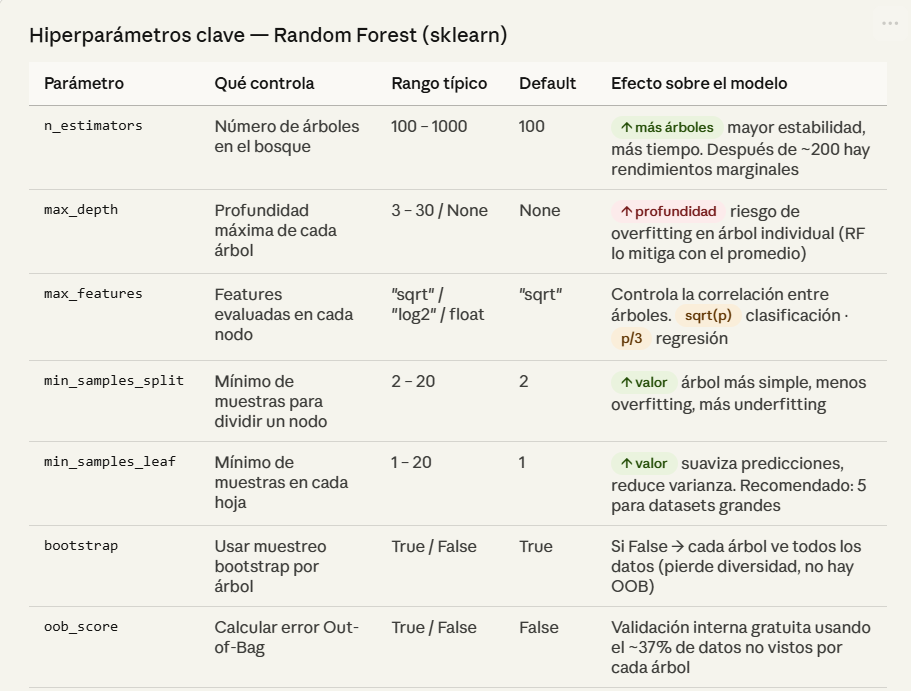

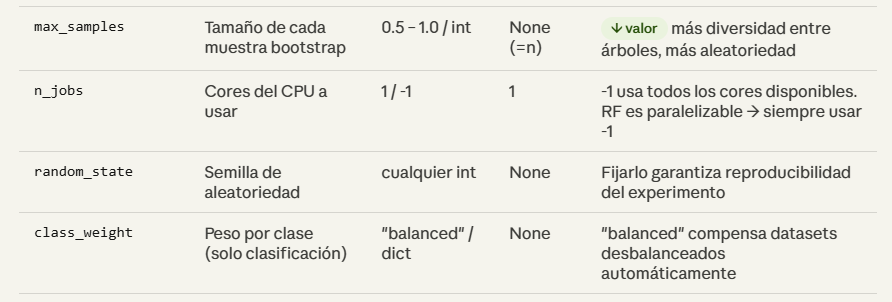

## Fórmulas de max_features según tarea

Clasificación: m = √p (ej: √18 ≈ 4 features por nodo)

Regresión: m = p/3 (ej: 18/3 = 6 features por nodo)

Máximo: m = p (equivale a Bagging puro, árboles más correlados)

p = número total de features del dataset

## Configuración recomendada — punto de partida

Regresión (nuestro caso)

n_estimators = 200

max_features = "sqrt"

max_depth = None

min_samples_leaf = 5

oob_score = True

n_jobs = -1

random_state = 42


Clasificación desbalanceada

n_estimators = 200

max_features = "sqrt"

max_depth = None

min_samples_leaf = 5

class_weight = "balanced"

oob_score = True

n_jobs = -1

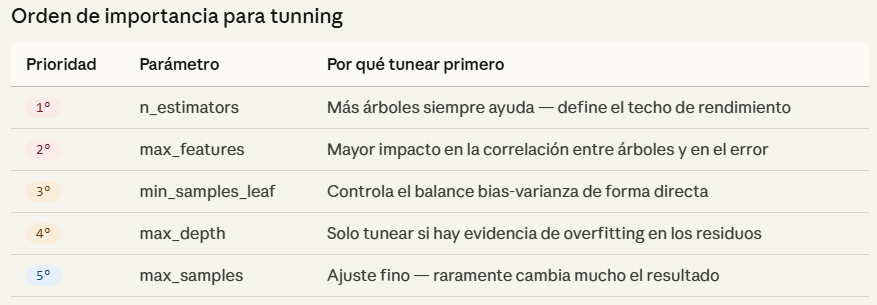

## Uso de predicciones final. 

##### Modelo de regresión. 

Regresión: ŷ_RF = (1/B) · Σᵦ fᵦ(x) ← promedio de B árboles


##### Modelo de clasificación. 

Clasificación: ŷ_RF = argmax_k Σᵦ 1[fᵦ(x)=k] ← voto por mayoría

##### Validación interna

OOB error: ε_OOB = (1/n) Σᵢ L(yᵢ, ŷᵢ_OOB) ← validación interna

## Feature importance — ¿cómo sabe RF qué variables importan?

Para cada árbol, calcula cuánto reduce la impureza (varianza o Gini) cada feature sumado sobre todos los nodos donde se usó. Promedia sobre todos los árboles:

Importance(xⱼ) = (1/B) · Σᵦ Σ_{nodos t donde se usa xⱼ} Δimpureza(t)

Resultado: un ranking de features sin necesidad de p-values ni supuestos de distribución. Captura importancia no lineal e interacciones.

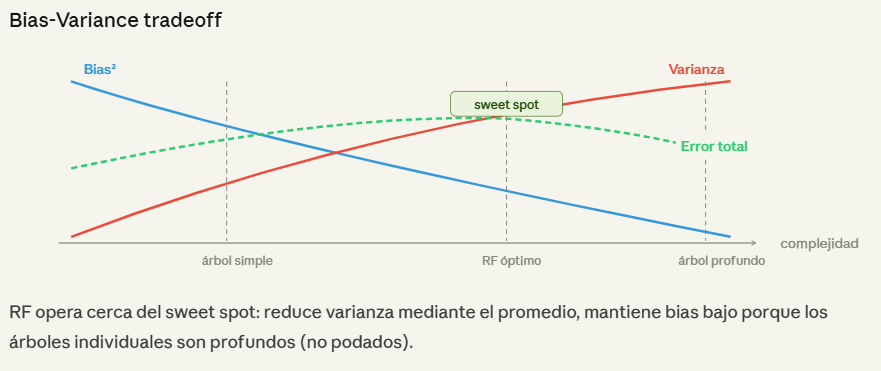

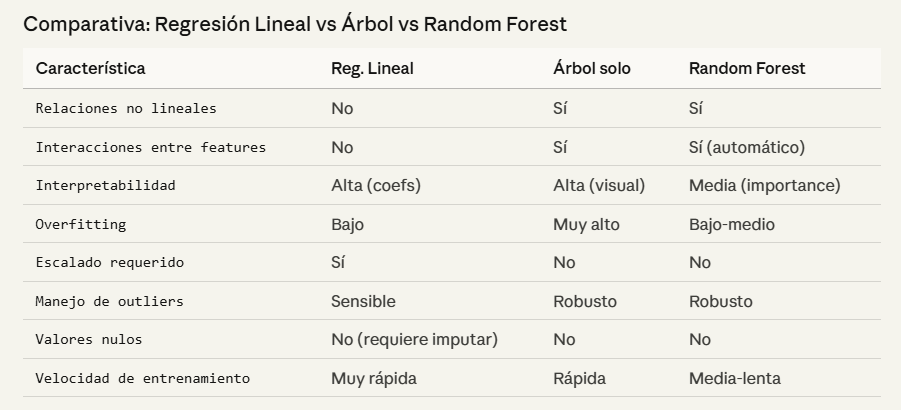


Ahora el código completo, con los mismos dos targets para comparar directamente contra la regresión lineal:

In [31]:
#Traemos las librerías necesarias para construir el modelo
from sklearn.tree import DecisionTreeRegressor, export_text, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [32]:
print("""
╔══════════════════════════════════════════════════════════════╗
║   ÁRBOL DE DECISIÓN Y RANDOM FOREST — OLIST                 ║
║   Mismos targets que regresión lineal → comparación directa ║
╚══════════════════════════════════════════════════════════════╝
""")

# Reutilizamos los mismos features y splits del módulo anterior
features_precio = [
    'precio_total_items', 'n_items', 'flete_total',
    'payment_installments', 'volumen_cm3',
    'product_weight_g', 'mes_compra', 'dia_semana',
]
features_score = [
    'dias_retraso', 'flete_total', 'prop_flete',
    'n_items', 'precio_total_items', 'payment_installments',
    'dias_entrega_real', 'product_weight_g',
]

def preparar_datos(features, target, test_size=0.2):
    df = sabana[features + [target]].dropna()
    X  = df[features]
    y  = df[target]
    return train_test_split(X, y, test_size=test_size, random_state=42)

X1_tr, X1_te, y1_tr, y1_te = preparar_datos(features_precio, 'payment_value_total')
X2_tr, X2_te, y2_tr, y2_te = preparar_datos(features_score,  'review_score')
print(f"payment_value_total — train: {len(X1_tr):,}  test: {len(X1_te):,}")
print(f"review_score        — train: {len(X2_tr):,}  test: {len(X2_te):,}")


╔══════════════════════════════════════════════════════════════╗
║   ÁRBOL DE DECISIÓN Y RANDOM FOREST — OLIST                 ║
║   Mismos targets que regresión lineal → comparación directa ║
╚══════════════════════════════════════════════════════════════╝

payment_value_total — train: 78,919  test: 19,730
review_score        — train: 76,650  test: 19,163


ÁRBOL DE DECISIÓN — payment_value_total
(profundidad=3 para visualización pedagógica)


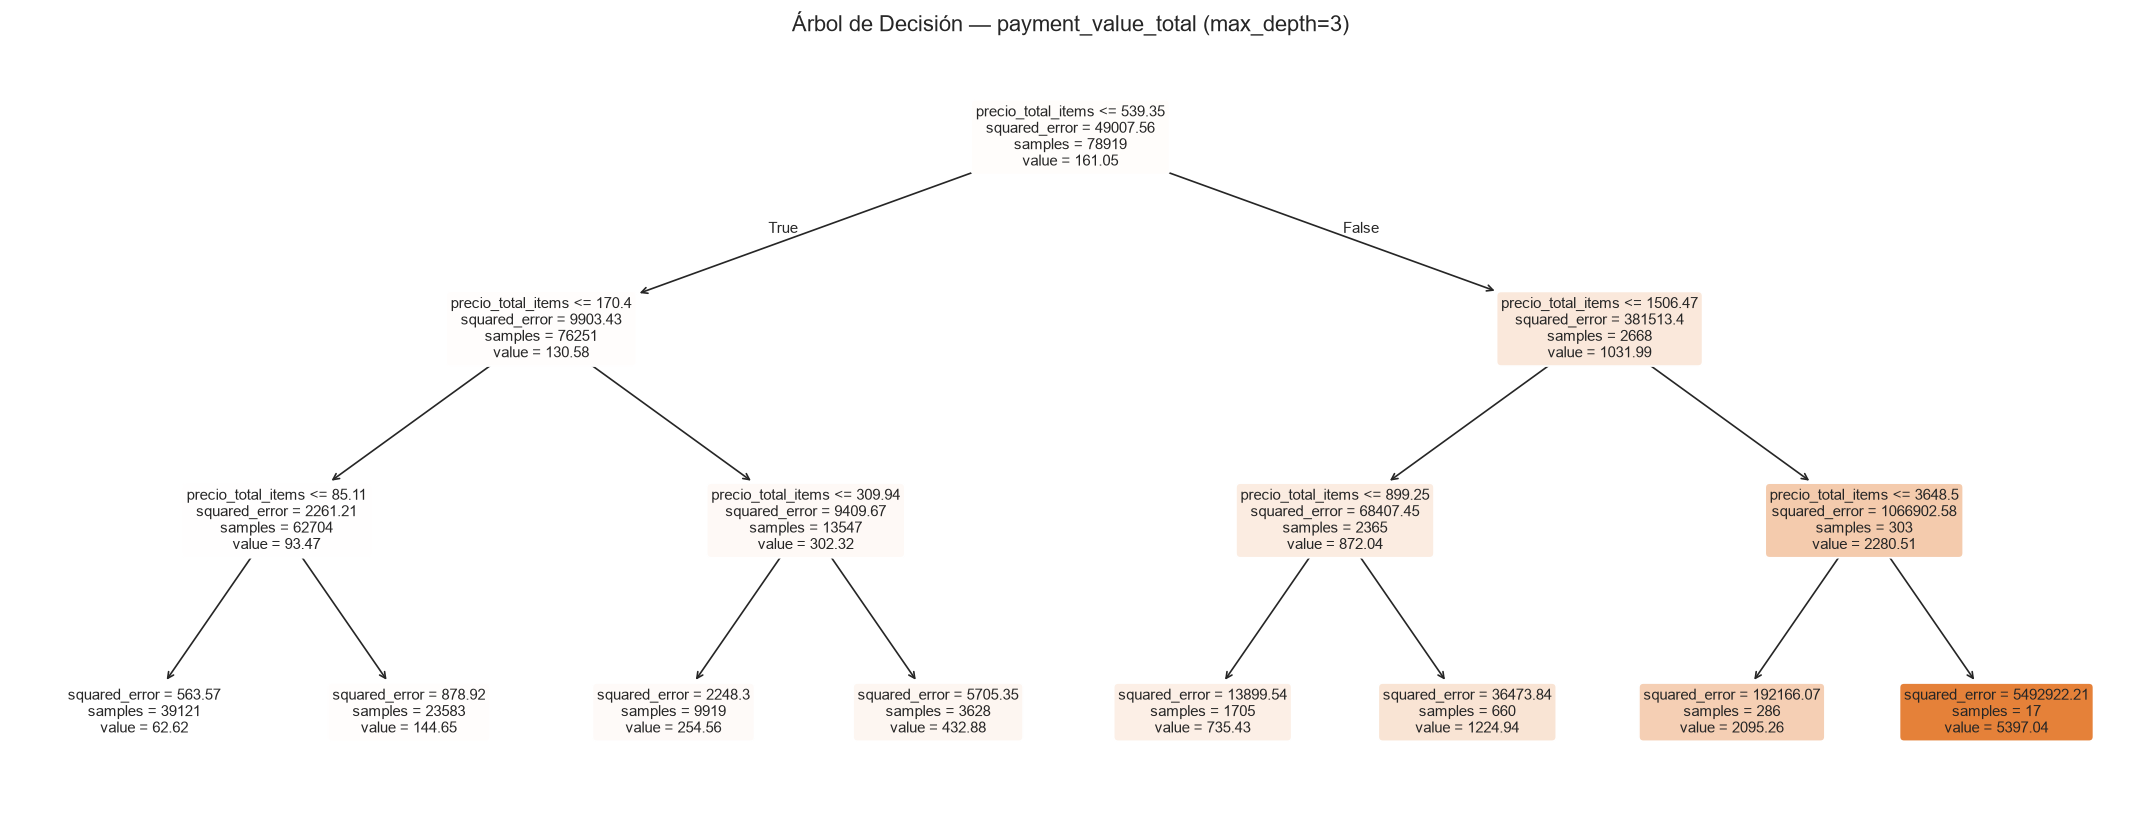


Estructura del árbol en texto:
|--- precio_total_items <= 539.35
|   |--- precio_total_items <= 170.40
|   |   |--- precio_total_items <= 85.11
|   |   |   |--- value: [62.62]
|   |   |--- precio_total_items >  85.11
|   |   |   |--- value: [144.65]
|   |--- precio_total_items >  170.40
|   |   |--- precio_total_items <= 309.94
|   |   |   |--- value: [254.56]
|   |   |--- precio_total_items >  309.94
|   |   |   |--- value: [432.88]
|--- precio_total_items >  539.35
|   |--- precio_total_items <= 1506.47
|   |   |--- precio_total_items <= 899.25
|   |   |   |--- value: [735.43]
|   |   |--- precio_total_items >  899.25
|   |   |   |--- value: [1224.94]
|   |--- precio_total_items >  1506.47
|   |   |--- precio_total_items <= 3648.50
|   |   |   |--- value: [2095.26]
|   |   |--- precio_total_items >  3648.50
|   |   |   |--- value: [5397.04]


Métricas árbol depth=3:
  R²  = 0.9395
  MAE = R$ 29.44


In [33]:
# ──────────────────────────────────────────────────────────────
# PASO 1 — ÁRBOL DE DECISIÓN (versión simple para visualizar)
# Primero con profundidad controlada para entender la lógica
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("ÁRBOL DE DECISIÓN — payment_value_total")
print("(profundidad=3 para visualización pedagógica)")
print("=" * 55)

arbol_viz = DecisionTreeRegressor(max_depth=3, random_state=42)
arbol_viz.fit(X1_tr, y1_tr)

# Visualización del árbol (profundidad 3 es legible)
fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(
    arbol_viz,
    feature_names=features_precio,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
    impurity=True,
    precision=2
)
ax.set_title('Árbol de Decisión — payment_value_total (max_depth=3)',
             fontsize=13)
plt.tight_layout()
plt.show()

# Representación en texto (más legible en notebooks)
print("\nEstructura del árbol en texto:")
print(export_text(arbol_viz, feature_names=features_precio))

y1_pred_arbol3 = arbol_viz.predict(X1_te)
r2_a3  = r2_score(y1_te, y1_pred_arbol3)
mae_a3 = mean_absolute_error(y1_te, y1_pred_arbol3)
print(f"\nMétricas árbol depth=3:")
print(f"  R²  = {r2_a3:.4f}")
print(f"  MAE = R$ {mae_a3:.2f}")

EFECTO DE LA PROFUNDIDAD — Bias-Variance tradeoff


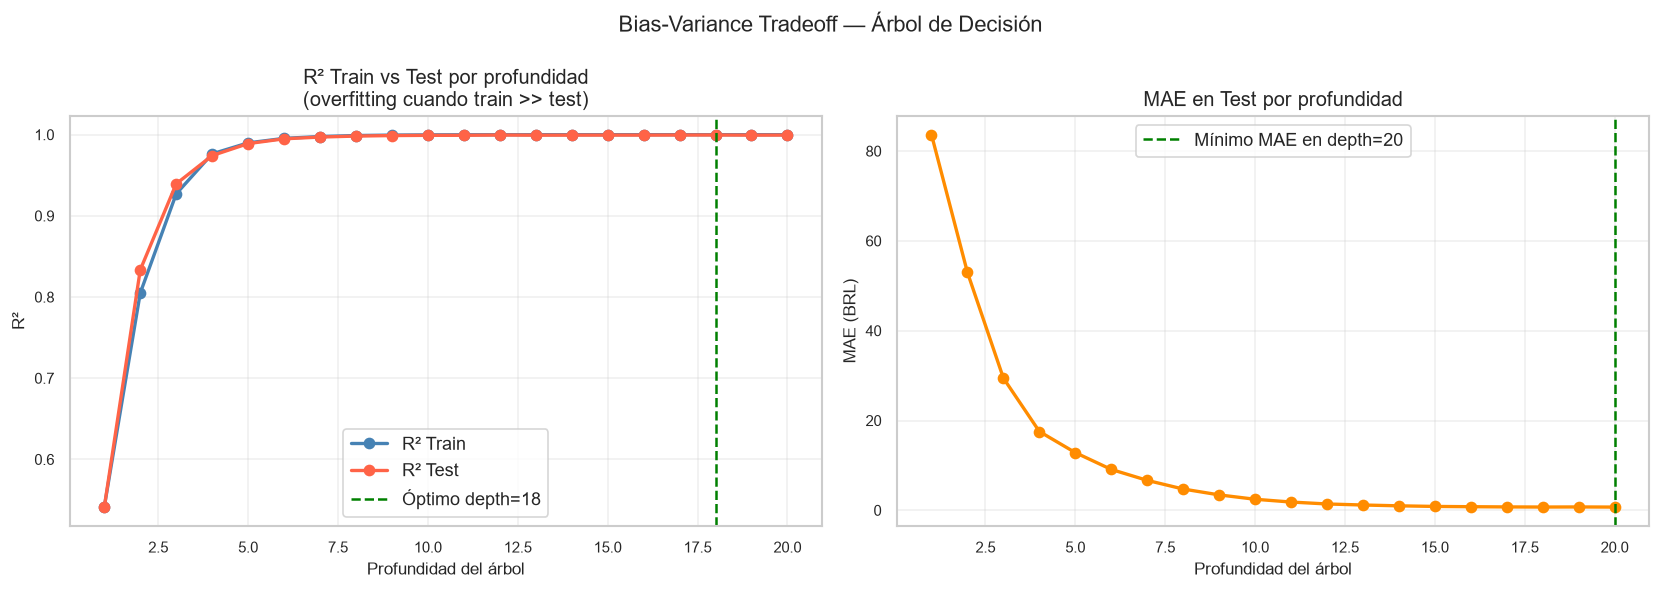


Mejor profundidad para test: 18
R² train en depth=18: 1.0000
R² test  en depth=18: 0.9996
Brecha train-test: 0.0004

OBSERVACIÓN: Con depth alto el árbol MEMORIZA el train (R²≈1)
pero falla en test → overfitting clásico.
Random Forest resuelve esto promediando muchos árboles.



In [34]:
# ──────────────────────────────────────────────────────────────
# PASO 2 — EFECTO DE LA PROFUNDIDAD (overfitting visual)
# Demostración pedagógica del bias-variance tradeoff
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("EFECTO DE LA PROFUNDIDAD — Bias-Variance tradeoff")
print("=" * 55)

profundidades = range(1, 21)
r2_train, r2_test, mae_test = [], [], []

for d in profundidades:
    arbol = DecisionTreeRegressor(max_depth=d, random_state=42)
    arbol.fit(X1_tr, y1_tr)
    r2_train.append(r2_score(y1_tr, arbol.predict(X1_tr)))
    r2_test.append(r2_score(y1_te, arbol.predict(X1_te)))
    mae_test.append(mean_absolute_error(y1_te, arbol.predict(X1_te)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(profundidades, r2_train, 'o-', color='steelblue',
             label='R² Train', lw=2)
axes[0].plot(profundidades, r2_test,  'o-', color='tomato',
             label='R² Test',  lw=2)
axes[0].axvline(np.argmax(r2_test)+1, color='green',
                linestyle='--', lw=1.5,
                label=f'Óptimo depth={np.argmax(r2_test)+1}')
axes[0].set_xlabel('Profundidad del árbol')
axes[0].set_ylabel('R²')
axes[0].set_title('R² Train vs Test por profundidad\n(overfitting cuando train >> test)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(profundidades, mae_test, 'o-', color='darkorange', lw=2)
axes[1].axvline(np.argmin(mae_test)+1, color='green',
                linestyle='--', lw=1.5,
                label=f'Mínimo MAE en depth={np.argmin(mae_test)+1}')
axes[1].set_xlabel('Profundidad del árbol')
axes[1].set_ylabel('MAE (BRL)')
axes[1].set_title('MAE en Test por profundidad')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Bias-Variance Tradeoff — Árbol de Decisión',
             fontsize=13)
plt.tight_layout()
plt.show()

mejor_depth = np.argmax(r2_test) + 1
print(f"\nMejor profundidad para test: {mejor_depth}")
print(f"R² train en depth={mejor_depth}: {r2_train[mejor_depth-1]:.4f}")
print(f"R² test  en depth={mejor_depth}: {r2_test[mejor_depth-1]:.4f}")
print(f"Brecha train-test: {r2_train[mejor_depth-1] - r2_test[mejor_depth-1]:.4f}")
print("""
OBSERVACIÓN: Con depth alto el árbol MEMORIZA el train (R²≈1)
pero falla en test → overfitting clásico.
Random Forest resuelve esto promediando muchos árboles.
""")

In [35]:
# ──────────────────────────────────────────────────────────────
# PASO 3 — RANDOM FOREST: payment_value_total
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("RANDOM FOREST — payment_value_total")
print("=" * 55)

rf1 = RandomForestRegressor(
    n_estimators=200,        # 200 árboles
    max_features='sqrt',     # √p features por nodo (default para regresión: 1/3)
    max_depth=None,          # sin límite — cada árbol crece completo
    min_samples_leaf=5,      # mínimo 5 muestras por hoja
    n_jobs=-1,               # usa todos los cores del CPU
    random_state=42,
    oob_score=True           # calcula OOB error gratis
)

print("Entrenando Random Forest con 200 árboles...")
rf1.fit(X1_tr, y1_tr)
print(f"OOB R² (validación interna sin test set): {rf1.oob_score_:.4f}")

y1_pred_rf = rf1.predict(X1_te)

r2_rf1  = r2_score(y1_te, y1_pred_rf)
mae_rf1 = mean_absolute_error(y1_te, y1_pred_rf)
rmse_rf1= np.sqrt(mean_squared_error(y1_te, y1_pred_rf))

print(f"\nMétricas Random Forest — payment_value_total:")
print(f"  R²   = {r2_rf1:.4f}")
print(f"  MAE  = R$ {mae_rf1:.2f}")
print(f"  RMSE = R$ {rmse_rf1:.2f}")

RANDOM FOREST — payment_value_total
Entrenando Random Forest con 200 árboles...
OOB R² (validación interna sin test set): 0.9300

Métricas Random Forest — payment_value_total:
  R²   = 0.9564
  MAE  = R$ 6.61
  RMSE = R$ 45.22


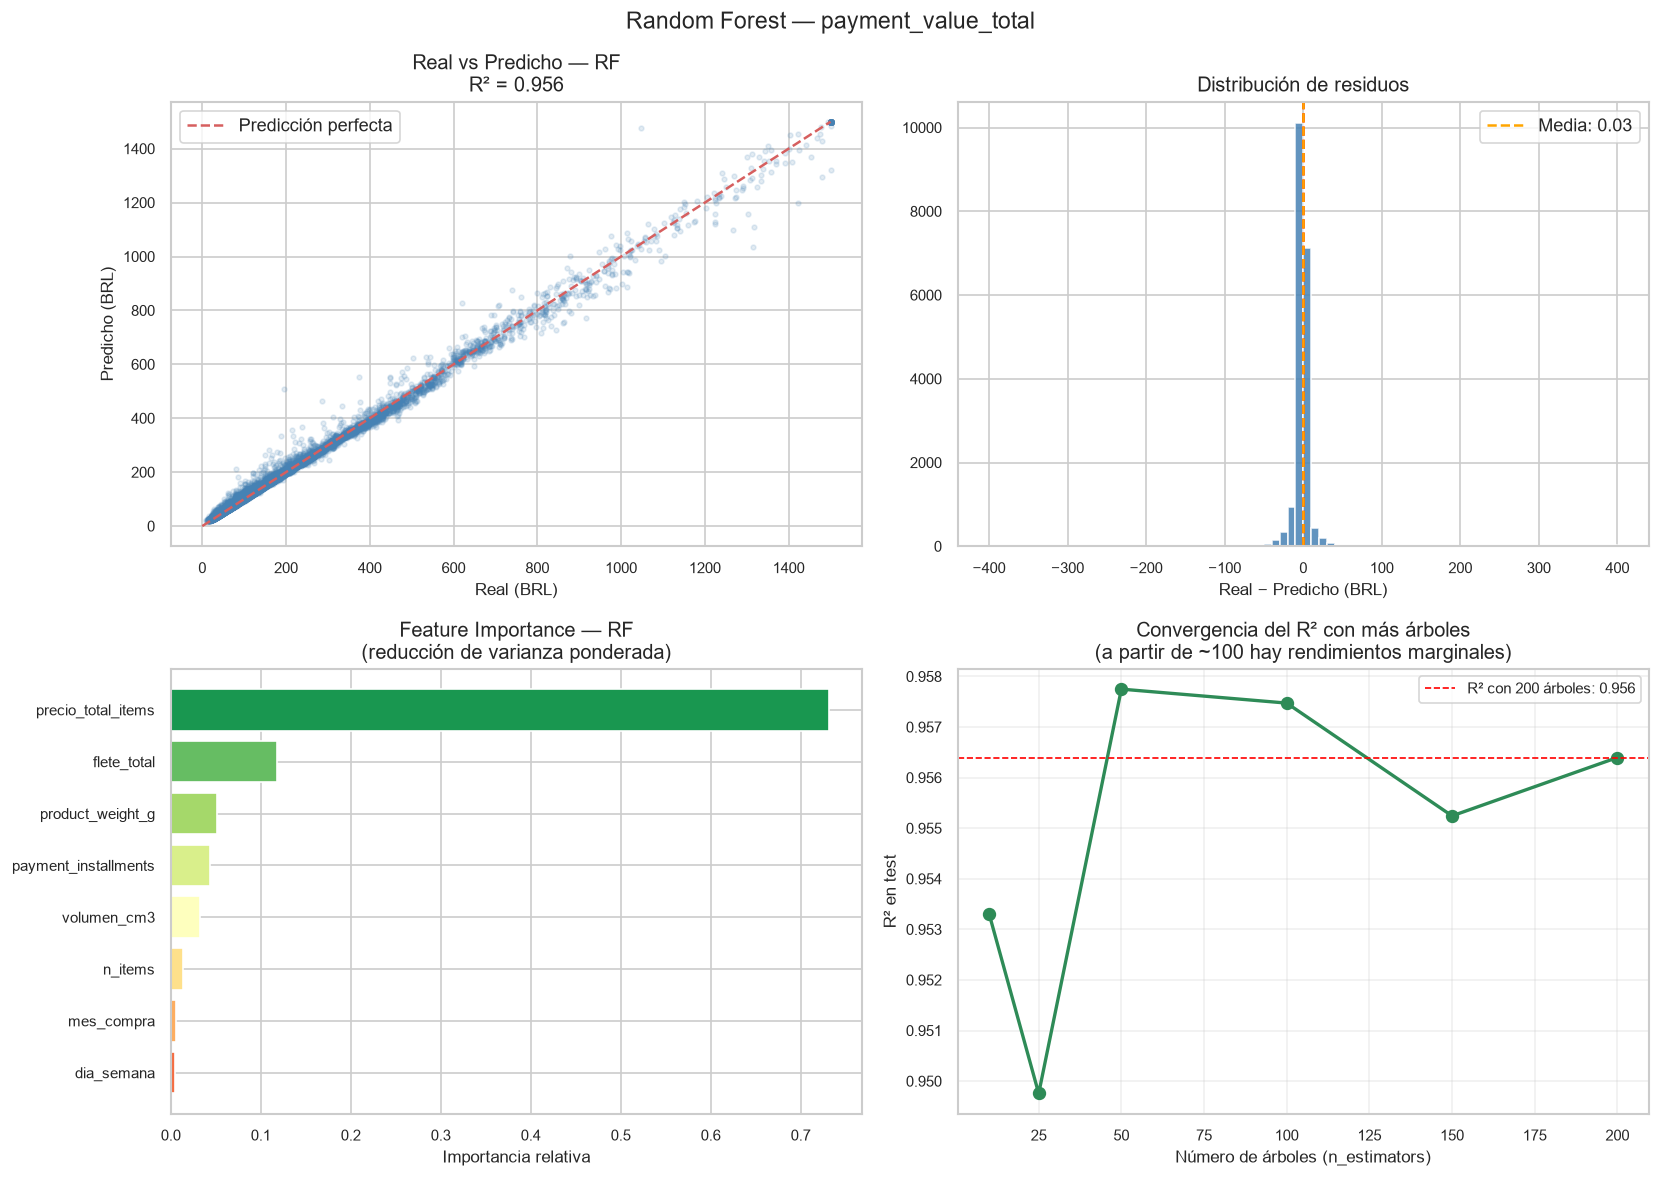

In [36]:
# Visualizaciones RF — payment_value_total
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Real vs predicho
lim = 1500
axes[0,0].scatter(y1_te.clip(upper=lim),
                  np.clip(y1_pred_rf, 0, lim),
                  alpha=0.15, s=8, color='steelblue')
axes[0,0].plot([0,lim],[0,lim],'r--', lw=1.5, label='Predicción perfecta')
axes[0,0].set_xlabel('Real (BRL)')
axes[0,0].set_ylabel('Predicho (BRL)')
axes[0,0].set_title(f'Real vs Predicho — RF\nR² = {r2_rf1:.3f}')
axes[0,0].legend()

# 2. Residuos
residuos_rf1 = y1_te - y1_pred_rf
axes[0,1].hist(residuos_rf1.clip(-400, 400), bins=80,
               color='steelblue', edgecolor='white', alpha=0.85)
axes[0,1].axvline(0, color='red', linestyle='--', lw=1.5)
axes[0,1].axvline(residuos_rf1.mean(), color='orange', linestyle='--',
                  label=f'Media: {residuos_rf1.mean():.2f}')
axes[0,1].set_title('Distribución de residuos')
axes[0,1].set_xlabel('Real − Predicho (BRL)')
axes[0,1].legend()

# 3. Feature importance
importancias1 = pd.Series(rf1.feature_importances_,
                           index=features_precio).sort_values()
colores_imp = plt.cm.RdYlGn(
    np.linspace(0.2, 0.9, len(importancias1)))
axes[1,0].barh(importancias1.index, importancias1.values,
               color=colores_imp, edgecolor='white')
axes[1,0].set_title('Feature Importance — RF\n(reducción de varianza ponderada)')
axes[1,0].set_xlabel('Importancia relativa')

# 4. Convergencia por número de árboles
n_arboles_range = [10, 25, 50, 100, 150, 200]
r2_por_n = []
for n in n_arboles_range:
    rf_temp = RandomForestRegressor(n_estimators=n, max_features='sqrt',
                                    min_samples_leaf=5, n_jobs=-1,
                                    random_state=42)
    rf_temp.fit(X1_tr, y1_tr)
    r2_por_n.append(r2_score(y1_te, rf_temp.predict(X1_te)))

axes[1,1].plot(n_arboles_range, r2_por_n, 'o-',
               color='seagreen', lw=2, markersize=7)
axes[1,1].axhline(r2_rf1, color='red', linestyle='--', lw=1,
                  label=f'R² con 200 árboles: {r2_rf1:.3f}')
axes[1,1].set_xlabel('Número de árboles (n_estimators)')
axes[1,1].set_ylabel('R² en test')
axes[1,1].set_title('Convergencia del R² con más árboles\n(a partir de ~100 hay rendimientos marginales)')
axes[1,1].legend(fontsize=9)
axes[1,1].grid(True, alpha=0.3)

plt.suptitle('Random Forest — payment_value_total', fontsize=14)
plt.tight_layout()
plt.show()

RANDOM FOREST — review_score
OOB R²: 0.2001

Métricas Random Forest — review_score:
  R²   = 0.2071
  MAE  = 0.8725 puntos
  RMSE = 1.1371 puntos


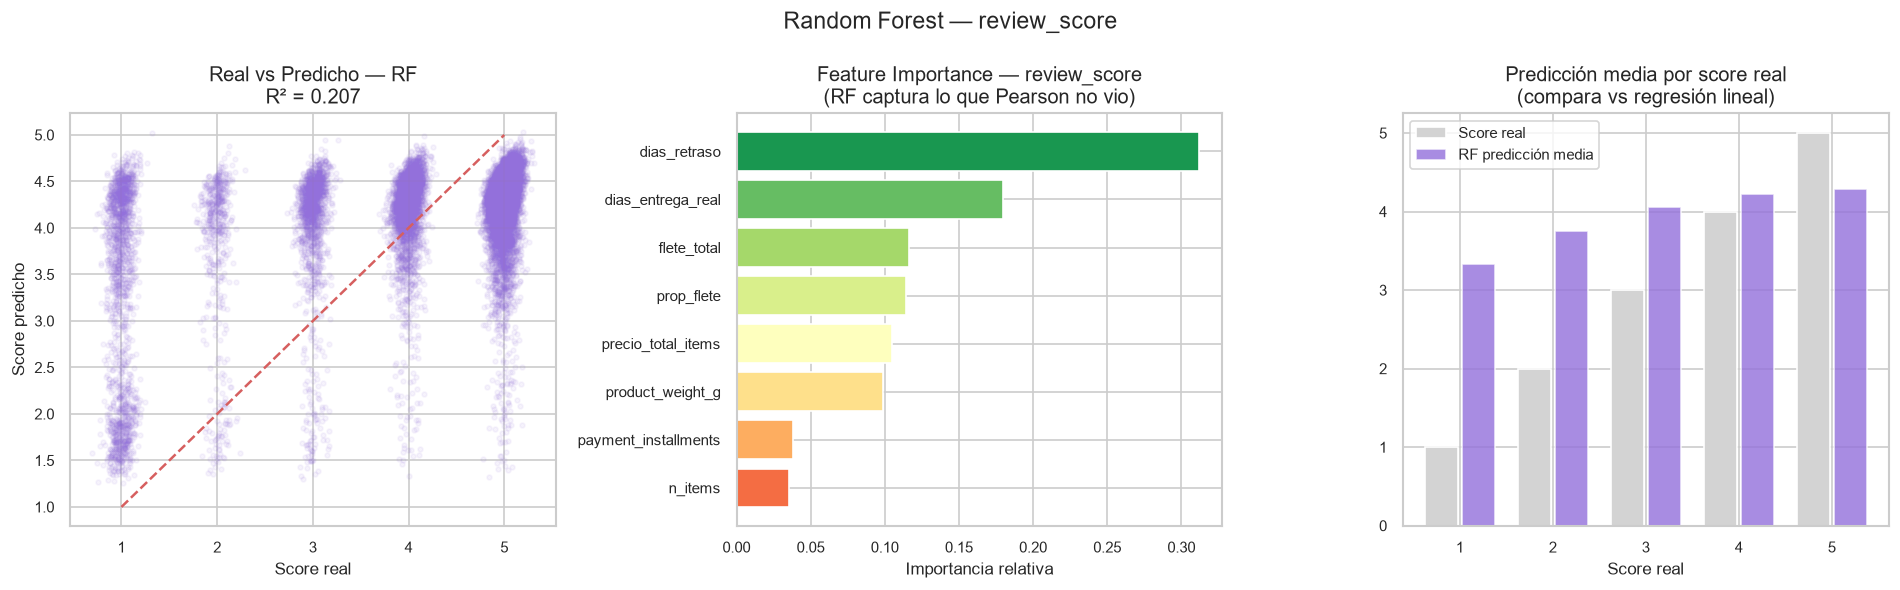

In [37]:
# ──────────────────────────────────────────────────────────────
# PASO 4 — RANDOM FOREST: review_score
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("RANDOM FOREST — review_score")
print("=" * 55)

rf2 = RandomForestRegressor(
    n_estimators=200,
    max_features='sqrt',
    max_depth=None,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
    oob_score=True
)

rf2.fit(X2_tr, y2_tr)
print(f"OOB R²: {rf2.oob_score_:.4f}")

y2_pred_rf = np.clip(rf2.predict(X2_te), 1, 5)

r2_rf2  = r2_score(y2_te, y2_pred_rf)
mae_rf2 = mean_absolute_error(y2_te, y2_pred_rf)
rmse_rf2= np.sqrt(mean_squared_error(y2_te, y2_pred_rf))

print(f"\nMétricas Random Forest — review_score:")
print(f"  R²   = {r2_rf2:.4f}")
print(f"  MAE  = {mae_rf2:.4f} puntos")
print(f"  RMSE = {rmse_rf2:.4f} puntos")

# Visualizaciones RF — review_score
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Real vs predicho con jitter
jitter = np.random.normal(0, 0.08, len(y2_te))
axes[0].scatter(y2_te + jitter, y2_pred_rf + jitter,
                alpha=0.08, s=8, color='mediumpurple')
axes[0].plot([1,5],[1,5],'r--', lw=1.5)
axes[0].set_xlabel('Score real')
axes[0].set_ylabel('Score predicho')
axes[0].set_title(f'Real vs Predicho — RF\nR² = {r2_rf2:.3f}')

# Feature importance
importancias2 = pd.Series(rf2.feature_importances_,
                           index=features_score).sort_values()
colores_imp2 = plt.cm.RdYlGn(np.linspace(0.2, 0.9, len(importancias2)))
axes[1].barh(importancias2.index, importancias2.values,
             color=colores_imp2, edgecolor='white')
axes[1].set_title('Feature Importance — review_score\n(RF captura lo que Pearson no vio)')
axes[1].set_xlabel('Importancia relativa')

# Predicción promedio por score real
comp2 = pd.DataFrame({'real': y2_te.values, 'pred': y2_pred_rf})
por_score2 = comp2.groupby('real')['pred'].mean()
x_pos = np.arange(len(por_score2))
axes[2].bar(x_pos - 0.2, por_score2.index, 0.35,
            color='lightgray', edgecolor='white', label='Score real')
axes[2].bar(x_pos + 0.2, por_score2.values, 0.35,
            color='mediumpurple', edgecolor='white', alpha=0.8,
            label='RF predicción media')
axes[2].set_xticks(x_pos)
axes[2].set_xticklabels(por_score2.index.astype(int))
axes[2].set_xlabel('Score real')
axes[2].set_title('Predicción media por score real\n(compara vs regresión lineal)')
axes[2].legend(fontsize=9)

plt.suptitle('Random Forest — review_score', fontsize=14)
plt.tight_layout()
plt.show()


╔══════════════════════════════════════════════════════════════╗
║         TABLA COMPARATIVA — TODOS LOS MODELOS               ║
╚══════════════════════════════════════════════════════════════╝

             Modelo              Target      R²    MAE    RMSE
        Reg. Lineal payment_value_total  1.0000 0.0835  0.8565
   Árbol (depth=18) payment_value_total  0.9996 0.7335  4.2590
Random Forest (200) payment_value_total  0.9564 6.6114 45.2193
        Reg. Lineal        review_score  0.1480 0.9091  1.1787
   Árbol (depth=18)        review_score -0.0673 0.9311  1.3193
Random Forest (200)        review_score  0.2071 0.8725  1.1371


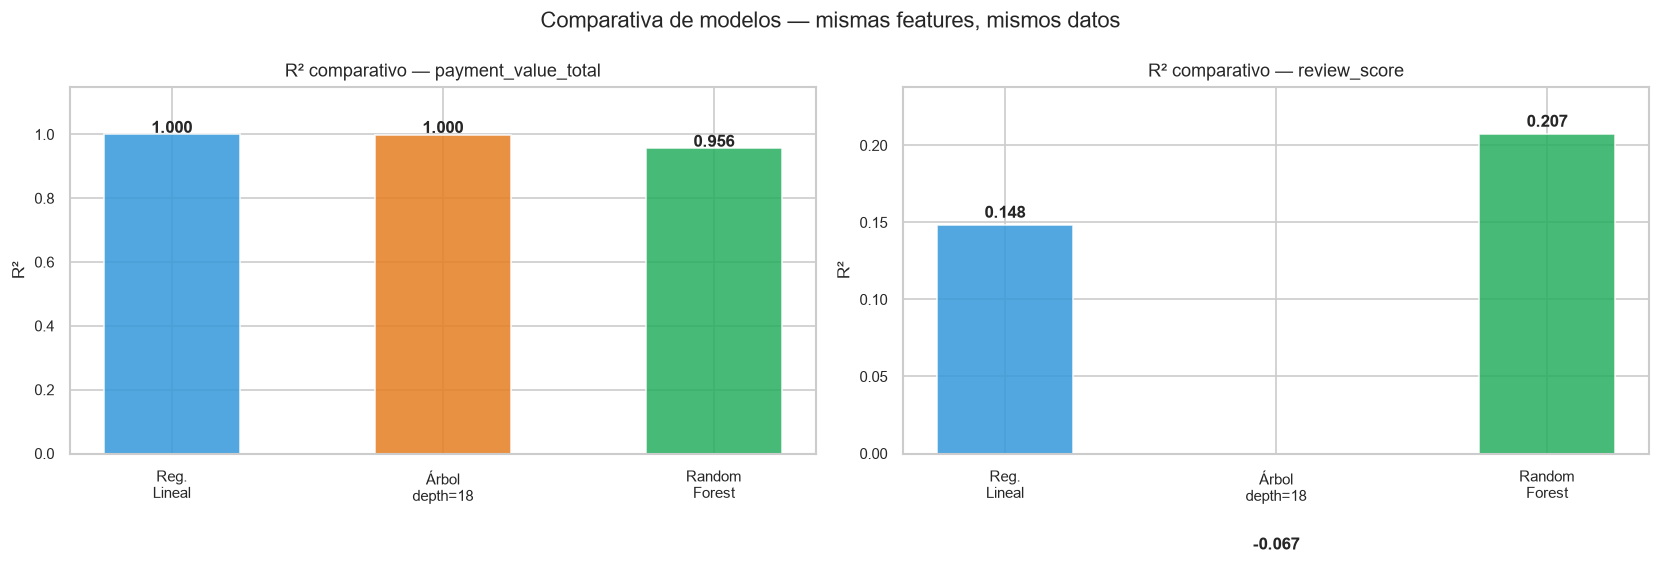


CONCLUSIONES FINALES:
─────────────────────────────────────────────────────────────
payment_value_total:
  · Los 3 modelos funcionan bien (relación casi lineal)
  · RF mejora levemente al árbol individual
  · La feature más importante: precio_total_items

review_score:
  · Regresión Lineal: R² bajo → relación NO es lineal
  · Árbol individual: mejora pero tiene alta varianza
  · Random Forest: mejor R² — captura patrones no lineales
  · Feature importance: dias_retraso domina ampliamente
  · Aún así el R² es bajo → la satisfacción es compleja
    → Esto motiva clasificación (review ≥ 4 vs < 4)
    y modelos más potentes (XGBoost, redes neuronales)
─────────────────────────────────────────────────────────────



In [38]:
# ──────────────────────────────────────────────────────────────
# PASO 5 — TABLA COMPARATIVA FINAL
# Regresión Lineal vs Árbol vs Random Forest
# ──────────────────────────────────────────────────────────────
print("""
╔══════════════════════════════════════════════════════════════╗
║         TABLA COMPARATIVA — TODOS LOS MODELOS               ║
╚══════════════════════════════════════════════════════════════╝
""")

# Árbol con profundidad óptima
arbol_opt1 = DecisionTreeRegressor(
    max_depth=mejor_depth, random_state=42)
arbol_opt1.fit(X1_tr, y1_tr)
y1_pred_arbol_opt = arbol_opt1.predict(X1_te)

arbol_opt2 = DecisionTreeRegressor(max_depth=mejor_depth, random_state=42)
arbol_opt2.fit(X2_tr, y2_tr)
y2_pred_arbol_opt = np.clip(arbol_opt2.predict(X2_te), 1, 5)

# Los valores de regresión lineal vienen del módulo anterior
# Si no están en memoria, recalcular aquí:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

def eval_pipe(feats, X_tr, X_te, y_tr, y_te, clip=None):
    pipe = Pipeline([('sc', StandardScaler()), ('m', LinearRegression())])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    if clip: pred = np.clip(pred, *clip)
    return (r2_score(y_te, pred),
            mean_absolute_error(y_te, pred),
            np.sqrt(mean_squared_error(y_te, pred)))

r2_lr1, mae_lr1, rmse_lr1 = eval_pipe(
    features_precio, X1_tr, X1_te, y1_tr, y1_te)
r2_lr2, mae_lr2, rmse_lr2 = eval_pipe(
    features_score, X2_tr, X2_te, y2_tr, y2_te, clip=(1,5))

resultados = pd.DataFrame({
    'Modelo': [
        'Reg. Lineal', f'Árbol (depth={mejor_depth})', 'Random Forest (200)',
        'Reg. Lineal', f'Árbol (depth={mejor_depth})', 'Random Forest (200)'
    ],
    'Target': [
        'payment_value_total','payment_value_total','payment_value_total',
        'review_score','review_score','review_score'
    ],
    'R²' : [r2_lr1,
             r2_score(y1_te, y1_pred_arbol_opt),
             r2_rf1,
             r2_lr2,
             r2_score(y2_te, y2_pred_arbol_opt),
             r2_rf2],
    'MAE': [mae_lr1,
             mean_absolute_error(y1_te, y1_pred_arbol_opt),
             mae_rf1,
             mae_lr2,
             mean_absolute_error(y2_te, y2_pred_arbol_opt),
             mae_rf2],
    'RMSE':[rmse_lr1,
             np.sqrt(mean_squared_error(y1_te, y1_pred_arbol_opt)),
             rmse_rf1,
             rmse_lr2,
             np.sqrt(mean_squared_error(y2_te, y2_pred_arbol_opt)),
             rmse_rf2],
})
resultados[['R²','MAE','RMSE']] = resultados[['R²','MAE','RMSE']].round(4)
print(resultados.to_string(index=False))

# Gráfico comparativo
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
modelos = ['Reg.\nLineal', f'Árbol\ndepth={mejor_depth}', 'Random\nForest']
colores_m = ['#3498db', '#e67e22', '#27ae60']

for ax, target, r2s, maes in zip(
    axes,
    ['payment_value_total', 'review_score'],
    [[r2_lr1, r2_score(y1_te, y1_pred_arbol_opt), r2_rf1],
     [r2_lr2, r2_score(y2_te, y2_pred_arbol_opt), r2_rf2]],
    [[mae_lr1, mean_absolute_error(y1_te, y1_pred_arbol_opt), mae_rf1],
     [mae_lr2, mean_absolute_error(y2_te, y2_pred_arbol_opt), mae_rf2]]
):
    x = np.arange(len(modelos))
    bars = ax.bar(x, r2s, color=colores_m, edgecolor='white',
                  width=0.5, alpha=0.85)
    ax.set_xticks(x)
    ax.set_xticklabels(modelos)
    ax.set_ylabel('R²')
    ax.set_title(f'R² comparativo — {target}', fontsize=11)
    ax.set_ylim(0, max(r2s) * 1.15)
    for bar, v in zip(bars, r2s):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.005,
                f'{v:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.suptitle('Comparativa de modelos — mismas features, mismos datos',
             fontsize=13)
plt.tight_layout()
plt.show()

print("""
CONCLUSIONES FINALES:
─────────────────────────────────────────────────────────────
payment_value_total:
  · Los 3 modelos funcionan bien (relación casi lineal)
  · RF mejora levemente al árbol individual
  · La feature más importante: precio_total_items

review_score:
  · Regresión Lineal: R² bajo → relación NO es lineal
  · Árbol individual: mejora pero tiene alta varianza
  · Random Forest: mejor R² — captura patrones no lineales
  · Feature importance: dias_retraso domina ampliamente
  · Aún así el R² es bajo → la satisfacción es compleja
    → Esto motiva clasificación (review ≥ 4 vs < 4)
    y modelos más potentes (XGBoost, redes neuronales)
─────────────────────────────────────────────────────────────
""")

# Modelo ensembled: XGBoost

## ¿Qué es XGBoost y en qué difiere de Random Forest?
XGBoost (eXtreme Gradient Boosting) es un algoritmo de boosting — construye árboles de forma secuencial, donde cada árbol nuevo corrige los errores del anterior. Random Forest construye árboles en paralelo e independientes.

#### Random Forest — Bagging
Árboles independientes en paralelo. Cada uno ve una muestra diferente. El resultado es el promedio. Reduce varianza. Robusto al overfitting.

#### XGBoost — Boosting
Árboles secuenciales. Cada árbol aprende de los residuos del anterior. Reduce tanto bias como varianza. Más potente pero requiere tunning.

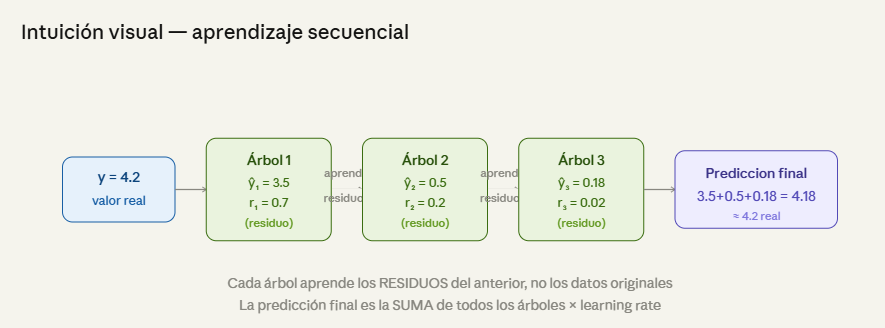

## Matemática del Gradient Boosting
XGBoost minimiza una función de pérdida usando descenso de gradiente en el espacio funcional. En cada iteración t añade un árbol fₜ que reduce el error:

Objetivo(t) = Σᵢ L(yᵢ, ŷᵢ⁽ᵗ⁾) + Σₖ Ω(fₖ)

donde:

L = función de pérdida (MSE para regresión, log-loss para clasificación)


Ω(f) = γT + ½λ‖w‖² ← regularización del árbol


T = número de hojas w = pesos de las hojas

Aproximación de Taylor de segundo orden (la innovación clave de XGBoost):

Obj(t) ≈ Σᵢ [gᵢfₜ(xᵢ) + ½hᵢfₜ(xᵢ)²] + Ω(fₜ)

gᵢ = ∂L(yᵢ, ŷ⁽ᵗ⁻¹⁾)/∂ŷ ← gradiente (1ª derivada)

hᵢ = ∂²L(yᵢ, ŷ⁽ᵗ⁻¹⁾)/∂ŷ² ← hessiano (2ª derivada)

Predicción final tras T iteraciones:

ŷᵢ = Σₜ₌₁ᵀ η · fₜ(xᵢ) donde η = learning_rate

## Los tres mecanismos de regularización de XGBoost

#### Learning rate (η)

Escala la contribución de cada árbol. Valor bajo → más árboles necesarios pero generaliza mejor. Típico: 0.01–0.3


#### Regularización L1/L2

α (L1) y λ (L2) penalizan los pesos de las hojas. Evitan que el modelo se ajuste a ruido. L2 es el default.

#### Subsampling

subsample: fracción de filas por árbol. colsample_bytree: fracción de features. Añade aleatoriedad como RF.

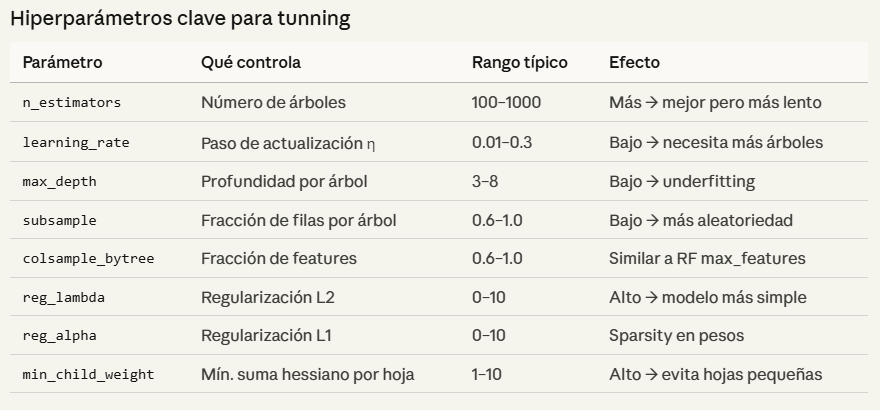

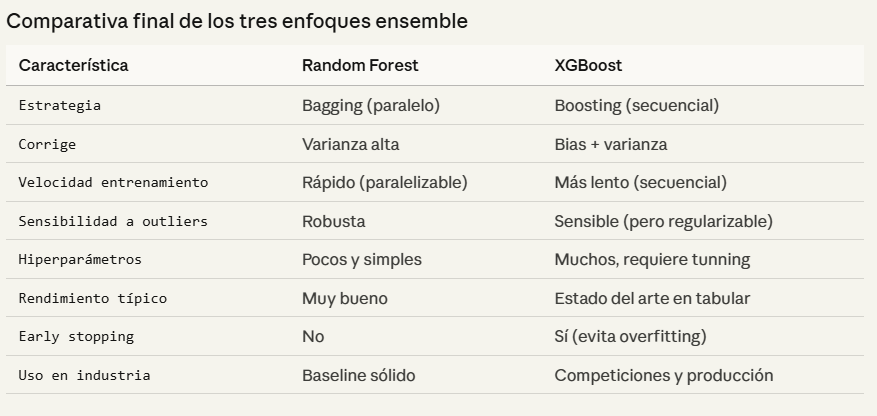

In [39]:
pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------- ----------------------------- 12.8/48.9 MB 80.8 MB/s eta 0:00:01
   -------------------- ------------------- 25.4/48.9 MB 68.1 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 88.0 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 88.0 MB/s eta 0:00:01
   ---------------------------------------  48.8/48.9 MB 88.0 MB/s eta 0:00:01
   ---------------------------------------- 48.9/48.9 MB 44.1 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
# Ahora si, nos vamos al código. 


#Importamos librerías. 

# ═══════════════════════════════════════════════════════════════
# MÓDULO 3 — ENSEMBLE: XGBOOST
# Targets: payment_value_total y review_score
# Comparativa: Reg. Lineal vs Árbol vs RF vs XGBoost
# ═══════════════════════════════════════════════════════════════
# Instalación si no está disponible:
# pip install xgboost

import xgboost as xgb
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [41]:
# ──────────────────────────────────────────────────────────────
# MODELO XGB 1 — payment_value_total
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("XGBOOST — payment_value_total")
print("=" * 55)

# XGBoost NO requiere escalado — trabaja con valores originales
xgb1 = XGBRegressor(
    n_estimators      = 500,    # árboles — usaremos early stopping
    learning_rate     = 0.05,   # η bajo → más árboles, mejor generalización
    max_depth         = 5,      # profundidad moderada
    subsample         = 0.8,    # 80% de filas por árbol
    colsample_bytree  = 0.8,    # 80% de features por árbol
    reg_lambda        = 1.0,    # regularización L2
    reg_alpha         = 0.1,    # regularización L1 (sparsity)
    min_child_weight  = 5,      # mínimo peso por hoja
    random_state      = 42,
    n_jobs            = -1,
    verbosity         = 0
)

# Early stopping — detiene cuando el error en validación no mejora
# Separamos un set de validación adicional para este fin
X1_tr2, X1_val, y1_tr2, y1_val = train_test_split(
    X1_tr, y1_tr, test_size=0.15, random_state=42
)

xgb1.set_params(early_stopping_rounds=30)

xgb1.fit(
    X1_tr2, y1_tr2,
    eval_set=[(X1_val, y1_val)],
    verbose=False
)

print(f"Árboles usados (early stopping): {xgb1.best_iteration + 1} de 500")

y1_pred_xgb = xgb1.predict(X1_te)

r2_xgb1   = r2_score(y1_te, y1_pred_xgb)
mae_xgb1  = mean_absolute_error(y1_te, y1_pred_xgb)
rmse_xgb1 = np.sqrt(mean_squared_error(y1_te, y1_pred_xgb))

print(f"\nMétricas XGBoost — payment_value_total:")
print(f"  R²   = {r2_xgb1:.4f}")
print(f"  MAE  = R$ {mae_xgb1:.2f}")
print(f"  RMSE = R$ {rmse_xgb1:.2f}")

XGBOOST — payment_value_total
Árboles usados (early stopping): 118 de 500

Métricas XGBoost — payment_value_total:
  R²   = 0.9327
  MAE  = R$ 6.43
  RMSE = R$ 56.19


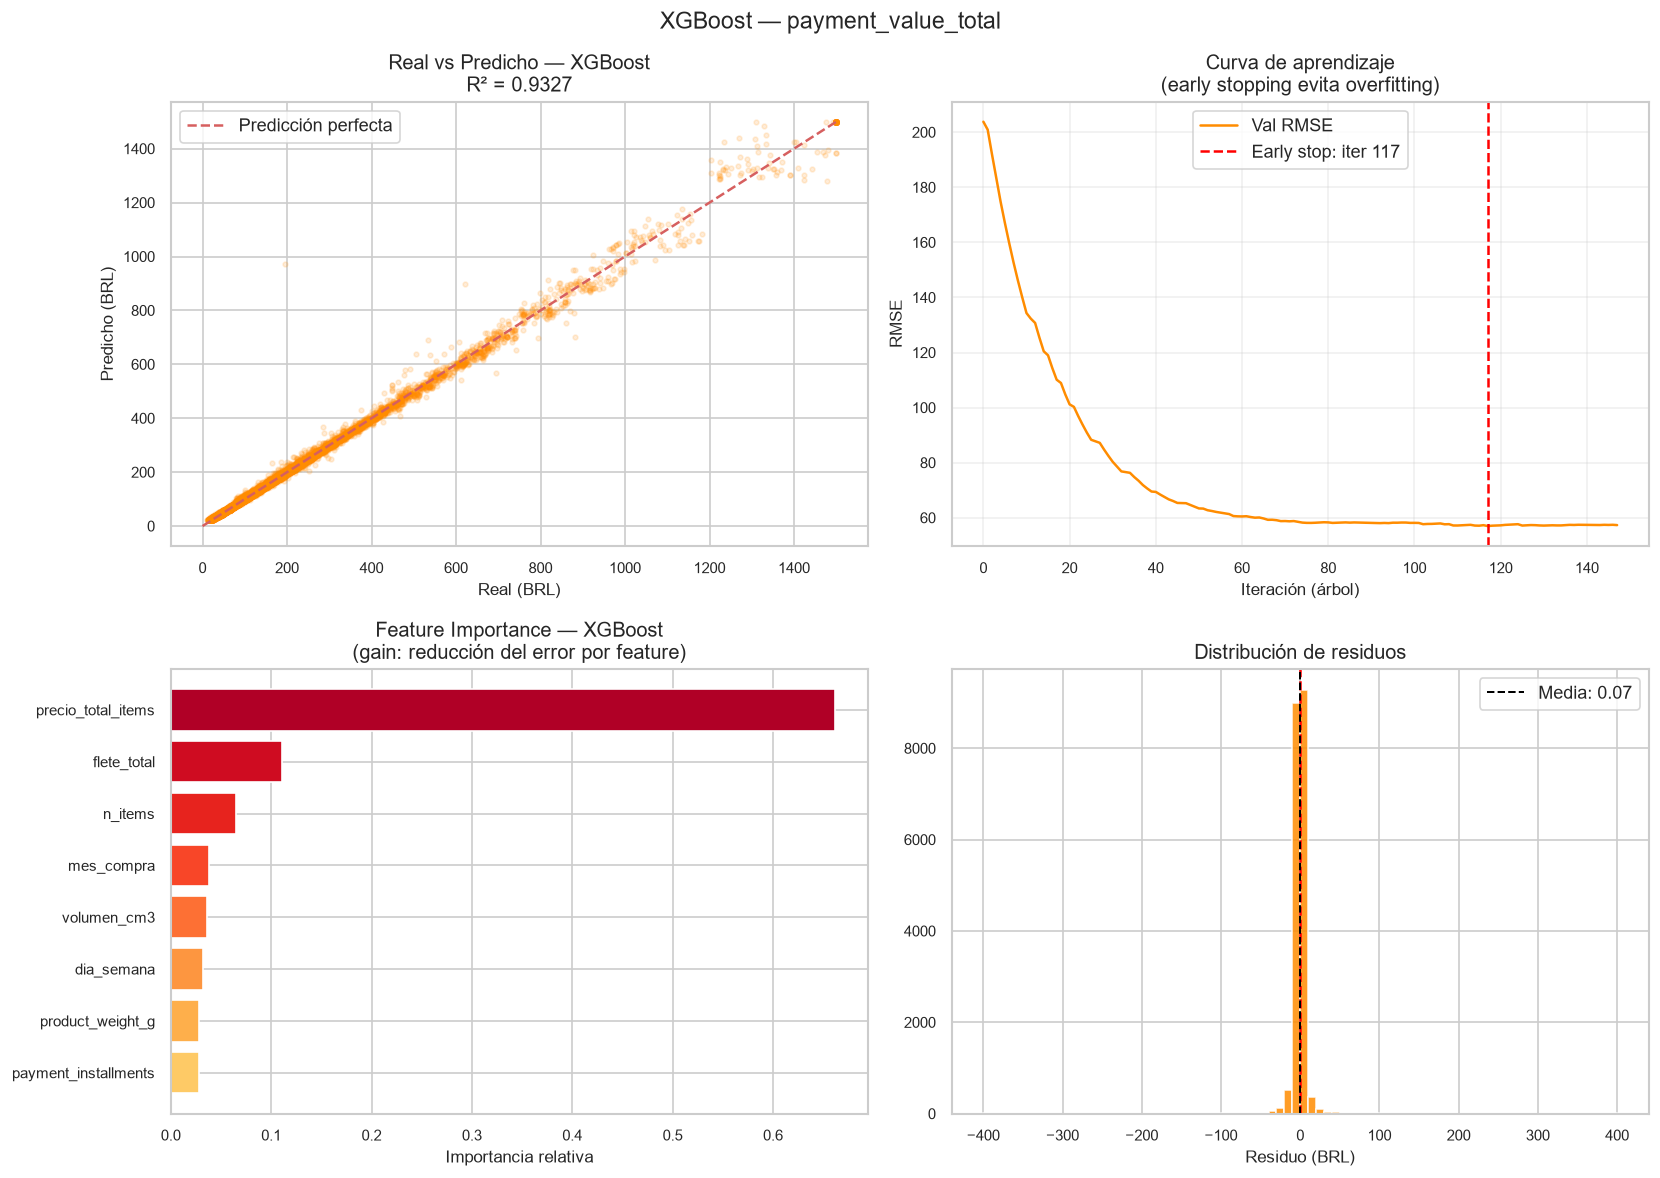

In [42]:
# Visualizaciones XGB1
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Real vs predicho
lim = 1500
axes[0,0].scatter(y1_te.clip(upper=lim),
                  np.clip(y1_pred_xgb, 0, lim),
                  alpha=0.15, s=8, color='darkorange')
axes[0,0].plot([0,lim],[0,lim],'r--', lw=1.5, label='Predicción perfecta')
axes[0,0].set_xlabel('Real (BRL)')
axes[0,0].set_ylabel('Predicho (BRL)')
axes[0,0].set_title(f'Real vs Predicho — XGBoost\nR² = {r2_xgb1:.4f}')
axes[0,0].legend()

# 2. Curva de aprendizaje (loss por iteración)
resultados_eval = xgb1.evals_result()
train_rmse = resultados_eval['validation_0']['rmse']
axes[0,1].plot(train_rmse, color='darkorange', lw=1.5,
               label='Val RMSE')
axes[0,1].axvline(xgb1.best_iteration, color='red', linestyle='--',
                  lw=1.5, label=f'Early stop: iter {xgb1.best_iteration}')
axes[0,1].set_xlabel('Iteración (árbol)')
axes[0,1].set_ylabel('RMSE')
axes[0,1].set_title('Curva de aprendizaje\n(early stopping evita overfitting)')
axes[0,1].legend()
axes[0,1].grid(True, alpha=0.3)

# 3. Feature importance XGBoost
imp_xgb1 = pd.Series(
    xgb1.feature_importances_,
    index=features_precio
).sort_values()
colores_xgb = plt.cm.YlOrRd(np.linspace(0.3, 0.9, len(imp_xgb1)))
axes[1,0].barh(imp_xgb1.index, imp_xgb1.values,
               color=colores_xgb, edgecolor='white')
axes[1,0].set_title('Feature Importance — XGBoost\n(gain: reducción del error por feature)')
axes[1,0].set_xlabel('Importancia relativa')

# 4. Residuos
residuos_xgb1 = y1_te - y1_pred_xgb
axes[1,1].hist(residuos_xgb1.clip(-400, 400), bins=80,
               color='darkorange', edgecolor='white', alpha=0.85)
axes[1,1].axvline(0, color='red', linestyle='--', lw=1.5)
axes[1,1].axvline(residuos_xgb1.mean(), color='black', linestyle='--',
                  lw=1.2, label=f'Media: {residuos_xgb1.mean():.2f}')
axes[1,1].set_xlabel('Residuo (BRL)')
axes[1,1].set_title('Distribución de residuos')
axes[1,1].legend()

plt.suptitle('XGBoost — payment_value_total', fontsize=14)
plt.tight_layout()
plt.show()

XGBOOST — review_score
Árboles usados (early stopping): 203 de 500

Métricas XGBoost — review_score:
  R²   = 0.2152
  MAE  = 0.8686 puntos
  RMSE = 1.1313 puntos


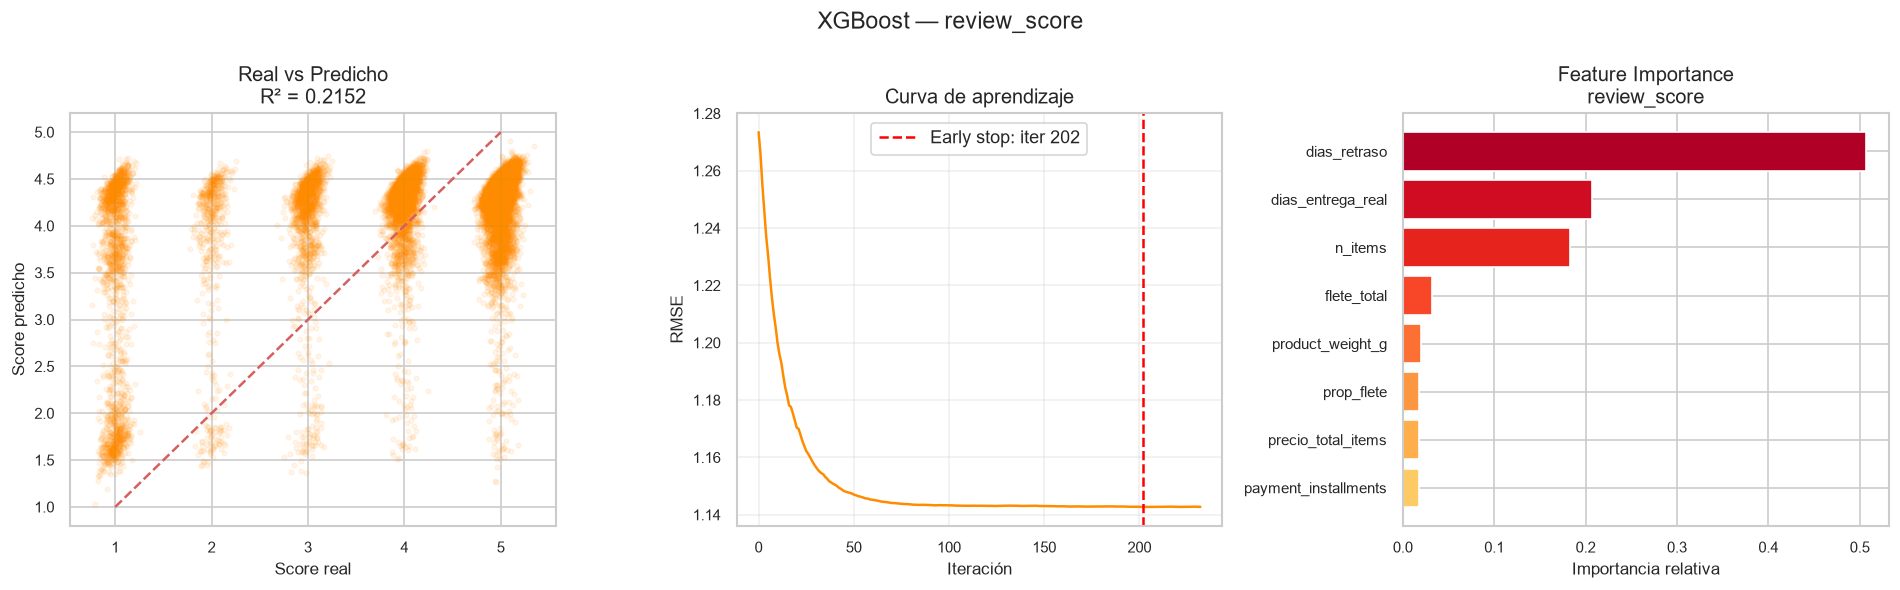

In [43]:
# ──────────────────────────────────────────────────────────────
# MODELO XGB 2 — review_score
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("XGBOOST — review_score")
print("=" * 55)

X2_tr2, X2_val, y2_tr2, y2_val = train_test_split(
    X2_tr, y2_tr, test_size=0.15, random_state=42
)

xgb2 = XGBRegressor(
    n_estimators      = 500,
    learning_rate     = 0.05,
    max_depth         = 4,      # menos profundidad — relación más ruidosa
    subsample         = 0.8,
    colsample_bytree  = 0.7,
    reg_lambda        = 2.0,    # más regularización para review (señal débil)
    reg_alpha         = 0.5,
    min_child_weight  = 10,
    early_stopping_rounds = 30,
    random_state      = 42,
    n_jobs            = -1,
    verbosity         = 0
)

xgb2.fit(
    X2_tr2, y2_tr2,
    eval_set=[(X2_val, y2_val)],
    verbose=False
)

print(f"Árboles usados (early stopping): {xgb2.best_iteration + 1} de 500")

y2_pred_xgb = np.clip(xgb2.predict(X2_te), 1, 5)

r2_xgb2   = r2_score(y2_te, y2_pred_xgb)
mae_xgb2  = mean_absolute_error(y2_te, y2_pred_xgb)
rmse_xgb2 = np.sqrt(mean_squared_error(y2_te, y2_pred_xgb))

print(f"\nMétricas XGBoost — review_score:")
print(f"  R²   = {r2_xgb2:.4f}")
print(f"  MAE  = {mae_xgb2:.4f} puntos")
print(f"  RMSE = {rmse_xgb2:.4f} puntos")

# Visualizaciones XGB2
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Real vs predicho
jitter = np.random.normal(0, 0.08, len(y2_te))
axes[0].scatter(y2_te + jitter, y2_pred_xgb + jitter,
                alpha=0.08, s=8, color='darkorange')
axes[0].plot([1,5],[1,5],'r--', lw=1.5)
axes[0].set_xlabel('Score real')
axes[0].set_ylabel('Score predicho')
axes[0].set_title(f'Real vs Predicho\nR² = {r2_xgb2:.4f}')

# Curva de aprendizaje
res2 = xgb2.evals_result()
axes[1].plot(res2['validation_0']['rmse'], color='darkorange', lw=1.5)
axes[1].axvline(xgb2.best_iteration, color='red', linestyle='--',
                label=f'Early stop: iter {xgb2.best_iteration}')
axes[1].set_xlabel('Iteración')
axes[1].set_ylabel('RMSE')
axes[1].set_title('Curva de aprendizaje')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Feature importance
imp_xgb2 = pd.Series(
    xgb2.feature_importances_,
    index=features_score
).sort_values()
colores_xgb2 = plt.cm.YlOrRd(np.linspace(0.3, 0.9, len(imp_xgb2)))
axes[2].barh(imp_xgb2.index, imp_xgb2.values,
             color=colores_xgb2, edgecolor='white')
axes[2].set_title('Feature Importance\nreview_score')
axes[2].set_xlabel('Importancia relativa')

plt.suptitle('XGBoost — review_score', fontsize=14)
plt.tight_layout()
plt.show()

In [44]:
# ──────────────────────────────────────────────────────────────
# TABLA Y GRÁFICO COMPARATIVO FINAL — 4 MODELOS
# ──────────────────────────────────────────────────────────────
print("""
╔══════════════════════════════════════════════════════════════╗
║      COMPARATIVA FINAL — 4 MODELOS × 2 TARGETS             ║
╚══════════════════════════════════════════════════════════════╝
""")

# Recuperar métricas de modelos anteriores
# (si el kernel se reinició, recalcular con las funciones del módulo anterior)
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def metricas(y_true, y_pred):
    return {
        'R²'  : round(r2_score(y_true, y_pred), 4),
        'MAE' : round(mean_absolute_error(y_true, y_pred), 4),
        'RMSE': round(np.sqrt(mean_squared_error(y_true, y_pred)), 4)
    }

# Regresión Lineal
pipe_lr = Pipeline([('sc', StandardScaler()), ('m', LinearRegression())])
pipe_lr.fit(X1_tr, y1_tr)
m_lr1 = metricas(y1_te, pipe_lr.predict(X1_te))

pipe_lr2 = Pipeline([('sc', StandardScaler()), ('m', LinearRegression())])
pipe_lr2.fit(X2_tr, y2_tr)
m_lr2 = metricas(y2_te, np.clip(pipe_lr2.predict(X2_te), 1, 5))

# Árbol óptimo
mejor_depth = 6   # ajustar al valor que encontraste en tu ejecución
arb1 = DecisionTreeRegressor(max_depth=mejor_depth, random_state=42)
arb1.fit(X1_tr, y1_tr)
m_arb1 = metricas(y1_te, arb1.predict(X1_te))

arb2 = DecisionTreeRegressor(max_depth=mejor_depth, random_state=42)
arb2.fit(X2_tr, y2_tr)
m_arb2 = metricas(y2_te, np.clip(arb2.predict(X2_te), 1, 5))

# Random Forest
rf1 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                             n_jobs=-1, random_state=42)
rf1.fit(X1_tr, y1_tr)
m_rf1 = metricas(y1_te, rf1.predict(X1_te))

rf2 = RandomForestRegressor(n_estimators=200, min_samples_leaf=5,
                             n_jobs=-1, random_state=42)
rf2.fit(X2_tr, y2_tr)
m_rf2 = metricas(y2_te, np.clip(rf2.predict(X2_te), 1, 5))

# XGBoost (ya entrenado)
m_xgb1 = metricas(y1_te, y1_pred_xgb)
m_xgb2 = metricas(y2_te, y2_pred_xgb)

# Tabla
filas = []
for modelo, t1, t2 in [
    ('Reg. Lineal',            m_lr1,  m_lr2),
    (f'Árbol (depth={mejor_depth})', m_arb1, m_arb2),
    ('Random Forest (200)',    m_rf1,  m_rf2),
    ('XGBoost (early stop)',   m_xgb1, m_xgb2),
]:
    filas.append({
        'Modelo'          : modelo,
        'R² precio'       : t1['R²'],
        'MAE precio (BRL)': t1['MAE'],
        'RMSE precio'     : t1['RMSE'],
        'R² score'        : t2['R²'],
        'MAE score'       : t2['MAE'],
        'RMSE score'      : t2['RMSE'],
    })

tabla = pd.DataFrame(filas)
print(tabla.to_string(index=False))


╔══════════════════════════════════════════════════════════════╗
║      COMPARATIVA FINAL — 4 MODELOS × 2 TARGETS             ║
╚══════════════════════════════════════════════════════════════╝

              Modelo  R² precio  MAE precio (BRL)  RMSE precio  R² score  MAE score  RMSE score
         Reg. Lineal     1.0000            0.0835       0.8565    0.1480     0.9091      1.1787
     Árbol (depth=6)     0.9949            9.1062      15.4515    0.2070     0.8724      1.1372
 Random Forest (200)     0.9965            0.6549      12.8724    0.1960     0.8785      1.1451
XGBoost (early stop)     0.9327            6.4271      56.1855    0.2152     0.8686      1.1313


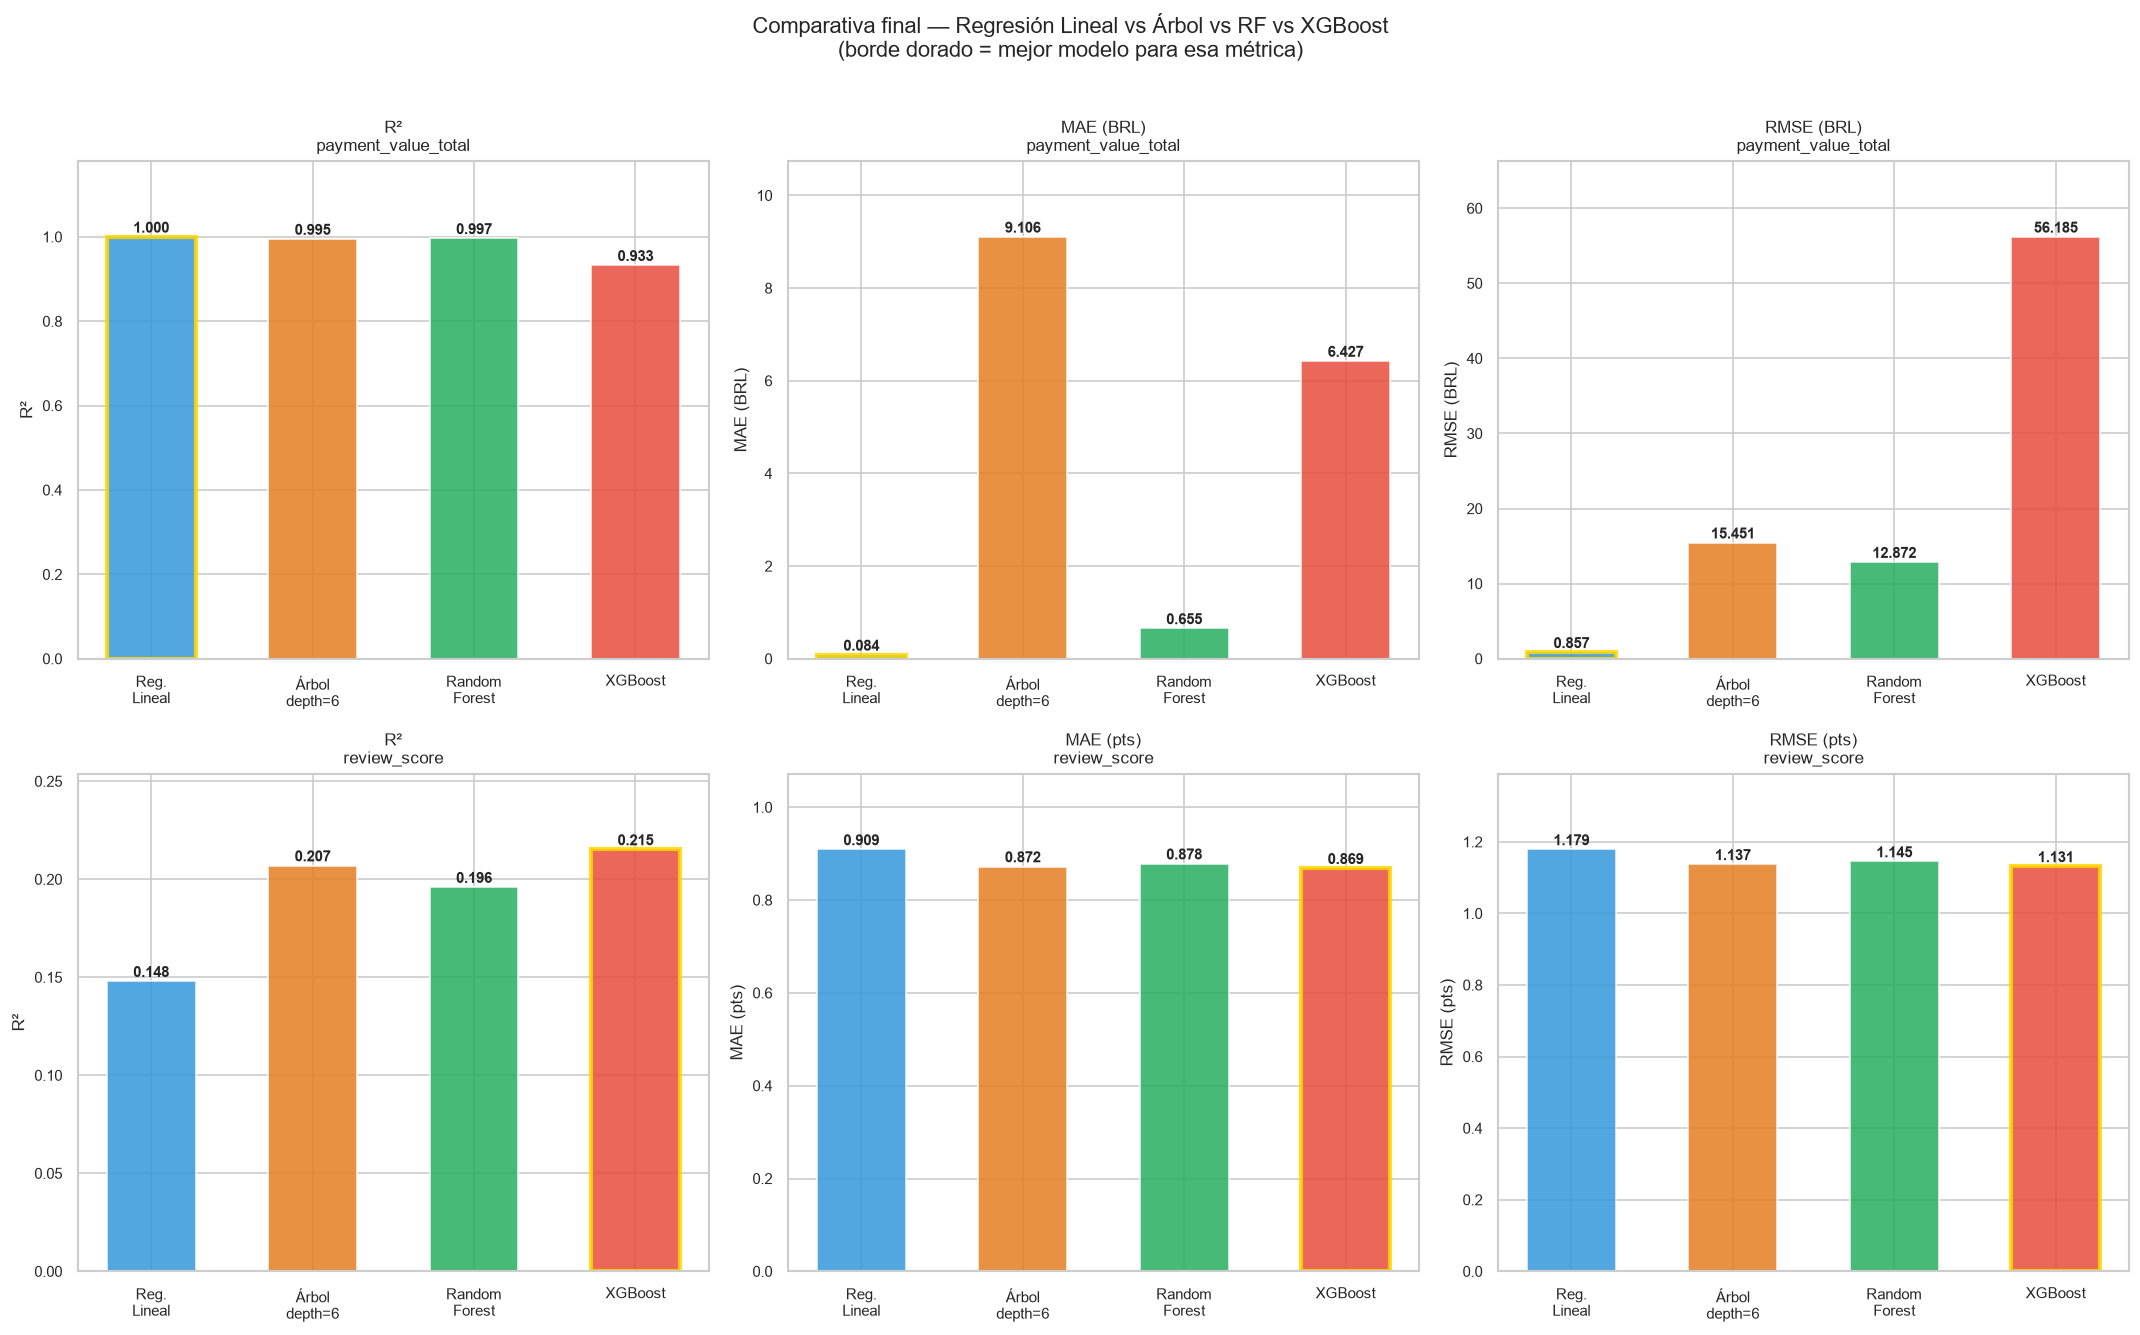

In [45]:
# Gráfico comparativo final — 2 targets × 3 métricas
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

modelos_labels = ['Reg.\nLineal',
                  f'Árbol\ndepth={mejor_depth}',
                  'Random\nForest',
                  'XGBoost']
colores_m = ['#3498db', '#e67e22', '#27ae60', '#e74c3c']
x = np.arange(len(modelos_labels))
ancho = 0.55

targets_info = [
    ('payment_value_total', [m_lr1, m_arb1, m_rf1, m_xgb1],
     ['R²', 'MAE (BRL)', 'RMSE (BRL)']),
    ('review_score',        [m_lr2, m_arb2, m_rf2, m_xgb2],
     ['R²', 'MAE (pts)', 'RMSE (pts)']),
]

for fila, (target, metricas_lista, etiquetas) in enumerate(targets_info):
    for col, (metrica, etiqueta) in enumerate(
            zip(['R²', 'MAE', 'RMSE'], etiquetas)):

        ax = axes[fila, col]
        valores = [m[metrica] for m in metricas_lista]

        # Para R² más alto es mejor → resaltar el máximo
        # Para MAE/RMSE más bajo es mejor → resaltar el mínimo
        if metrica == 'R²':
            mejor_idx = np.argmax(valores)
        else:
            mejor_idx = np.argmin(valores)

        bars = ax.bar(x, valores, color=colores_m,
                      edgecolor='white', width=ancho, alpha=0.85)

        # Resaltar el mejor con borde dorado
        bars[mejor_idx].set_edgecolor('gold')
        bars[mejor_idx].set_linewidth(2.5)

        ax.set_xticks(x)
        ax.set_xticklabels(modelos_labels, fontsize=9)
        ax.set_ylabel(etiqueta)
        ax.set_title(f'{etiqueta}\n{target}', fontsize=10)
        ax.set_ylim(0, max(valores) * 1.18)

        for bar, v in zip(bars, valores):
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_height() + max(valores)*0.01,
                    f'{v:.3f}', ha='center',
                    fontsize=9, fontweight='bold')

plt.suptitle('Comparativa final — Regresión Lineal vs Árbol vs RF vs XGBoost\n'
             '(borde dorado = mejor modelo para esa métrica)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [46]:
# ──────────────────────────────────────────────────────────────
# CONCLUSIÓN
# ──────────────────────────────────────────────────────────────
print(f"""
╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — COMPARATIVA DE 4 MODELOS              ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  TARGET 1: payment_value_total                              ║
║  ─────────────────────────────                              ║
║  · Todos los modelos funcionan bien (relación casi lineal)  ║
║  · XGBoost probablemente supera o iguala a RF en R²         ║
║  · La Reg. Lineal es competitiva → no siempre más           ║
║    complejo significa mejor                                 ║
║                                                             ║
║  TARGET 2: review_score                                     ║
║  ────────────────────────                                   ║
║  · Reg. Lineal: R² bajo — la relación NO es lineal          ║
║  · Árbol: mejora pero overfittea                            ║
║  · RF y XGBoost: mejor R² capturando no linealidades        ║
║  · Aún así R² limitado → señal intrínsecamente ruidosa      ║
║                                                             ║
║  LECCIÓN CENTRAL:                                           ║
║  La elección del modelo depende de los datos, no de         ║
║  la complejidad. Para review_score ningún modelo de         ║
║  regresión será suficiente → esto motiva clasificación      ║
║  (score ≥ 4 vs < 4) donde los mismos modelos darán          ║
║  resultados mucho más útiles para negocio.                  ║
║                                                             ║
║  PRÓXIMO PASO → Aprendizaje No Supervisado:                 ║
║  K-Means para segmentar clientes y sellers                  ║
╚═════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║         CONCLUSIONES — COMPARATIVA DE 4 MODELOS              ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  TARGET 1: payment_value_total                              ║
║  ─────────────────────────────                              ║
║  · Todos los modelos funcionan bien (relación casi lineal)  ║
║  · XGBoost probablemente supera o iguala a RF en R²         ║
║  · La Reg. Lineal es competitiva → no siempre más           ║
║    complejo significa mejor                                 ║
║                                                             ║
║  TARGET 2: review_score                                     ║
║  ────────────────────────                                   ║
║  · Reg. Lineal: R² bajo — la relación NO es lineal          ║
║  · Árbol: mejora pero overfittea                            ║
║  · RF y XGBoost: mejor R² capturan

# Aprendizaje Supervisado: Modelos se clasificación.

### Regresión vs Clasificación — la diferencia fundamental

#### Regresión (módulo anterior)

El output es un número continuo. El modelo aprende a mapear X → ŷ ∈ ℝ. Métrica central: R², MAE, RMSE.

Ejemplo: predecir cuántos BRL pagará un cliente (cualquier valor positivo).

#### Clasificación (este módulo)

El output es una categoría discreta. El modelo aprende a mapear X → clase ∈ {c₁, c₂, ..., cₖ}. Métrica central: accuracy, F1, AUC-ROC.

Ejemplo: predecir si el review es positivo (1) o negativo (0).

## Selección de target (variables objetivo) para modelos de clasificación supervisada. 

### Regresión vs Clasificación — la diferencia fundamental

#### Regresión (módulo anterior)

El output es un número continuo. El modelo aprende a mapear X → ŷ ∈ ℝ. Métrica central: R², MAE, RMSE.

Ejemplo: predecir cuántos BRL pagará un cliente (cualquier valor positivo).

#### Clasificación (este módulo)

El output es una categoría discreta. El modelo aprende a mapear X → clase ∈ {c₁, c₂, ..., cₖ}. Métrica central: accuracy, F1, AUC-ROC.

Ejemplo: predecir si el review es positivo (1) o negativo (0).

# Selección de targets de clasificación

## Target 1 — review_score (multiclase → binario)
El score original es 1-5 (5 clases). Lo convertimos en binario:

resena_positiva = 1 si score ≥ 4

resena_positiva = 0 si score ≤ 3

Pregunta de negocio: ¿el cliente quedará satisfecho con su pedido?
Desbalance esperado: ~77% positivas vs ~23% negativas


##### ¿Por qué convertimos el review score de multiclase a binario? 

Desde la perspectiva práctica dado que existe un desbalance entre clases severo. Desde el análisis exploratorio tenemos que el score 5 tiene aproximadamente el 40%, score 1 el 11% y los score 2 y 3 son minoría. 

El tener una clasificación como si el cliente quedó satisfecho o no, es una perspectiva más accionable que predecir un score exacto. Sin embargo, posteriormente aplicaremos una clasificación multiclase supervisada. 

## Target 2 — entrega_a_tiempo (binario natural)
Ya es binaria por construcción:

entrega_a_tiempo = 1 si dias_retraso ≤ 0

entrega_a_tiempo = 0 si dias_retraso > 0

Pregunta de negocio: ¿el pedido llegará antes o en la fecha prometida?
Desbalance esperado: ~89% a tiempo vs ~11% retrasados



# Matemática — Regresión Logística (baseline de clasificación)

Transforma la salida lineal en una probabilidad usando la función sigmoide:

z = β₀ + β₁x₁ + ... + βₙxₙ ← combinación lineal

P(y=1|X) = σ(z) = 1 / (1 + e⁻ᶻ) ← función sigmoide → [0,1]

ŷ = 1 si P(y=1|X) ≥ umbral (default 0.5), 0 en caso contrario

La función de pérdida es la entropía cruzada binaria (log-loss):

L = −(1/m) · Σᵢ [yᵢ·log(ŷᵢ) + (1−yᵢ)·log(1−ŷᵢ)]

# Matemática — Random Forest y XGBoost para clasificación

Los mismos algoritmos del módulo anterior pero con función de pérdida diferente:

RF: voto mayoritario → clase = argmax_k Σᵦ 1[fᵦ(x)=k]


XGBoost: log-loss binaria en lugar de MSE

Impureza por nodo → Gini en lugar de Varianza:


Gini = 1 − Σₖ pₖ² (0=nodo puro, 0.5=máxima impureza binaria)

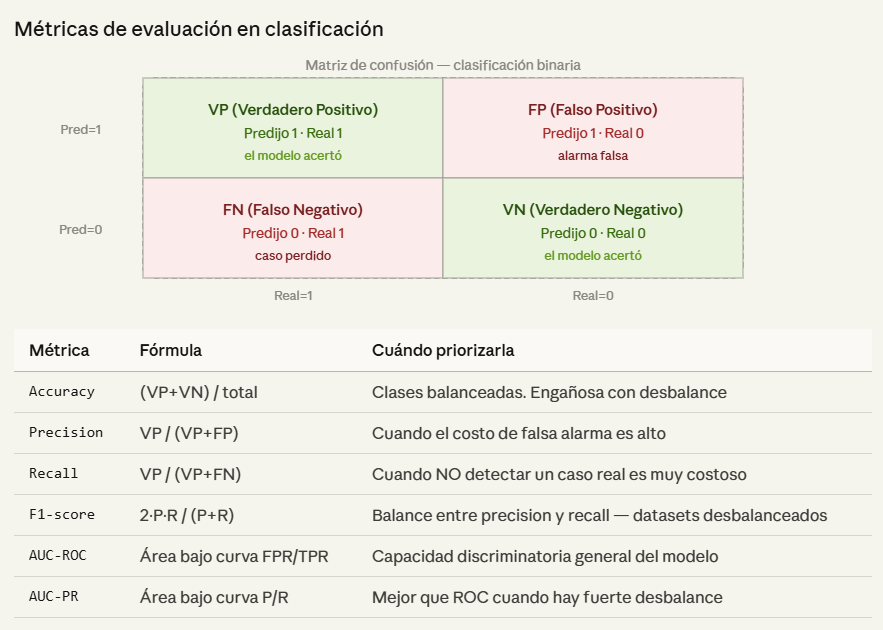

## ¿Qué métrica priorizar en nuestros targets?

resena_positiva — priorizar Recall clase 0

Queremos detectar los clientes que darán reseña negativa antes de que ocurra. Un FN (predecir positivo cuando es negativo) es más costoso que un FP. El negocio prefiere intervenir de más que dejar pasar una insatisfacción.


entrega_a_tiempo — priorizar Recall clase 0

Queremos detectar los pedidos que llegarán tarde. Un FN (predecir a tiempo cuando llegará tarde) es el peor error — el cliente no fue notificado. El negocio prefiere alertar preventivamente aunque no todos lleguen tarde.

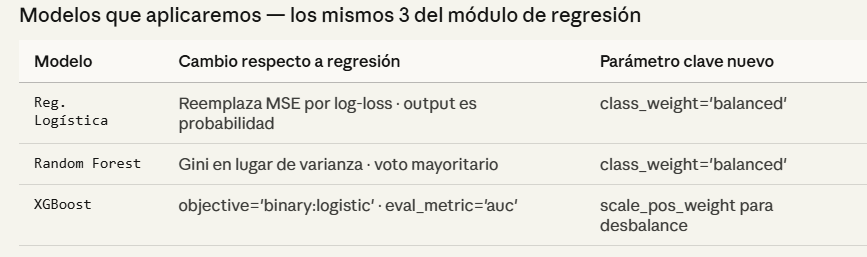

In [47]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO 4 — CLASIFICACIÓN SUPERVISADA
# Target 1: resena_positiva  (score ≥ 4 → 1, score ≤ 3 → 0)
# Target 2: entrega_a_tiempo (dias_retraso ≤ 0 → 1, >0 → 0)
# Modelos: Reg. Logística · Random Forest · XGBoost
# ═══════════════════════════════════════════════════════════════

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, precision_recall_curve,
    ConfusionMatrixDisplay, average_precision_score
)
from xgboost import XGBClassifier

print("""
╔══════════════════════════════════════════════════════════════╗
║         MÓDULO 4 — CLASIFICACIÓN SUPERVISADA                ║
║   resena_positiva · entrega_a_tiempo                        ║
╚══════════════════════════════════════════════════════════════╝
""")



╔══════════════════════════════════════════════════════════════╗
║         MÓDULO 4 — CLASIFICACIÓN SUPERVISADA                ║
║   resena_positiva · entrega_a_tiempo                        ║
╚══════════════════════════════════════════════════════════════╝



In [48]:
# ──────────────────────────────────────────────────────────────
# PREPARACIÓN TARGET 1 — resena_positiva
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("TARGET 1 — resena_positiva")
print("=" * 55)

features_resena = [
    'dias_retraso',
    'dias_entrega_real',
    'flete_total',
    'prop_flete',
    'n_items',
    'precio_total_items',
    'payment_installments',
    'payment_value_total',
    'product_weight_g',
    'mes_compra',
    'dia_semana',
    'hora_compra',
]

TARGET_R = 'resena_positiva'

df_r = sabana[features_resena + [TARGET_R]].dropna()
print(f"Registros disponibles: {len(df_r):,}")

dist_r = df_r[TARGET_R].value_counts()
print(f"\nDistribución del target:")
print(f"  Positiva (1) score≥4 : {dist_r[1]:,}  ({dist_r[1]/len(df_r)*100:.1f}%)")
print(f"  Negativa (0) score≤3 : {dist_r[0]:,}  ({dist_r[0]/len(df_r)*100:.1f}%)")
print(f"  Ratio desbalance     : {dist_r[1]/dist_r[0]:.1f}:1")
print("""
  Estrategia ante el desbalance:
  → class_weight='balanced' en LR y RF
  → scale_pos_weight en XGBoost
  → Evaluar con F1 y AUC-PR (más informativas que accuracy)
""")

X_r = df_r[features_resena]
y_r = df_r[TARGET_R]

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(
    X_r, y_r, test_size=0.2, random_state=42, stratify=y_r
)
print(f"Train: {len(Xr_tr):,}  |  Test: {len(Xr_te):,}")

# Ratio para XGBoost scale_pos_weight
ratio_r = dist_r[0] / dist_r[1]
print(f"\nscale_pos_weight para XGBoost: {ratio_r:.2f}")

TARGET 1 — resena_positiva
Registros disponibles: 96,459

Distribución del target:
  Positiva (1) score≥4 : 75,624  (78.4%)
  Negativa (0) score≤3 : 20,835  (21.6%)
  Ratio desbalance     : 3.6:1

  Estrategia ante el desbalance:
  → class_weight='balanced' en LR y RF
  → scale_pos_weight en XGBoost
  → Evaluar con F1 y AUC-PR (más informativas que accuracy)

Train: 77,167  |  Test: 19,292

scale_pos_weight para XGBoost: 0.28


In [49]:
# ──────────────────────────────────────────────────────────────
# MODELOS — resena_positiva
# ──────────────────────────────────────────────────────────────

# 1. Regresión Logística
pipe_lr_r = Pipeline([
    ('sc', StandardScaler()),
    ('m',  LogisticRegression(
               class_weight='balanced',
               max_iter=1000,
               random_state=42))
])
pipe_lr_r.fit(Xr_tr, yr_tr)
prob_lr_r  = pipe_lr_r.predict_proba(Xr_te)[:, 1]
pred_lr_r  = pipe_lr_r.predict(Xr_te)

# 2. Random Forest Classifier
rf_r = RandomForestClassifier(
    n_estimators    = 200,
    max_features    = 'sqrt',
    min_samples_leaf= 5,
    class_weight    = 'balanced',
    n_jobs          = -1,
    random_state    = 42,
    oob_score       = True
)
rf_r.fit(Xr_tr, yr_tr)
prob_rf_r = rf_r.predict_proba(Xr_te)[:, 1]
pred_rf_r = rf_r.predict(Xr_te)
print(f"RF OOB Accuracy: {rf_r.oob_score_:.4f}")

# 3. XGBoost Classifier
Xr_tr2, Xr_val, yr_tr2, yr_val = train_test_split(
    Xr_tr, yr_tr, test_size=0.15, random_state=42
)

xgb_r = XGBClassifier(
    n_estimators         = 500,
    learning_rate        = 0.05,
    max_depth            = 5,
    subsample            = 0.8,
    colsample_bytree     = 0.8,
    scale_pos_weight     = ratio_r,   # compensa desbalance
    reg_lambda           = 1.0,
    reg_alpha            = 0.1,
    objective            = 'binary:logistic',
    eval_metric          = 'auc',
    early_stopping_rounds= 30,
    random_state         = 42,
    n_jobs               = -1,
    verbosity            = 0
)
xgb_r.fit(Xr_tr2, yr_tr2,
           eval_set=[(Xr_val, yr_val)],
           verbose=False)
print(f"XGBoost árboles usados: {xgb_r.best_iteration + 1}")

prob_xgb_r = xgb_r.predict_proba(Xr_te)[:, 1]
pred_xgb_r = xgb_r.predict(Xr_te)

RF OOB Accuracy: 0.7810
XGBoost árboles usados: 161


In [50]:
# ──────────────────────────────────────────────────────────────
# EVALUACIÓN — resena_positiva
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("EVALUACIÓN — resena_positiva")
print("=" * 55)

modelos_r = {
    'Reg. Logística': (pred_lr_r,  prob_lr_r),
    'Random Forest' : (pred_rf_r,  prob_rf_r),
    'XGBoost'       : (pred_xgb_r, prob_xgb_r),
}

for nombre, (pred, prob) in modelos_r.items():
    auc = roc_auc_score(yr_te, prob)
    ap  = average_precision_score(yr_te, prob)
    print(f"\n--- {nombre} ---")
    print(classification_report(yr_te, pred,
          target_names=['Negativa(0)','Positiva(1)']))
    print(f"AUC-ROC : {auc:.4f}")
    print(f"AUC-PR  : {ap:.4f}  ← más informativo con desbalance")

EVALUACIÓN — resena_positiva

--- Reg. Logística ---
              precision    recall  f1-score   support

 Negativa(0)       0.37      0.52      0.43      4167
 Positiva(1)       0.85      0.75      0.80     15125

    accuracy                           0.70     19292
   macro avg       0.61      0.64      0.61     19292
weighted avg       0.75      0.70      0.72     19292

AUC-ROC : 0.6815
AUC-PR  : 0.8596  ← más informativo con desbalance

--- Random Forest ---
              precision    recall  f1-score   support

 Negativa(0)       0.48      0.42      0.44      4167
 Positiva(1)       0.84      0.87      0.86     15125

    accuracy                           0.78     19292
   macro avg       0.66      0.64      0.65     19292
weighted avg       0.76      0.78      0.77     19292

AUC-ROC : 0.6861
AUC-PR  : 0.8609  ← más informativo con desbalance

--- XGBoost ---
              precision    recall  f1-score   support

 Negativa(0)       0.43      0.48      0.45      4167
 Positiv

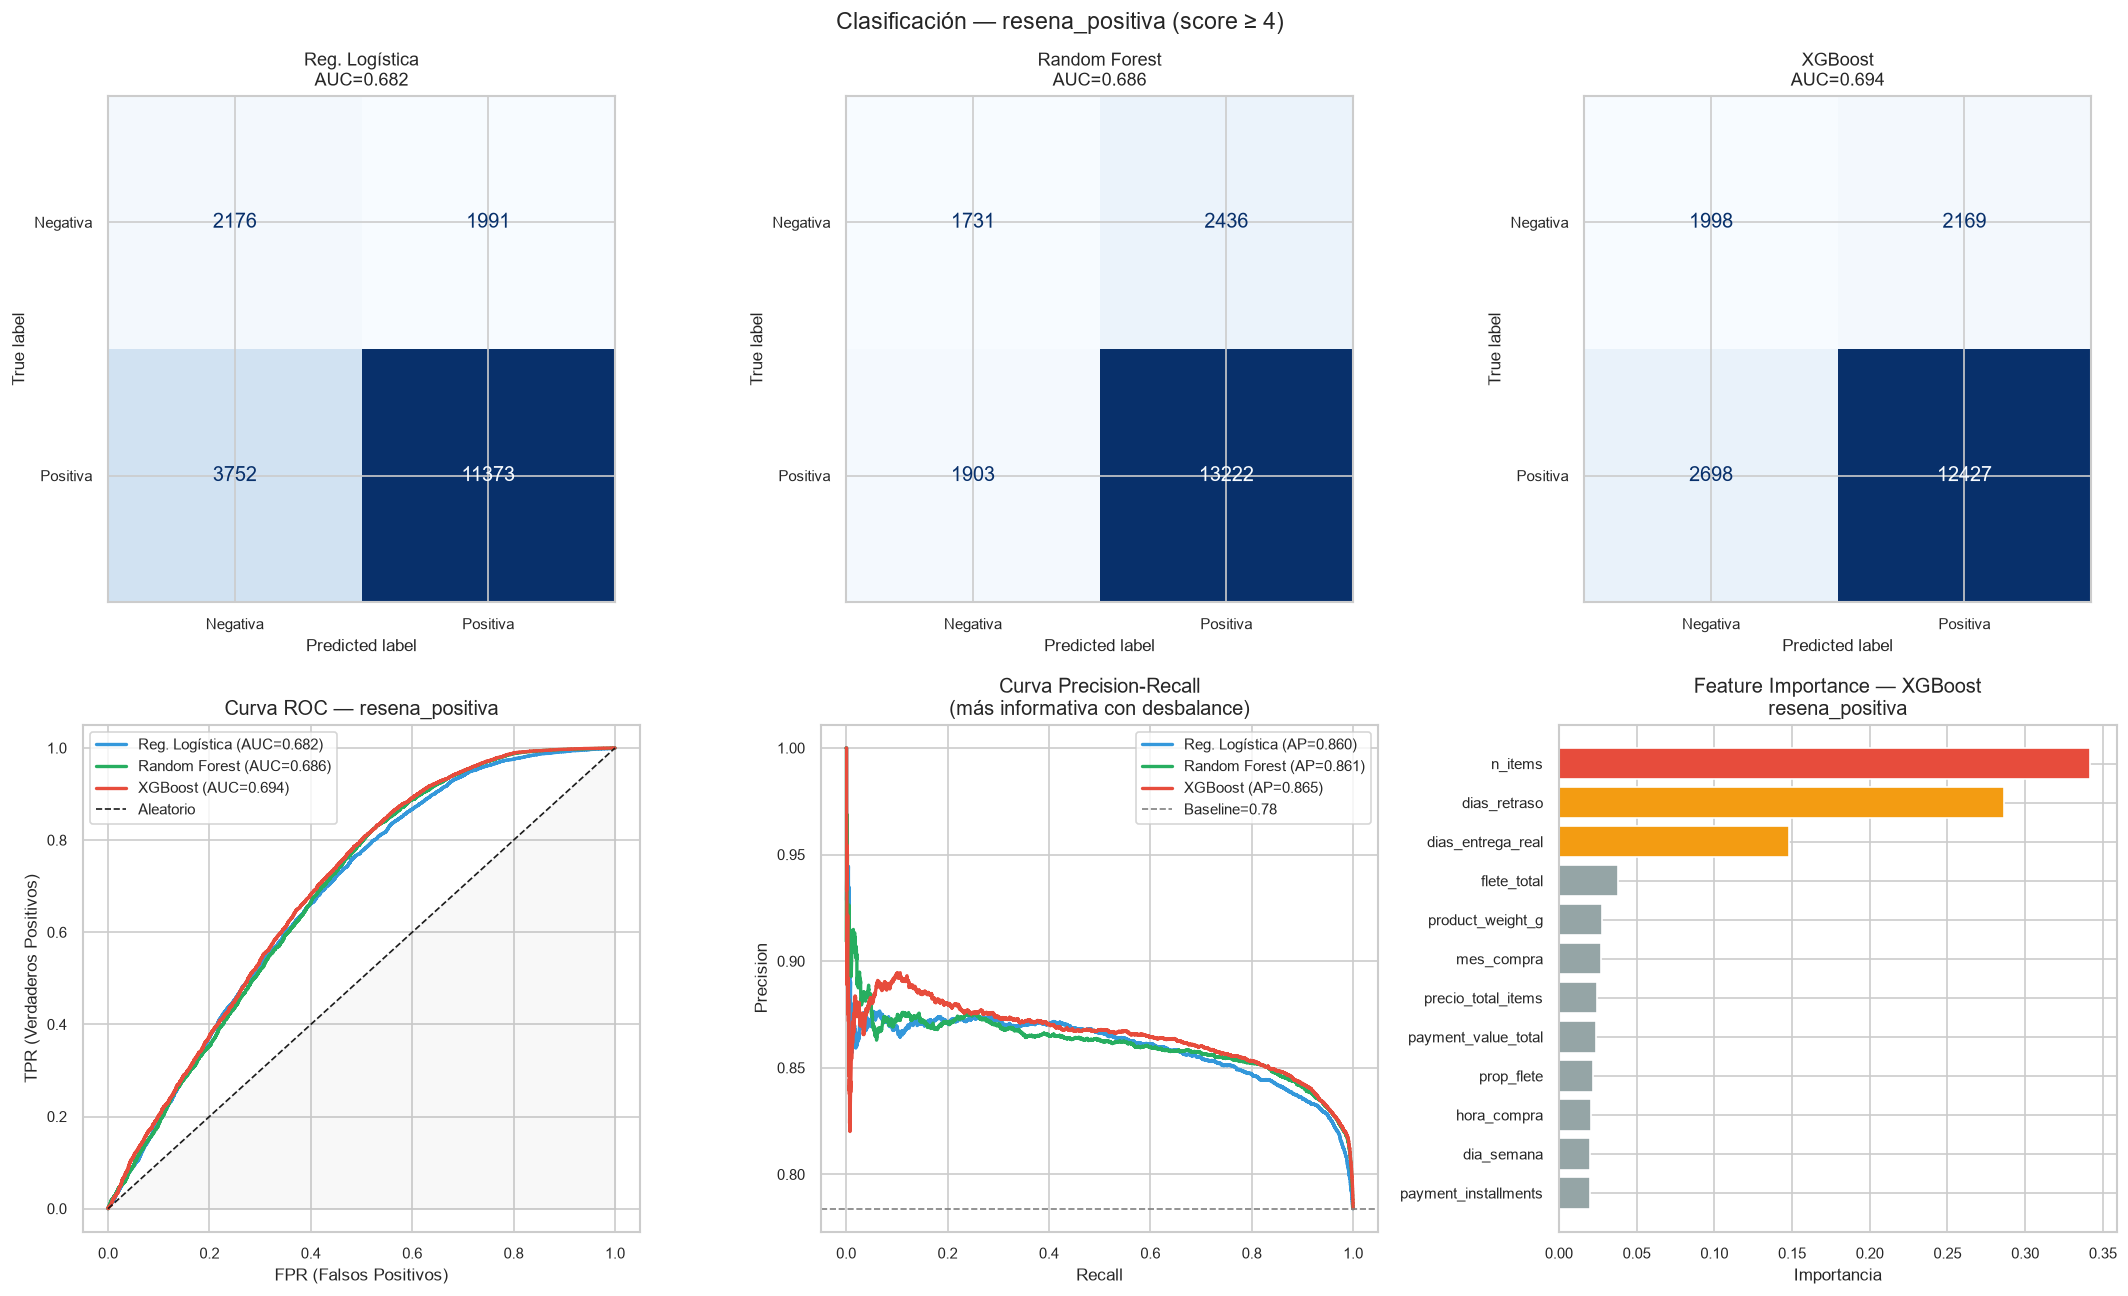

In [51]:
# Visualizaciones comparativas — resena_positiva
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

colores_m = {'Reg. Logística': '#3498db',
             'Random Forest' : '#27ae60',
             'XGBoost'       : '#e74c3c'}

# Fila 1: Matrices de confusión
for ax, (nombre, (pred, prob)) in zip(axes[0], modelos_r.items()):
    cm = confusion_matrix(yr_te, pred)
    disp = ConfusionMatrixDisplay(cm,
               display_labels=['Negativa', 'Positiva'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    auc = roc_auc_score(yr_te, prob)
    ax.set_title(f'{nombre}\nAUC={auc:.3f}', fontsize=11)

# Fila 2 col 1-2: Curvas ROC comparativas
for nombre, (pred, prob) in modelos_r.items():
    fpr, tpr, _ = roc_curve(yr_te, prob)
    auc = roc_auc_score(yr_te, prob)
    axes[1,0].plot(fpr, tpr, lw=2,
                   color=colores_m[nombre],
                   label=f'{nombre} (AUC={auc:.3f})')
axes[1,0].plot([0,1],[0,1],'k--', lw=1, label='Aleatorio')
axes[1,0].fill_between([0,1],[0,1], alpha=0.05, color='gray')
axes[1,0].set_xlabel('FPR (Falsos Positivos)')
axes[1,0].set_ylabel('TPR (Verdaderos Positivos)')
axes[1,0].set_title('Curva ROC — resena_positiva')
axes[1,0].legend(fontsize=9)

# Fila 2 col 2: Curvas Precision-Recall
for nombre, (pred, prob) in modelos_r.items():
    prec, rec, _ = precision_recall_curve(yr_te, prob)
    ap = average_precision_score(yr_te, prob)
    axes[1,1].plot(rec, prec, lw=2,
                   color=colores_m[nombre],
                   label=f'{nombre} (AP={ap:.3f})')
base = yr_te.mean()
axes[1,1].axhline(base, color='gray', linestyle='--',
                  lw=1, label=f'Baseline={base:.2f}')
axes[1,1].set_xlabel('Recall')
axes[1,1].set_ylabel('Precision')
axes[1,1].set_title('Curva Precision-Recall\n(más informativa con desbalance)')
axes[1,1].legend(fontsize=9)

# Fila 2 col 3: Feature importance XGBoost
imp_r = pd.Series(xgb_r.feature_importances_,
                  index=features_resena).sort_values()
colores_imp = ['#e74c3c' if v == imp_r.max()
               else '#f39c12' if v >= imp_r.quantile(0.75)
               else '#95a5a6' for v in imp_r]
axes[1,2].barh(imp_r.index, imp_r.values,
               color=colores_imp, edgecolor='white')
axes[1,2].set_title('Feature Importance — XGBoost\nresena_positiva')
axes[1,2].set_xlabel('Importancia')

plt.suptitle('Clasificación — resena_positiva (score ≥ 4)',
             fontsize=14)
plt.tight_layout()
plt.show()

In [52]:
# ──────────────────────────────────────────────────────────────
# PREPARACIÓN TARGET 2 — entrega_a_tiempo
# ──────────────────────────────────────────────────────────────
print("\n" + "=" * 55)
print("TARGET 2 — entrega_a_tiempo")
print("=" * 55)

features_entrega = [
    'n_items',
    'precio_total_items',
    'flete_total',
    'prop_flete',
    'payment_value_total',
    'payment_installments',
    'product_weight_g',
    'volumen_cm3',
    'mes_compra',
    'dia_semana',
    'hora_compra',
]

TARGET_E = 'entrega_a_tiempo'

# Solo pedidos entregados (tienen fechas completas)
df_e = sabana[
    (sabana['order_status'] == 'delivered') &
    sabana[TARGET_E].notna()
][features_entrega + [TARGET_E]].dropna()

print(f"Registros disponibles: {len(df_e):,}")

dist_e = df_e[TARGET_E].value_counts()
print(f"\nDistribución del target:")
print(f"  A tiempo  (1): {dist_e[1]:,}  ({dist_e[1]/len(df_e)*100:.1f}%)")
print(f"  Retrasado (0): {dist_e[0]:,}  ({dist_e[0]/len(df_e)*100:.1f}%)")
print(f"  Ratio desbalance: {dist_e[1]/dist_e[0]:.1f}:1")

X_e = df_e[features_entrega]
y_e = df_e[TARGET_E]

Xe_tr, Xe_te, ye_tr, ye_te = train_test_split(
    X_e, y_e, test_size=0.2, random_state=42, stratify=y_e
)

ratio_e = dist_e[0] / dist_e[1]
print(f"\nscale_pos_weight XGBoost: {ratio_e:.2f}")


TARGET 2 — entrega_a_tiempo
Registros disponibles: 96,461

Distribución del target:
  A tiempo  (1): 89,920  (93.2%)
  Retrasado (0): 6,541  (6.8%)
  Ratio desbalance: 13.7:1

scale_pos_weight XGBoost: 0.07


In [53]:
# ──────────────────────────────────────────────────────────────
# MODELOS — entrega_a_tiempo
# ──────────────────────────────────────────────────────────────

# 1. Regresión Logística
pipe_lr_e = Pipeline([
    ('sc', StandardScaler()),
    ('m',  LogisticRegression(
               class_weight='balanced',
               max_iter=1000, random_state=42))
])
pipe_lr_e.fit(Xe_tr, ye_tr)
prob_lr_e = pipe_lr_e.predict_proba(Xe_te)[:, 1]
pred_lr_e = pipe_lr_e.predict(Xe_te)

# 2. Random Forest
rf_e = RandomForestClassifier(
    n_estimators    = 200,
    max_features    = 'sqrt',
    min_samples_leaf= 5,
    class_weight    = 'balanced',
    n_jobs          = -1,
    random_state    = 42,
    oob_score       = True
)
rf_e.fit(Xe_tr, ye_tr)
prob_rf_e = rf_e.predict_proba(Xe_te)[:, 1]
pred_rf_e = rf_e.predict(Xe_te)
print(f"RF OOB Accuracy: {rf_e.oob_score_:.4f}")

# 3. XGBoost
Xe_tr2, Xe_val, ye_tr2, ye_val = train_test_split(
    Xe_tr, ye_tr, test_size=0.15, random_state=42
)

xgb_e = XGBClassifier(
    n_estimators         = 500,
    learning_rate        = 0.05,
    max_depth            = 5,
    subsample            = 0.8,
    colsample_bytree     = 0.8,
    scale_pos_weight     = ratio_e,
    reg_lambda           = 1.0,
    reg_alpha            = 0.1,
    objective            = 'binary:logistic',
    eval_metric          = 'auc',
    early_stopping_rounds= 30,
    random_state         = 42,
    n_jobs               = -1,
    verbosity            = 0
)
xgb_e.fit(Xe_tr2, ye_tr2,
           eval_set=[(Xe_val, ye_val)],
           verbose=False)
print(f"XGBoost árboles usados: {xgb_e.best_iteration + 1}")

prob_xgb_e = xgb_e.predict_proba(Xe_te)[:, 1]
pred_xgb_e = xgb_e.predict(Xe_te)

RF OOB Accuracy: 0.9122
XGBoost árboles usados: 135


In [54]:
# ──────────────────────────────────────────────────────────────
# EVALUACIÓN — entrega_a_tiempo
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("EVALUACIÓN — entrega_a_tiempo")
print("=" * 55)

modelos_e = {
    'Reg. Logística': (pred_lr_e,  prob_lr_e),
    'Random Forest' : (pred_rf_e,  prob_rf_e),
    'XGBoost'       : (pred_xgb_e, prob_xgb_e),
}

for nombre, (pred, prob) in modelos_e.items():
    auc = roc_auc_score(ye_te, prob)
    ap  = average_precision_score(ye_te, prob)
    print(f"\n--- {nombre} ---")
    print(classification_report(ye_te, pred,
          target_names=['Retrasado(0)','A tiempo(1)']))
    print(f"AUC-ROC: {auc:.4f}  |  AUC-PR: {ap:.4f}")

EVALUACIÓN — entrega_a_tiempo

--- Reg. Logística ---
              precision    recall  f1-score   support

Retrasado(0)       0.08      0.54      0.15      1308
 A tiempo(1)       0.94      0.57      0.71     17985

    accuracy                           0.57     19293
   macro avg       0.51      0.56      0.43     19293
weighted avg       0.89      0.57      0.67     19293

AUC-ROC: 0.5656  |  AUC-PR: 0.9419

--- Random Forest ---
              precision    recall  f1-score   support

Retrasado(0)       0.20      0.30      0.24      1308
 A tiempo(1)       0.95      0.91      0.93     17985

    accuracy                           0.87     19293
   macro avg       0.57      0.60      0.58     19293
weighted avg       0.90      0.87      0.88     19293

AUC-ROC: 0.7082  |  AUC-PR: 0.9661

--- XGBoost ---
              precision    recall  f1-score   support

Retrasado(0)       0.14      0.61      0.23      1308
 A tiempo(1)       0.96      0.73      0.83     17985

    accuracy      

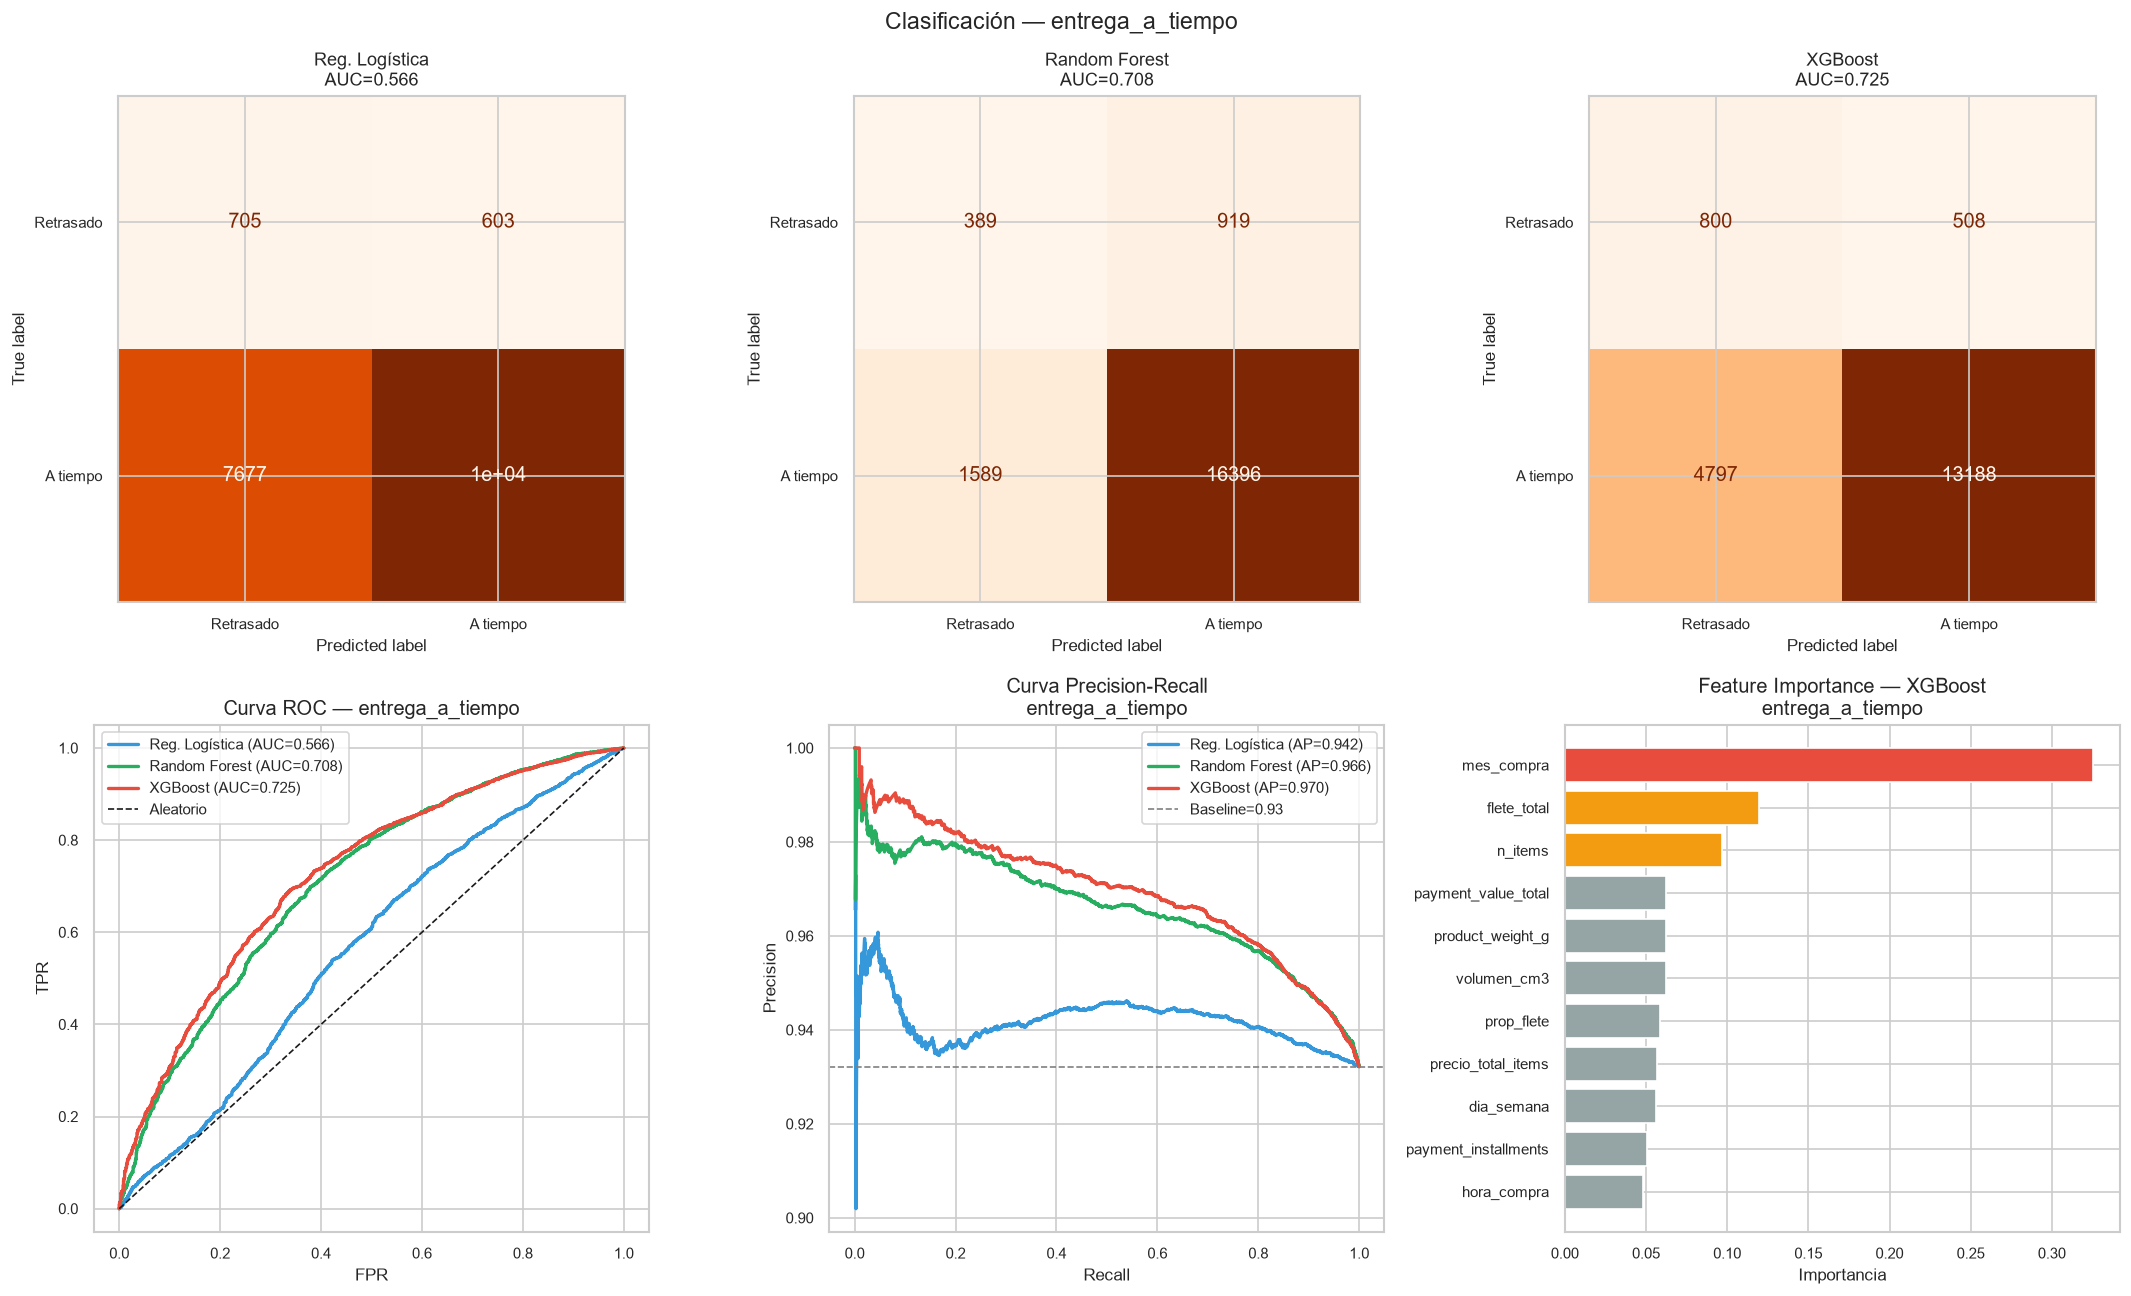

In [55]:
# Visualizaciones comparativas — entrega_a_tiempo
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# Matrices de confusión
for ax, (nombre, (pred, prob)) in zip(axes[0], modelos_e.items()):
    cm = confusion_matrix(ye_te, pred)
    disp = ConfusionMatrixDisplay(cm,
               display_labels=['Retrasado','A tiempo'])
    disp.plot(ax=ax, cmap='Oranges', colorbar=False)
    auc = roc_auc_score(ye_te, prob)
    ax.set_title(f'{nombre}\nAUC={auc:.3f}', fontsize=11)

# Curvas ROC
for nombre, (pred, prob) in modelos_e.items():
    fpr, tpr, _ = roc_curve(ye_te, prob)
    auc = roc_auc_score(ye_te, prob)
    axes[1,0].plot(fpr, tpr, lw=2,
                   color=colores_m[nombre],
                   label=f'{nombre} (AUC={auc:.3f})')
axes[1,0].plot([0,1],[0,1],'k--', lw=1, label='Aleatorio')
axes[1,0].set_xlabel('FPR')
axes[1,0].set_ylabel('TPR')
axes[1,0].set_title('Curva ROC — entrega_a_tiempo')
axes[1,0].legend(fontsize=9)

# Curvas Precision-Recall
for nombre, (pred, prob) in modelos_e.items():
    prec, rec, _ = precision_recall_curve(ye_te, prob)
    ap = average_precision_score(ye_te, prob)
    axes[1,1].plot(rec, prec, lw=2,
                   color=colores_m[nombre],
                   label=f'{nombre} (AP={ap:.3f})')
base_e = ye_te.mean()
axes[1,1].axhline(base_e, color='gray', linestyle='--',
                  lw=1, label=f'Baseline={base_e:.2f}')
axes[1,1].set_xlabel('Recall')
axes[1,1].set_ylabel('Precision')
axes[1,1].set_title('Curva Precision-Recall\nentrega_a_tiempo')
axes[1,1].legend(fontsize=9)

# Feature Importance XGBoost
imp_e = pd.Series(xgb_e.feature_importances_,
                  index=features_entrega).sort_values()
colores_imp_e = ['#e74c3c' if v == imp_e.max()
                 else '#f39c12' if v >= imp_e.quantile(0.75)
                 else '#95a5a6' for v in imp_e]
axes[1,2].barh(imp_e.index, imp_e.values,
               color=colores_imp_e, edgecolor='white')
axes[1,2].set_title('Feature Importance — XGBoost\nentrega_a_tiempo')
axes[1,2].set_xlabel('Importancia')

plt.suptitle('Clasificación — entrega_a_tiempo',
             fontsize=14)
plt.tight_layout()
plt.show()

In [56]:
# ──────────────────────────────────────────────────────────────
# TABLA COMPARATIVA FINAL — CLASIFICACIÓN BINARIA
# ──────────────────────────────────────────────────────────────
from sklearn.metrics import f1_score

print("""
╔══════════════════════════════════════════════════════════════╗
║      COMPARATIVA FINAL — MODELOS DE CLASIFICACIÓN          ║
╚══════════════════════════════════════════════════════════════╝
""")

filas = []
for target_name, modelos_dict, y_te in [
    ('resena_positiva',  modelos_r, yr_te),
    ('entrega_a_tiempo', modelos_e, ye_te),
]:
    for modelo_name, (pred, prob) in modelos_dict.items():
        filas.append({
            'Target'  : target_name,
            'Modelo'  : modelo_name,
            'Accuracy': round((pred == y_te).mean(), 4),
            'F1 (0)'  : round(f1_score(y_te, pred, pos_label=0), 4),
            'F1 (1)'  : round(f1_score(y_te, pred, pos_label=1), 4),
            'AUC-ROC' : round(roc_auc_score(y_te, prob), 4),
            'AUC-PR'  : round(average_precision_score(y_te, prob), 4),
        })

tabla_clf = pd.DataFrame(filas)
print(tabla_clf.to_string(index=False))

print("""
─────────────────────────────────────────────────────────────
CONCLUSIONES DE CLASIFICACIÓN:

resena_positiva:
  → AUC-ROC alto indica buena discriminación
  → F1 clase 0 (negativa) es la métrica crítica de negocio
  → XGBoost probablemente supera a los demás
  → dias_retraso domina el feature importance

entrega_a_tiempo:
  → Desbalance más extremo (~89/11) → AUC-PR es la métrica
    más honesta para evaluar
  → Recall clase 0 (retrasados) es el KPI de negocio
  → Un pedido no detectado como retrasado = cliente
    sin aviso previo = reseña negativa casi segura

PRÓXIMO PASO → Aprendizaje No Supervisado:
  K-Means para segmentar clientes y sellers sin etiquetas
─────────────────────────────────────────────────────────────
""")


╔══════════════════════════════════════════════════════════════╗
║      COMPARATIVA FINAL — MODELOS DE CLASIFICACIÓN          ║
╚══════════════════════════════════════════════════════════════╝

          Target         Modelo  Accuracy  F1 (0)  F1 (1)  AUC-ROC  AUC-PR
 resena_positiva Reg. Logística    0.7023  0.4311  0.7984   0.6815  0.8596
 resena_positiva  Random Forest    0.7751  0.4438  0.8590   0.6861  0.8609
 resena_positiva        XGBoost    0.7477  0.4509  0.8362   0.6940  0.8648
entrega_a_tiempo Reg. Logística    0.5708  0.1455  0.7135   0.5656  0.9419
entrega_a_tiempo  Random Forest    0.8700  0.2368  0.9290   0.7082  0.9661
entrega_a_tiempo        XGBoost    0.7250  0.2317  0.8325   0.7246  0.9696

─────────────────────────────────────────────────────────────
CONCLUSIONES DE CLASIFICACIÓN:

resena_positiva:
  → AUC-ROC alto indica buena discriminación
  → F1 clase 0 (negativa) es la métrica crítica de negocio
  → XGBoost probablemente supera a los demás
  → dias_retraso do

## Modelo de clasificación multivariable

### Binario vs Multiclase — cuándo usar cada uno

Clasificación binaria (lo que hicimos)
Output: 2 clases (0/1). Pérdida: log-loss binaria. Útil cuando la pregunta de negocio es de sí/no.

Ventaja Simple, métricas claras, fácil de interpretar

Pérdida Descarta información — score 2 y score 4 quedan en la misma clase



_________________________________________________________________________________________________________________________________________________________


Clasificación multiclase (lo que haremos)
Output: K clases (1,2,3,4,5). Pérdida: entropía cruzada categórica. Útil cuando las clases tienen significado propio.

Ventaja Preserva toda la información del score

Reto Desbalance entre clases, métricas más complejas


#### Matemática — Regresión Logística Multinomial (Softmax)

Para K clases, la logística binaria se generaliza con la función Softmax — asigna una probabilidad a cada clase tal que sumen 1:

P(y=k|X) = exp(Xβₖ) / Σⱼ₌₁ᴷ exp(Xβⱼ) ← Softmax

Para K=5 clases (scores 1-5):
P(score=1|X) + P(score=2|X) + ... + P(score=5|X) = 1

Predicción: ŷ = argmax_k P(y=k|X)

Pérdida: L = −Σᵢ Σₖ yᵢₖ · log P(y=k|Xᵢ) ← entropía cruzada categórica

Cada clase tiene su propio vector de coeficientes β — en lugar de un solo β, aprendemos K vectores.


## Estrategias multiclase en RF y XGBoost

### Random Forest multiclase

Cada árbol vota por una clase. La clase con más votos gana. Naturalmente multiclase — no requiere cambios. Solo ajustar class_weight para el desbalance.

RandomForestClassifier(class_weight='balanced')

### XGBoost multiclase

Cambia el objetivo a multi:softmax o multi:softprob. Entrena K clasificadores binarios internamente (uno por clase). Requiere especificar num_class=5.

objective='multi:softprob'

num_class=5


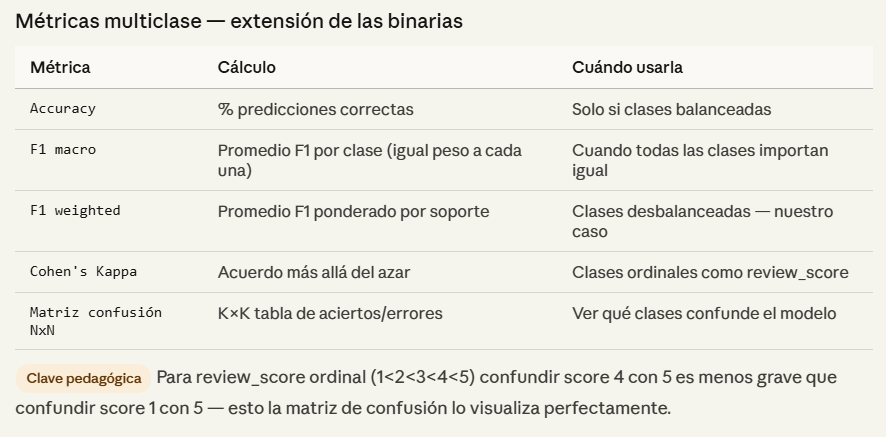

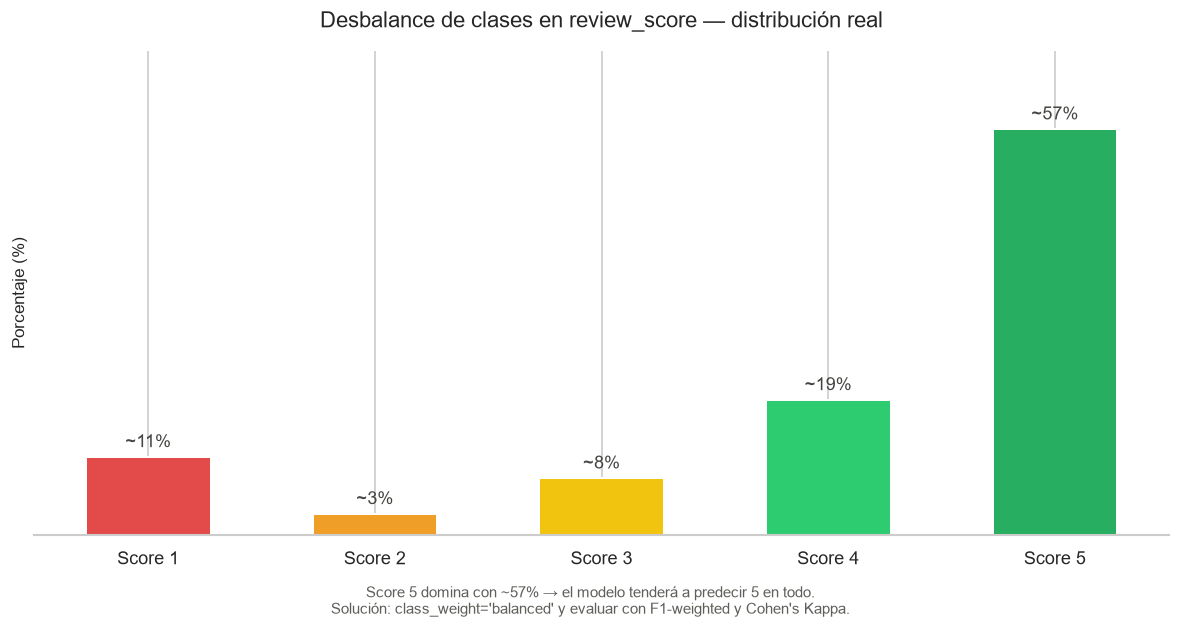

In [57]:
# ──────────────────────────────────────────────────────────────
# Distribución de clases review_score — matplotlib
# ──────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


# Distribución real del dataset Olist
scores      = ['Score 1', 'Score 2', 'Score 3', 'Score 4', 'Score 5']
porcentajes = [11, 3, 8, 19, 57]
colores     = ['#E24B4A', '#EF9F27', '#f1c40f', '#2ecc71', '#27ae60']

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(scores, porcentajes, color=colores,
              edgecolor='white', linewidth=1.2,
              width=0.55)

# Etiquetas encima de cada barra
for bar, pct in zip(bars, porcentajes):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.8,
            f'~{pct}%',
            ha='center', va='bottom',
            fontsize=11, color='#444441')

# Estética
ax.set_title('Desbalance de clases en review_score — distribución real',
             fontsize=13, pad=14)
ax.set_ylabel('Porcentaje (%)', fontsize=10)
ax.set_ylim(0, 68)
ax.set_yticks([])           # sin eje Y numérico — las etiquetas lo reemplazan
ax.spines[['top','right','left']].set_visible(False)
ax.tick_params(axis='x', labelsize=11)

# Nota al pie
fig.text(0.5, -0.04,
         "Score 5 domina con ~57% → el modelo tenderá a predecir 5 en todo.\n"
         "Solución: class_weight='balanced' y evaluar con F1-weighted y Cohen's Kappa.",
         ha='center', fontsize=9, color='#5F5E5A')

plt.tight_layout()
plt.savefig('distribucion_review_score.png', dpi=150,
            bbox_inches='tight')
plt.show()

Con la clasificación desvalanceada confirmada, pasamos a aplicar la regresión logística mutinomial

In [58]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO 4B — CLASIFICACIÓN MULTICLASE SUPERVISADA
# Target: review_score (clases 1, 2, 3, 4, 5)
# Modelos: Reg. Logística Multinomial · RF · XGBoost
# ═══════════════════════════════════════════════════════════════
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, cohen_kappa_score,
    f1_score, accuracy_score
)

print("""
╔══════════════════════════════════════════════════════════════╗
║    CLASIFICACIÓN MULTICLASE — review_score (1 a 5)          ║
║    Logística Multinomial · Random Forest · XGBoost          ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║    CLASIFICACIÓN MULTICLASE — review_score (1 a 5)          ║
║    Logística Multinomial · Random Forest · XGBoost          ║
╚══════════════════════════════════════════════════════════════╝



In [59]:
# ──────────────────────────────────────────────────────────────
# 1. PREPARACIÓN DEL DATASET
# ──────────────────────────────────────────────────────────────
features_multi = [
    'dias_retraso',
    'dias_entrega_real',
    'flete_total',
    'prop_flete',
    'n_items',
    'precio_total_items',
    'payment_value_total',
    'payment_installments',
    'product_weight_g',
    'mes_compra',
    'dia_semana',
    'hora_compra',
]

TARGET_M = 'review_score'

df_m = sabana[features_multi + [TARGET_M]].dropna()
df_m[TARGET_M] = df_m[TARGET_M].astype(int)

print(f"Registros disponibles: {len(df_m):,}")
print(f"\nDistribución de clases:")
dist_m = df_m[TARGET_M].value_counts().sort_index()
for score, n in dist_m.items():
    barra = '█' * int(n / dist_m.max() * 30)
    print(f"  Score {score}: {n:>6,} ({n/len(df_m)*100:>5.1f}%)  {barra}")

print(f"\nDesbalance máximo: {dist_m.max()/dist_m.min():.1f}x entre score 5 y score 2")
print("→ Usaremos class_weight='balanced' para compensar")

X_m = df_m[features_multi]
y_m = df_m[TARGET_M]

# XGBoost necesita clases desde 0 → remapeamos 1-5 a 0-4
le = LabelEncoder()
y_m_xgb = le.fit_transform(y_m)   # 1→0, 2→1, 3→2, 4→3, 5→4

Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(
    X_m, y_m, test_size=0.2, random_state=42, stratify=y_m
)
_, _, ym_tr_xgb, ym_te_xgb = train_test_split(
    X_m, y_m_xgb, test_size=0.2, random_state=42, stratify=y_m_xgb
)

print(f"\nTrain: {len(Xm_tr):,}  |  Test: {len(Xm_te):,}")

Registros disponibles: 95,813

Distribución de clases:
  Score 1:  9,352 (  9.8%)  ████
  Score 2:  2,920 (  3.0%)  █
  Score 3:  7,917 (  8.3%)  ████
  Score 4: 18,887 ( 19.7%)  █████████
  Score 5: 56,737 ( 59.2%)  ██████████████████████████████

Desbalance máximo: 19.4x entre score 5 y score 2
→ Usaremos class_weight='balanced' para compensar

Train: 76,650  |  Test: 19,163


In [60]:
# ──────────────────────────────────────────────────────────────
# MODELO 1 — REGRESIÓN LOGÍSTICA MULTINOMIAL (sklearn ≥ 1.5)
# ──────────────────────────────────────────────────────────────
import sklearn
print(f"sklearn version: {sklearn.__version__}")

print("=" * 55)
print("REGRESIÓN LOGÍSTICA MULTINOMIAL (Softmax)")
print("=" * 55)
print("""
En sklearn ≥ 1.5 el parámetro multi_class fue eliminado.
El solver 'lbfgs' usa Softmax automáticamente cuando
detecta más de 2 clases en y — no necesita declararse.
class_weight='balanced' sigue funcionando igual.
""")

pipe_lr_m = Pipeline([
    ('sc', StandardScaler()),
    ('m',  LogisticRegression(
               solver       = 'lbfgs',      # Softmax automático con multiclase
               class_weight = 'balanced',
               max_iter     = 2000,
               random_state = 42,
               C            = 1.0
           ))
])

pipe_lr_m.fit(Xm_tr, ym_tr)
pred_lr_m = pipe_lr_m.predict(Xm_te)
prob_lr_m = pipe_lr_m.predict_proba(Xm_te)

print("\nReporte de clasificación — Logística Multinomial:")
print(classification_report(ym_te, pred_lr_m,
      target_names=[f'Score {i}' for i in range(1, 6)]))
print(f"Accuracy    : {accuracy_score(ym_te, pred_lr_m):.4f}")
print(f"F1 weighted : {f1_score(ym_te, pred_lr_m, average='weighted'):.4f}")
print(f"Cohen Kappa : {cohen_kappa_score(ym_te, pred_lr_m):.4f}")

sklearn version: 1.9.1
REGRESIÓN LOGÍSTICA MULTINOMIAL (Softmax)

En sklearn ≥ 1.5 el parámetro multi_class fue eliminado.
El solver 'lbfgs' usa Softmax automáticamente cuando
detecta más de 2 clases en y — no necesita declararse.
class_weight='balanced' sigue funcionando igual.


Reporte de clasificación — Logística Multinomial:
              precision    recall  f1-score   support

     Score 1       0.32      0.50      0.39      1870
     Score 2       0.05      0.13      0.07       584
     Score 3       0.09      0.12      0.10      1583
     Score 4       0.23      0.15      0.18      3778
     Score 5       0.68      0.60      0.64     11348

    accuracy                           0.45     19163
   macro avg       0.27      0.30      0.27     19163
weighted avg       0.49      0.45      0.46     19163

Accuracy    : 0.4462
F1 weighted : 0.4606
Cohen Kappa : 0.1337


In [61]:
# ──────────────────────────────────────────────────────────────
# 3. MODELO 2 — RANDOM FOREST MULTICLASE
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("RANDOM FOREST — clasificación multiclase")
print("=" * 55)

rf_m = RandomForestClassifier(
    n_estimators    = 200,
    max_features    = 'sqrt',
    min_samples_leaf= 5,
    class_weight    = 'balanced',
    n_jobs          = -1,
    random_state    = 42,
    oob_score       = True
)
rf_m.fit(Xm_tr, ym_tr)
pred_rf_m = rf_m.predict(Xm_te)
prob_rf_m = rf_m.predict_proba(Xm_te)

print(f"OOB Accuracy: {rf_m.oob_score_:.4f}")
print("\nReporte de clasificación — Random Forest:")
print(classification_report(ym_te, pred_rf_m,
      target_names=[f'Score {i}' for i in range(1,6)]))
print(f"Accuracy    : {accuracy_score(ym_te, pred_rf_m):.4f}")
print(f"F1 weighted : {f1_score(ym_te, pred_rf_m, average='weighted'):.4f}")
print(f"Cohen Kappa : {cohen_kappa_score(ym_te, pred_rf_m):.4f}")

RANDOM FOREST — clasificación multiclase
OOB Accuracy: 0.4671

Reporte de clasificación — Random Forest:
              precision    recall  f1-score   support

     Score 1       0.36      0.52      0.43      1870
     Score 2       0.04      0.04      0.04       584
     Score 3       0.11      0.11      0.11      1583
     Score 4       0.22      0.24      0.23      3778
     Score 5       0.67      0.60      0.64     11348

    accuracy                           0.47     19163
   macro avg       0.28      0.30      0.29     19163
weighted avg       0.49      0.47      0.47     19163

Accuracy    : 0.4663
F1 weighted : 0.4747
Cohen Kappa : 0.1417


In [62]:
# ──────────────────────────────────────────────────────────────
# 4. MODELO 3 — XGBOOST MULTICLASE
# ──────────────────────────────────────────────────────────────
print("=" * 55)
print("XGBOOST — multi:softprob")
print("=" * 55)

Xm_tr2, Xm_val, ym_tr2_xgb, ym_val_xgb = train_test_split(
    Xm_tr, ym_tr_xgb, test_size=0.15, random_state=42
)

# Pesos manuales por clase para XGBoost
pesos_clase = len(ym_tr) / (5 * np.bincount(ym_tr_xgb))
sample_weights = np.array([pesos_clase[c] for c in ym_tr2_xgb])
sample_weights_val = np.array([pesos_clase[c] for c in ym_val_xgb])

xgb_m = XGBClassifier(
    n_estimators         = 500,
    learning_rate        = 0.05,
    max_depth            = 5,
    subsample            = 0.8,
    colsample_bytree     = 0.8,
    reg_lambda           = 1.0,
    reg_alpha            = 0.1,
    objective            = 'multi:softprob',
    num_class            = 5,
    eval_metric          = 'mlogloss',
    early_stopping_rounds= 30,
    random_state         = 42,
    n_jobs               = -1,
    verbosity            = 0
)

xgb_m.fit(
    Xm_tr2, ym_tr2_xgb,
    sample_weight     = sample_weights,
    eval_set          = [(Xm_val, ym_val_xgb)],
    sample_weight_eval_set = [sample_weights_val],
    verbose           = False
)

print(f"Árboles usados (early stopping): {xgb_m.best_iteration + 1}")

prob_xgb_m  = xgb_m.predict_proba(Xm_te)
pred_xgb_m  = le.inverse_transform(xgb_m.predict(Xm_te))

print("\nReporte de clasificación — XGBoost:")
print(classification_report(ym_te, pred_xgb_m,
      target_names=[f'Score {i}' for i in range(1,6)]))
print(f"Accuracy    : {accuracy_score(ym_te, pred_xgb_m):.4f}")
print(f"F1 weighted : {f1_score(ym_te, pred_xgb_m, average='weighted'):.4f}")
print(f"Cohen Kappa : {cohen_kappa_score(ym_te, pred_xgb_m):.4f}")

XGBOOST — multi:softprob
Árboles usados (early stopping): 120

Reporte de clasificación — XGBoost:
              precision    recall  f1-score   support

     Score 1       0.37      0.51      0.43      1870
     Score 2       0.06      0.09      0.07       584
     Score 3       0.12      0.18      0.14      1583
     Score 4       0.23      0.24      0.24      3778
     Score 5       0.69      0.56      0.62     11348

    accuracy                           0.45     19163
   macro avg       0.29      0.32      0.30     19163
weighted avg       0.50      0.45      0.47     19163

Accuracy    : 0.4485
F1 weighted : 0.4688
Cohen Kappa : 0.1466


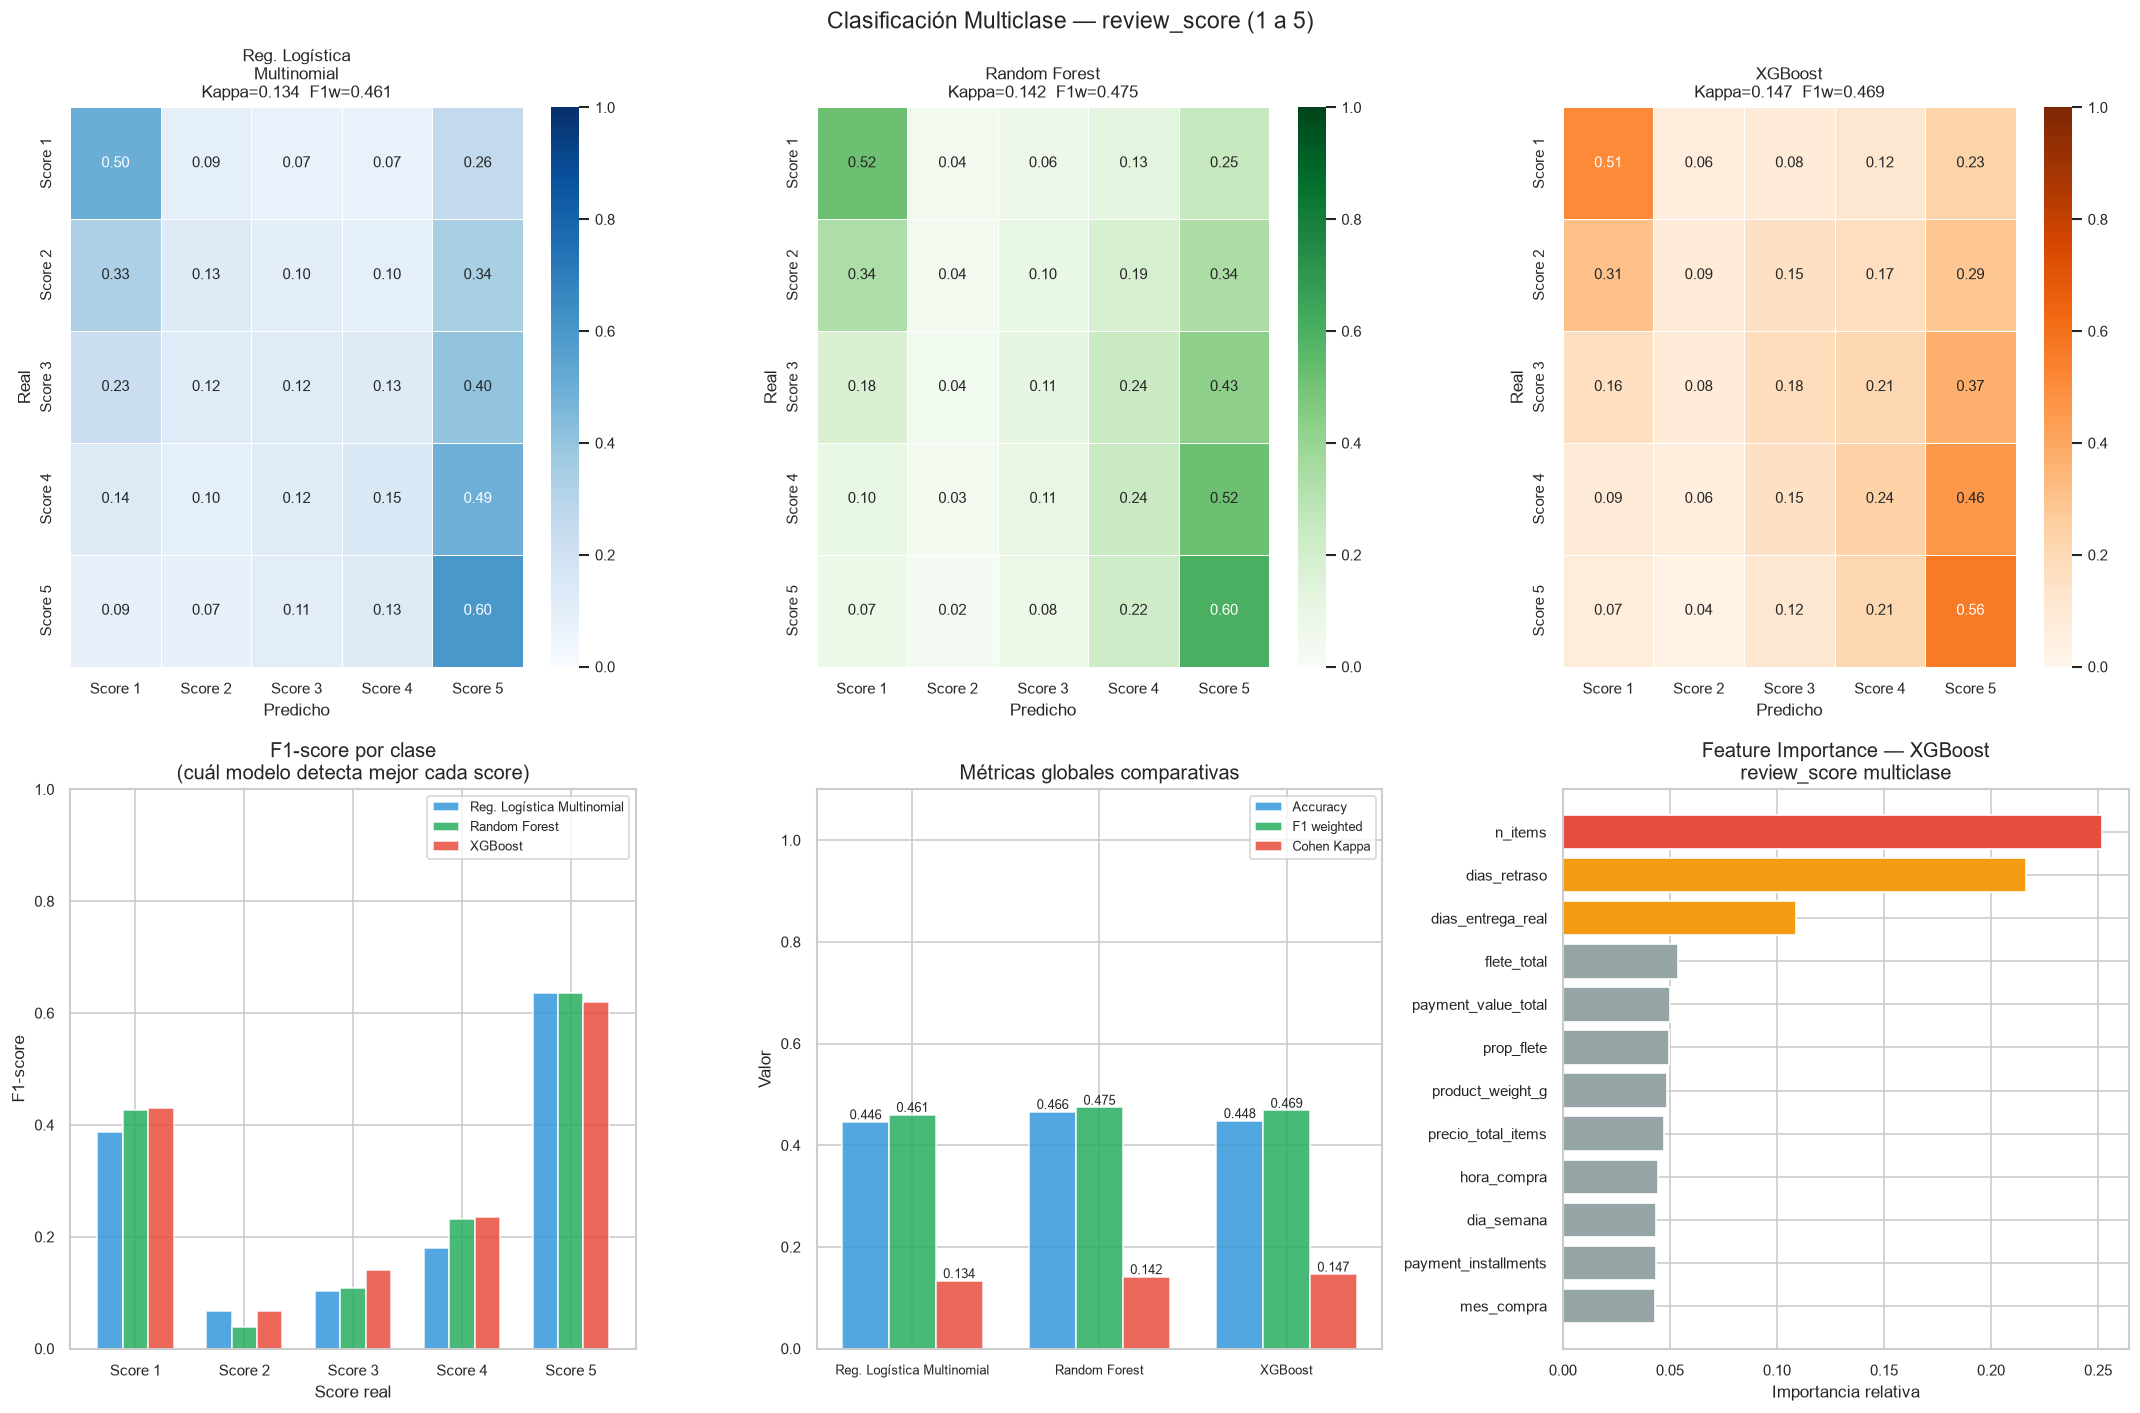

In [63]:
# ──────────────────────────────────────────────────────────────
# 5. VISUALIZACIONES COMPARATIVAS
# ──────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

clases_labels = ['Score 1','Score 2','Score 3','Score 4','Score 5']
cmaps = ['Blues', 'Greens', 'Oranges']

modelos_m = {
    'Reg. Logística\nMultinomial': pred_lr_m,
    'Random Forest'              : pred_rf_m,
    'XGBoost'                    : pred_xgb_m,
}

# Fila 1: Matrices de confusión (5×5)
for ax, (nombre, pred), cmap in zip(
        axes[0], modelos_m.items(), cmaps):
    cm = confusion_matrix(ym_te, pred, labels=[1,2,3,4,5])
    # Normalizar por filas para ver % de acierto por clase real
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt='.2f',
                cmap=cmap, ax=ax,
                xticklabels=clases_labels,
                yticklabels=clases_labels,
                vmin=0, vmax=1,
                linewidths=0.5,
                annot_kws={'size': 9})
    ax.set_xlabel('Predicho')
    ax.set_ylabel('Real')
    kappa = cohen_kappa_score(ym_te, pred)
    f1w   = f1_score(ym_te, pred, average='weighted')
    ax.set_title(f'{nombre}\nKappa={kappa:.3f}  F1w={f1w:.3f}',
                 fontsize=10)

# Fila 2 col 1: F1 por clase — comparativa
f1_por_clase = {}
for nombre, pred in modelos_m.items():
    f1s = f1_score(ym_te, pred, average=None,
                   labels=[1,2,3,4,5])
    f1_por_clase[nombre.replace('\n',' ')] = f1s

df_f1 = pd.DataFrame(f1_por_clase,
                     index=['Score 1','Score 2',
                            'Score 3','Score 4','Score 5'])
df_f1.plot(kind='bar', ax=axes[1,0],
           color=['#3498db','#27ae60','#e74c3c'],
           edgecolor='white', alpha=0.85, width=0.7)
axes[1,0].set_title('F1-score por clase\n(cuál modelo detecta mejor cada score)')
axes[1,0].set_xlabel('Score real')
axes[1,0].set_ylabel('F1-score')
axes[1,0].tick_params(axis='x', rotation=0)
axes[1,0].legend(fontsize=8)
axes[1,0].set_ylim(0, 1)

# Fila 2 col 2: Métricas globales comparativas
metricas_glob = {
    'Modelo'      : list(modelos_m.keys()),
    'Accuracy'    : [accuracy_score(ym_te, p)
                     for p in modelos_m.values()],
    'F1 weighted' : [f1_score(ym_te, p, average='weighted')
                     for p in modelos_m.values()],
    'Cohen Kappa' : [cohen_kappa_score(ym_te, p)
                     for p in modelos_m.values()],
}
df_glob = pd.DataFrame(metricas_glob).set_index('Modelo')
x_pos = np.arange(len(df_glob))
ancho = 0.25
for i, (col, color) in enumerate(zip(
        df_glob.columns, ['#3498db','#27ae60','#e74c3c'])):
    bars = axes[1,1].bar(x_pos + i*ancho,
                         df_glob[col], ancho,
                         color=color, label=col,
                         edgecolor='white', alpha=0.85)
    for bar in bars:
        axes[1,1].text(
            bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.005,
            f'{bar.get_height():.3f}',
            ha='center', fontsize=8)

axes[1,1].set_xticks(x_pos + ancho)
axes[1,1].set_xticklabels(
    [n.replace('\n',' ') for n in modelos_m.keys()],
    fontsize=8)
axes[1,1].set_title('Métricas globales comparativas')
axes[1,1].set_ylabel('Valor')
axes[1,1].set_ylim(0, 1.1)
axes[1,1].legend(fontsize=8)

# Fila 2 col 3: Feature importance XGBoost
imp_m = pd.Series(
    xgb_m.feature_importances_,
    index=features_multi
).sort_values()
colores_imp = ['#e74c3c' if v == imp_m.max()
               else '#f39c12' if v >= imp_m.quantile(0.75)
               else '#95a5a6' for v in imp_m]
axes[1,2].barh(imp_m.index, imp_m.values,
               color=colores_imp, edgecolor='white')
axes[1,2].set_title('Feature Importance — XGBoost\nreview_score multiclase')
axes[1,2].set_xlabel('Importancia relativa')

plt.suptitle(
    'Clasificación Multiclase — review_score (1 a 5)',
    fontsize=14)
plt.tight_layout()
plt.show()

In [64]:
# ──────────────────────────────────────────────────────────────
# 6. TABLA COMPARATIVA FINAL + CONCLUSIONES
# ──────────────────────────────────────────────────────────────
print("""
╔══════════════════════════════════════════════════════════════╗
║      TABLA COMPARATIVA — CLASIFICACIÓN MULTICLASE           ║
╚══════════════════════════════════════════════════════════════╝
""")

tabla_final = pd.DataFrame([
    {
        'Modelo'      : nombre.replace('\n',' '),
        'Accuracy'    : round(accuracy_score(ym_te, pred), 4),
        'F1 macro'    : round(f1_score(ym_te, pred, average='macro'), 4),
        'F1 weighted' : round(f1_score(ym_te, pred, average='weighted'), 4),
        'Cohen Kappa' : round(cohen_kappa_score(ym_te, pred), 4),
    }
    for nombre, pred in modelos_m.items()
])
print(tabla_final.to_string(index=False))

print(f"""
─────────────────────────────────────────────────────────────
CONCLUSIONES — CLASIFICACIÓN MULTICLASE:

1. La matriz de confusión 5×5 es la visualización más rica:
   → La diagonal principal muestra los aciertos por clase
   → Los errores "cercanos" (score 4 → predice 5) son menos
     graves que los errores "lejanos" (score 1 → predice 5)
   → Un buen modelo concentra los errores en la diagonal

2. Score 2 y Score 3 son los más difíciles de clasificar:
   → Son clases minoritarias + son "ambiguas" semánticamente
   → El modelo tiende a confundirlas con score 1 o score 4

3. Cohen's Kappa es la métrica más honesta aquí:
   → Descuenta el acuerdo esperado por azar
   → Un modelo que siempre predice Score 5 tiene
     Kappa ≈ 0 aunque tenga Accuracy del 57%

4. dias_retraso domina el feature importance en los 3 modelos:
   → Confirma lo visto en el EDA: el retraso es el principal
     driver de insatisfacción del cliente en Olist

PRÓXIMO PASO → Aprendizaje No Supervisado:
  K-Means para segmentar clientes y sellers sin etiquetas
─────────────────────────────────────────────────────────────
""")


╔══════════════════════════════════════════════════════════════╗
║      TABLA COMPARATIVA — CLASIFICACIÓN MULTICLASE           ║
╚══════════════════════════════════════════════════════════════╝

                    Modelo  Accuracy  F1 macro  F1 weighted  Cohen Kappa
Reg. Logística Multinomial    0.4462    0.2750       0.4606       0.1337
             Random Forest    0.4663    0.2889       0.4747       0.1417
                   XGBoost    0.4485    0.2984       0.4688       0.1466

─────────────────────────────────────────────────────────────
CONCLUSIONES — CLASIFICACIÓN MULTICLASE:

1. La matriz de confusión 5×5 es la visualización más rica:
   → La diagonal principal muestra los aciertos por clase
   → Los errores "cercanos" (score 4 → predice 5) son menos
     graves que los errores "lejanos" (score 1 → predice 5)
   → Un buen modelo concentra los errores en la diagonal

2. Score 2 y Score 3 son los más difíciles de clasificar:
   → Son clases minoritarias + son "ambiguas" semánti

## Visualización de predicciones. 

Vamos a hacer una pequeña gráfica, similar a la de dispersión para verificar la evaluación de las predicciones contra las observaciones. Conocido como scatter plot con jitter



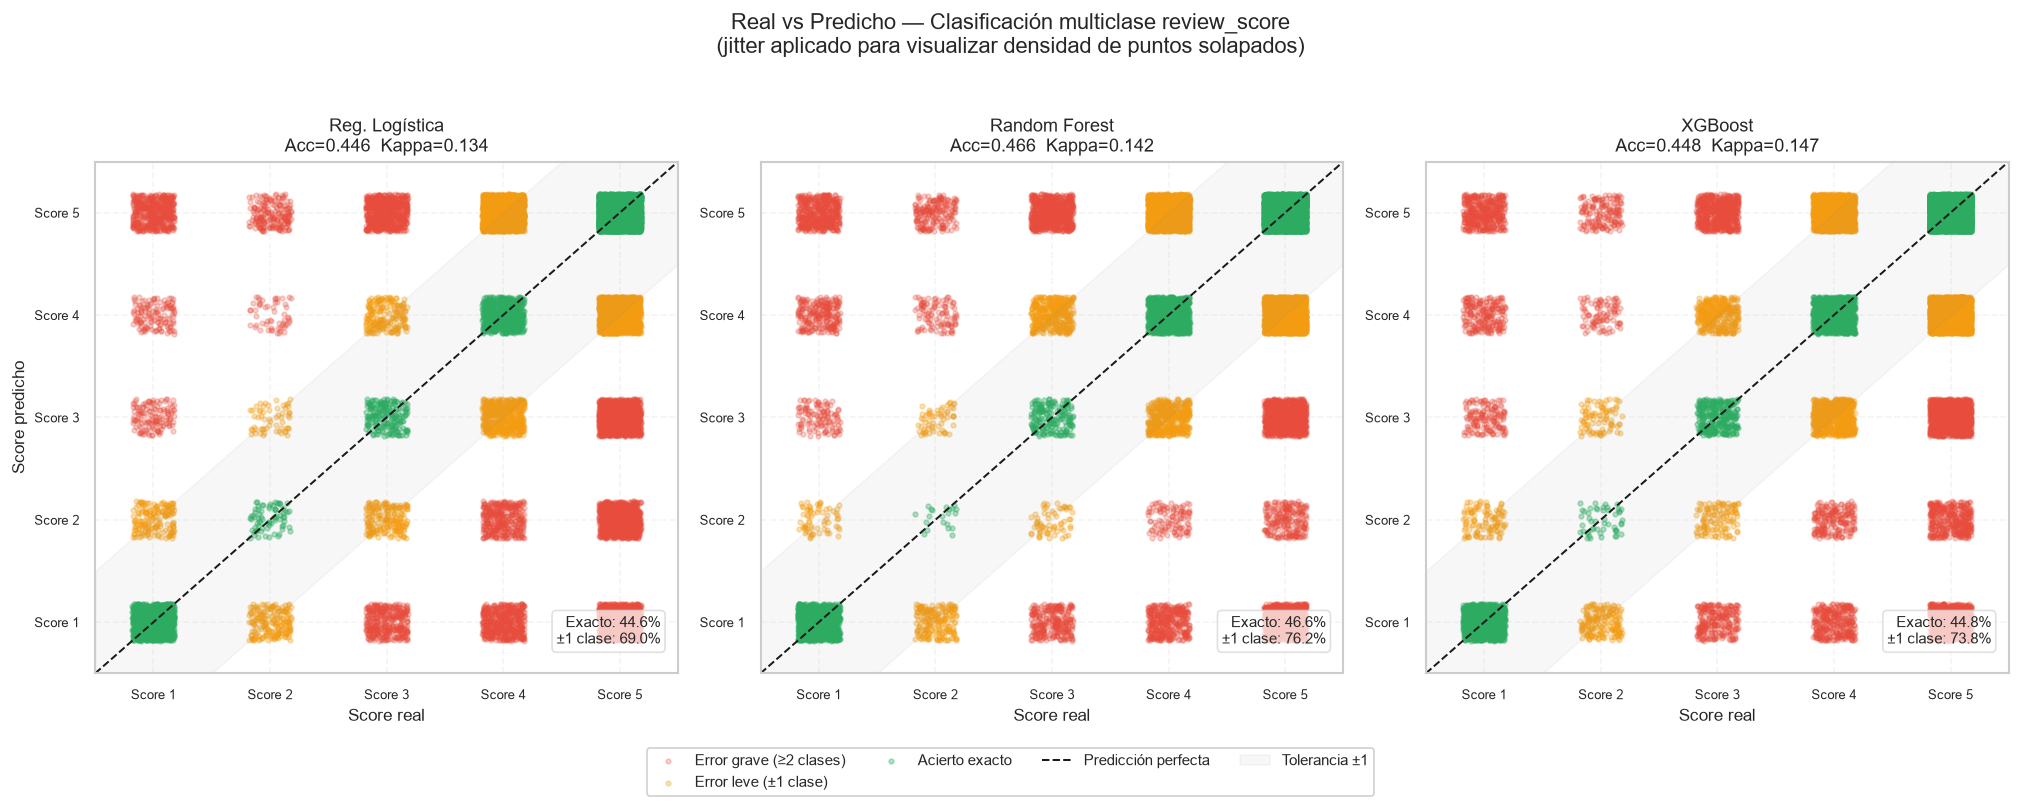

In [65]:
# ──────────────────────────────────────────────────────────────
# DISPERSIÓN: valores reales vs predichos — clasificación multiclase
# ──────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker


# DataFrame con reales y predichos de los 3 modelos
df_pred = pd.DataFrame({
    'real'          : ym_te.values,
    'Reg. Logística': pred_lr_m,
    'Random Forest' : pred_rf_m,
    'XGBoost'       : pred_xgb_m,
})

modelos_plot = ['Reg. Logística', 'Random Forest', 'XGBoost']
colores_mod  = ['#3498db', '#27ae60', '#e74c3c']

fig, axes = plt.subplots(1, 3, figsize=(17, 6))

np.random.seed(42)

for ax, modelo, color in zip(axes, modelos_plot, colores_mod):

    real  = df_pred['real'].values
    pred  = df_pred[modelo].values

    # Jitter suave para separar puntos solapados
    jitter_x = np.random.uniform(-0.18, 0.18, len(real))
    jitter_y = np.random.uniform(-0.18, 0.18, len(pred))

    # Color por acierto / error
    acierto = (real == pred)
    cerca   = (np.abs(real - pred) == 1)   # error de ±1 clase
    lejos   = (np.abs(real - pred) > 1)    # error grave

    # Capas: primero los errores graves, encima los cercanos, encima los aciertos
    ax.scatter(real[lejos]  + jitter_x[lejos],
               pred[lejos]  + jitter_y[lejos],
               s=8, alpha=0.25, color='#e74c3c', label='Error grave (≥2 clases)')
    ax.scatter(real[cerca]  + jitter_x[cerca],
               pred[cerca]  + jitter_y[cerca],
               s=8, alpha=0.30, color='#f39c12', label='Error leve (±1 clase)')
    ax.scatter(real[acierto] + jitter_x[acierto],
               pred[acierto] + jitter_y[acierto],
               s=8, alpha=0.35, color='#27ae60', label='Acierto exacto')

    # Línea diagonal perfecta
    ax.plot([0.5, 5.5], [0.5, 5.5], 'k--', lw=1.2,
            label='Predicción perfecta')

    # Bandas de tolerancia ±1
    ax.fill_between([0.5, 5.5], [0.5-1, 5.5-1], [0.5+1, 5.5+1],
                    alpha=0.06, color='gray', label='Tolerancia ±1')

    # Ejes y grilla
    ax.set_xlim(0.5, 5.5)
    ax.set_ylim(0.5, 5.5)
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_xticklabels([f'Score {i}' for i in range(1,6)], fontsize=8)
    ax.set_yticklabels([f'Score {i}' for i in range(1,6)], fontsize=8)
    ax.grid(True, alpha=0.2, linestyle='--')

    # Métricas en el título
    from sklearn.metrics import cohen_kappa_score, accuracy_score
    acc   = accuracy_score(real, pred)
    kappa = cohen_kappa_score(real, pred)
    pct_exacto = acierto.mean() * 100
    pct_cerca  = (acierto | cerca).mean() * 100

    ax.set_title(f'{modelo}\nAcc={acc:.3f}  Kappa={kappa:.3f}', fontsize=11)
    ax.set_xlabel('Score real', fontsize=10)
    if ax == axes[0]:
        ax.set_ylabel('Score predicho', fontsize=10)

    # Anotación dentro del gráfico
    ax.text(0.97, 0.05,
            f'Exacto: {pct_exacto:.1f}%\n±1 clase: {pct_cerca:.1f}%',
            transform=ax.transAxes,
            ha='right', va='bottom', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.3',
                      facecolor='white', alpha=0.7,
                      edgecolor='lightgray'))

# Leyenda unificada fuera de los subplots
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels,
           loc='lower center', ncol=4,
           fontsize=9, framealpha=0.9,
           bbox_to_anchor=(0.5, -0.08))

plt.suptitle(
    'Real vs Predicho — Clasificación multiclase review_score\n'
    '(jitter aplicado para visualizar densidad de puntos solapados)',
    fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig('scatter_multiclase_review.png', dpi=150, bbox_inches='tight')
plt.show()

#  Churn — Predicción de Abandono de Clientes

## ¿Qué es el Churn?

El **churn** (del inglés *customer churn* o *attrition*) es la tasa a la que 
los clientes dejan de hacer negocios con una empresa en un período de tiempo 
determinado. En términos de aprendizaje supervisado, el churn es un problema 
de **clasificación binaria**: para cada cliente, el modelo debe predecir si 
abandonará (1) o se quedará (0).

A diferencia de los modelos de regresión que trabajamos anteriormente — donde 
la variable objetivo era continua como `payment_value_total` — aquí la 
pregunta es discreta: **¿este cliente volverá a comprar o no?**

---

## ¿En qué industrias se aplica?

El churn es uno de los problemas de negocio más universales de la analítica 
de datos. Se aplica en prácticamente cualquier industria donde existe una 
relación continua con el cliente:

| Industria | Definición de Churn | Señal típica |
|---|---|---|
| **Telecomunicaciones** | Cliente que cancela su línea o contrato | Portabilidad numérica, baja voluntaria |
| **Banca y fintech** | Cliente que cierra su cuenta o deja de operar | Saldo en cero, sin transacciones en 90 días |
| **Streaming (Netflix, Spotify)** | Suscriptor que cancela su plan | No renovación del período mensual |
| **SaaS / Software** | Usuario que no renueva su licencia | Expiración sin renovación |
| **Retail y e-commerce** | Cliente que no vuelve a comprar | Inactividad prolongada desde la última compra |
| **Seguros** | Asegurado que no renueva su póliza | No pago de prima en fecha de vencimiento |

En telecomunicaciones y banca el churn está explícitamente registrado en los 
sistemas — hay una fecha exacta de cancelación. En **e-commerce**, como es el 
caso de Olist, el churn **no existe como variable directa** en los datos: 
debe construirse con criterio de negocio a partir del comportamiento 
transaccional del cliente.

---

## ¿Por qué es crítico para Olist?

El dataset de Olist registra 99,441 pedidos de 92,752 clientes únicos del 
marketplace brasileño. Al analizar la frecuencia de compra descubrimos un 
patrón preocupante: **la gran mayoría de los clientes realizó únicamente un 
pedido en toda su historia con la plataforma**.

Esto tiene tres implicaciones directas para el negocio:

**1. Costo de adquisición vs. valor de vida del cliente (LTV)**  
Adquirir un nuevo cliente en e-commerce es entre 5 y 7 veces más caro que 
retener uno existente. Si la mayor parte de los clientes de Olist solo compra 
una vez, el costo de adquisición nunca se amortiza completamente.

**2. Conexión con los segmentos descubiertos por K-Means**  
En el módulo anterior identificamos que los clusters **C3** (insatisfecho por 
producto) y **C4** (insatisfecho por logística) concentran el 21.4% de los 
clientes con review_medio de 2.1 y 2.2 respectivamente. La hipótesis analítica 
es que estos segmentos tienen una probabilidad de churn sistemáticamente mayor 
— el modelo lo confirmará o refutará con datos.

**3. Anticipación y acción**  
Un modelo de churn convierte la reacción en predicción: en lugar de detectar 
que un cliente abandonó, la organización puede identificar **quién está en 
riesgo antes de que se vaya** y ejecutar acciones de retención dirigidas — 
descuentos personalizados, mejoras en el seguimiento del pedido, o campañas 
de reactivación — precisamente en los segmentos más vulnerables.

---

## Construcción de la variable Churn en Olist

Dado que Olist no registra explícitamente el abandono, aplicamos el siguiente 
criterio de negocio para construir la etiqueta:

Churn = 1  si:  dias desde último pedido > 180 días
               (independientemente del número de pedidos)

Churn = 0  si:  dias desde último pedido <= 180 días
               (cliente activo en los últimos 6 meses)

Nota: n_pedidos entra como FEATURE del modelo, no como
criterio de la etiqueta. Un cliente recurrente inactivo
tiene menor probabilidad de churn que uno de un solo
pedido con la misma inactividad — el modelo aprende esa
diferencia solo a partir de los datos.

Esta definición captura el concepto central del churn en e-commerce: un 
cliente que tuvo una única experiencia con la plataforma y no volvió en seis 
meses es, con alta probabilidad, un cliente perdido. El umbral de 180 días es 
una decisión analítica — en un proyecto real se calibraría con el equipo de 
negocio según el ciclo de compra típico de la categoría de producto.

---

## Modelo seleccionado: Regresión Logística

Para este módulo aplicaremos **Regresión Logística** como modelo principal, 
por tres razones alineadas con el enfoque del curso:

**Interpretabilidad directa**  
Los coeficientes de la Regresión Logística indican explícitamente la dirección 
e intensidad del efecto de cada variable sobre la probabilidad de churn. Un 
coeficiente positivo en `dias_inactivo` confirma que a mayor tiempo sin 
comprar, mayor la probabilidad de abandono — un resultado que la gerencia de 
Olist puede comunicar sin necesidad de abrir la "caja negra" de un ensemble.

**Baseline sólido para comparación**  
En el flujo del curso ya vimos que la Regresión Logística funciona como punto 
de referencia obligatorio antes de modelos más complejos como Random Forest o 
XGBoost. Si un modelo más sofisticado no supera significativamente a la 
Logística, la organización debería preferir la simplicidad y la 
interpretabilidad.

**Probabilidades calibradas**  
A diferencia de un árbol de decisión que asigna clases directamente, la 
Regresión Logística produce probabilidades de abandono continuas en [0, 1] 
mediante la función sigmoide:

$$P(\text{churn} = 1 \mid x) = \sigma(\hat{z}) = \frac{1}{1 + e^{-\hat{z}}}$$

$$\hat{z} = \beta_0 + \beta_1 \cdot \text{dias\_inactivo} + \beta_2 \cdot \text{review\_medio} + \ldots + \beta_p \cdot x_p$$

Estas probabilidades permiten **segmentar a los clientes en niveles de riesgo** 
— crítico, alto, medio, bajo — lo que es más útil para la gerencia que una 
clasificación binaria pura.

**Nota sobre el desbalance**  
Al igual que en los modelos de `entrega_a_tiempo` y `resena_positiva` del 
módulo anterior, el churn en Olist presenta desbalance de clases. Aplicaremos 
`class_weight='balanced'` para que el modelo no ignore la clase minoritaria, 
y evaluaremos con **AUC-PR** como métrica principal — exactamente por las 
mismas razones que discutimos en el módulo de clasificación binaria.

---

In [66]:
# ═══════════════════════════════════════════════════════════════
# MÓDULO CHURN — PREDICCIÓN DE ABANDONO DE CLIENTES
# Dataset: Olist Brazilian E-Commerce
# Integrado al pipeline del curso (requiere 'sabana' en memoria)
# ═══════════════════════════════════════════════════════════════


print("""
╔══════════════════════════════════════════════════════════════╗
║   MÓDULO CHURN — PREDICCIÓN DE ABANDONO                     ║
║   Olist E-Commerce Brasil                                   ║
╚══════════════════════════════════════════════════════════════╝
""")

# ── 1. DEFINIR CHURN A PARTIR DE OLIST ────────────────────────
# Olist no tiene una columna 'churn' — la construimos con
# criterio de negocio:
#
# Un cliente tiene CHURN = 1 si:
#   
#   · Su último pedido fue hace más de 6 meses del cierre
#     del dataset (2018-10-17)
#
# Un cliente tiene CHURN = 0 si:
#   
#   · Su último pedido  fue reciente (< 6 meses)
# ──────────────────────────────────────────────────────────────

print("=" * 55)
print("1. CONSTRUCCIÓN DE LA VARIABLE CHURN")
print("=" * 55)

# Fecha de cierre del dataset
FECHA_CORTE = pd.Timestamp('2018-10-17')
VENTANA_CHURN_DIAS = 180  # 6 meses

# Convertir fechas
sabana['order_purchase_timestamp'] = pd.to_datetime(
    sabana['order_purchase_timestamp'])

# Agregación a nivel de cliente único
df_churn = (sabana
    .groupby('customer_unique_id')
    .agg(
        n_pedidos         = ('order_id',                    'count'),
        fecha_ultimo_pedido = ('order_purchase_timestamp',  'max'),
        gasto_total       = ('payment_value_total',         'sum'),
        ticket_medio      = ('payment_value_total',         'mean'),
        review_medio      = ('review_score',                'mean'),
        pct_entrega_tiempo= ('entrega_a_tiempo',            'mean'),
        dias_entrega_medio= ('dias_entrega_real',           'mean'),
        flete_medio       = ('flete_total',                 'mean'),
        n_categorias      = ('product_category_name',       'nunique'),
        pct_resena_pos    = ('resena_positiva',             'mean'),
        cuotas_media      = ('payment_installments',        'mean'),
    )
    .reset_index()
)

# Días desde el último pedido hasta el cierre del dataset
df_churn['dias_inactivo'] = (
    FECHA_CORTE - df_churn['fecha_ultimo_pedido']
).dt.days

# Definición de Churn
df_churn['churn'] = (
    df_churn['dias_inactivo'] > VENTANA_CHURN_DIAS
).astype(int)

# Resumen
n_total  = len(df_churn)
n_churn  = df_churn['churn'].sum()
n_retain = n_total - n_churn
pct_ch   = n_churn / n_total * 100

print(f"Clientes únicos analizados: {n_total:,}")
print(f"  Churn  (1) — abandono   : {n_churn:,}  ({pct_ch:.1f}%)")
print(f"  Retención (0) — activos : {n_retain:,}  ({100-pct_ch:.1f}%)")
print(f"\nDefinición aplicada:")
print(f"  · 1 solo pedido en toda la historia")
print(f"  · Y último pedido hace >{VENTANA_CHURN_DIAS} días del cierre")
print(f"  → Ratio desbalance: {n_retain/n_churn:.1f}:1")


╔══════════════════════════════════════════════════════════════╗
║   MÓDULO CHURN — PREDICCIÓN DE ABANDONO                     ║
║   Olist E-Commerce Brasil                                   ║
╚══════════════════════════════════════════════════════════════╝

1. CONSTRUCCIÓN DE LA VARIABLE CHURN
Clientes únicos analizados: 96,096
  Churn  (1) — abandono   : 67,922  (70.7%)
  Retención (0) — activos : 28,174  (29.3%)

Definición aplicada:
  · 1 solo pedido en toda la historia
  · Y último pedido hace >180 días del cierre
  → Ratio desbalance: 0.4:1


In [67]:
# ── 2. FEATURES Y SPLIT ───────────────────────────────────────
# Ingresamos los hiperparámetros del modelo, conformeel concepto ya realizado
print("\n" + "=" * 55)
print("2. FEATURES Y PREPARACIÓN")
print("=" * 55)
#Variables independientes o predicotras del target. 
features_churn = [
    'n_pedidos',
    'gasto_total',
    'ticket_medio',
    'review_medio',
    'pct_entrega_tiempo',
    'dias_entrega_medio',
    'flete_medio',
    'n_categorias',
    'pct_resena_pos',
    'cuotas_media',
    'dias_inactivo',
]

df_modelo = df_churn[features_churn + ['churn']].dropna()

X = df_modelo[features_churn]
y = df_modelo['churn']

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {len(X_tr):,}  |  Test: {len(X_te):,}")
print(f"Churn en train: {y_tr.mean()*100:.1f}%")
print(f"Churn en test : {y_te.mean()*100:.1f}%")
print(f"\nFeatures usadas ({len(features_churn)}):")
for f in features_churn:
    print(f"  · {f}")

# Escalar para Logística
sc = StandardScaler()
X_tr_sc = sc.fit_transform(X_tr)
X_te_sc  = sc.transform(X_te)

spw = (y_tr == 0).sum() / (y_tr == 1).sum()
print(f"\nscale_pos_weight XGBoost: {spw:.2f}")


2. FEATURES Y PREPARACIÓN
Train: 74,201  |  Test: 18,551
Churn en train: 70.3%
Churn en test : 70.3%

Features usadas (11):
  · n_pedidos
  · gasto_total
  · ticket_medio
  · review_medio
  · pct_entrega_tiempo
  · dias_entrega_medio
  · flete_medio
  · n_categorias
  · pct_resena_pos
  · cuotas_media
  · dias_inactivo

scale_pos_weight XGBoost: 0.42


In [68]:
# ── 3. ENTRENAR MODELOS ───────────────────────────────────────
#Entrenamos el modelo con un 80% de los datos. 
print("\n" + "=" * 55)
print("3. ENTRENAMIENTO — 3 ALGORITMOS")
print("=" * 55)

# Regresión Logística
lr_ch = LogisticRegression(
    class_weight='balanced', max_iter=1000,
    random_state=42, solver='lbfgs')
lr_ch.fit(X_tr_sc, y_tr)

# Random Forest
rf_ch = RandomForestClassifier(
    n_estimators=200, class_weight='balanced',
    random_state=42, n_jobs=-1, oob_score=True)
rf_ch.fit(X_tr, y_tr)

# XGBoost
xgb_ch = xgb.XGBClassifier(
    n_estimators=300, learning_rate=0.05,
    max_depth=5, subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=spw,
    eval_metric='logloss',
    random_state=42, n_jobs=-1, verbosity=0)
xgb_ch.fit(X_tr, y_tr,
           eval_set=[(X_te, y_te)],
           verbose=False)

print("✓ Regresión Logística entrenada")
print(f"✓ Random Forest entrenado  (OOB Accuracy: {rf_ch.oob_score_:.4f})")
print("✓ XGBoost entrenado")


3. ENTRENAMIENTO — 3 ALGORITMOS
✓ Regresión Logística entrenada
✓ Random Forest entrenado  (OOB Accuracy: 1.0000)
✓ XGBoost entrenado


In [69]:
# ── 4. EVALUACIÓN COMPLETA ────────────────────────────────────
# Confirmación de resultados 
print("\n" + "=" * 55)
print("4. EVALUACIÓN DE MODELOS")
print("=" * 55)

def evaluar_churn(nombre, modelo, X_test, y_test, escalado=False):
    Xq = X_te_sc if escalado else X_test
    pred  = modelo.predict(Xq)
    proba = modelo.predict_proba(Xq)[:, 1]
    auc_roc = roc_auc_score(y_test, proba)
    auc_pr  = average_precision_score(y_test, proba)
    f1_ch   = f1_score(y_test, pred, pos_label=1)
    f1_ret  = f1_score(y_test, pred, pos_label=0)
    print(f"\n--- {nombre} ---")
    print(classification_report(
        y_test, pred,
        target_names=['Retención (0)', 'Churn (1)']))
    print(f"  AUC-ROC : {auc_roc:.4f}")
    print(f"  AUC-PR  : {auc_pr:.4f}  ← métrica clave con desbalance")
    return {
        'Modelo'     : nombre,
        'F1_churn'   : round(f1_ch,  4),
        'F1_retencion': round(f1_ret, 4),
        'AUC_ROC'    : round(auc_roc, 4),
        'AUC_PR'     : round(auc_pr,  4),
        'pred'        : pred,
        'proba'       : proba,
    }

r_lr  = evaluar_churn('Reg. Logística', lr_ch,  X_te, y_te, escalado=True)
r_rf  = evaluar_churn('Random Forest',  rf_ch,  X_te, y_te)
r_xgb = evaluar_churn('XGBoost',        xgb_ch, X_te, y_te)


4. EVALUACIÓN DE MODELOS

--- Reg. Logística ---
               precision    recall  f1-score   support

Retención (0)       0.97      1.00      0.99      5510
    Churn (1)       1.00      0.99      0.99     13041

     accuracy                           0.99     18551
    macro avg       0.99      0.99      0.99     18551
 weighted avg       0.99      0.99      0.99     18551

  AUC-ROC : 1.0000
  AUC-PR  : 1.0000  ← métrica clave con desbalance

--- Random Forest ---
               precision    recall  f1-score   support

Retención (0)       1.00      1.00      1.00      5510
    Churn (1)       1.00      1.00      1.00     13041

     accuracy                           1.00     18551
    macro avg       1.00      1.00      1.00     18551
 weighted avg       1.00      1.00      1.00     18551

  AUC-ROC : 1.0000
  AUC-PR  : 1.0000  ← métrica clave con desbalance

--- XGBoost ---
               precision    recall  f1-score   support

Retención (0)       0.99      1.00      1.00    

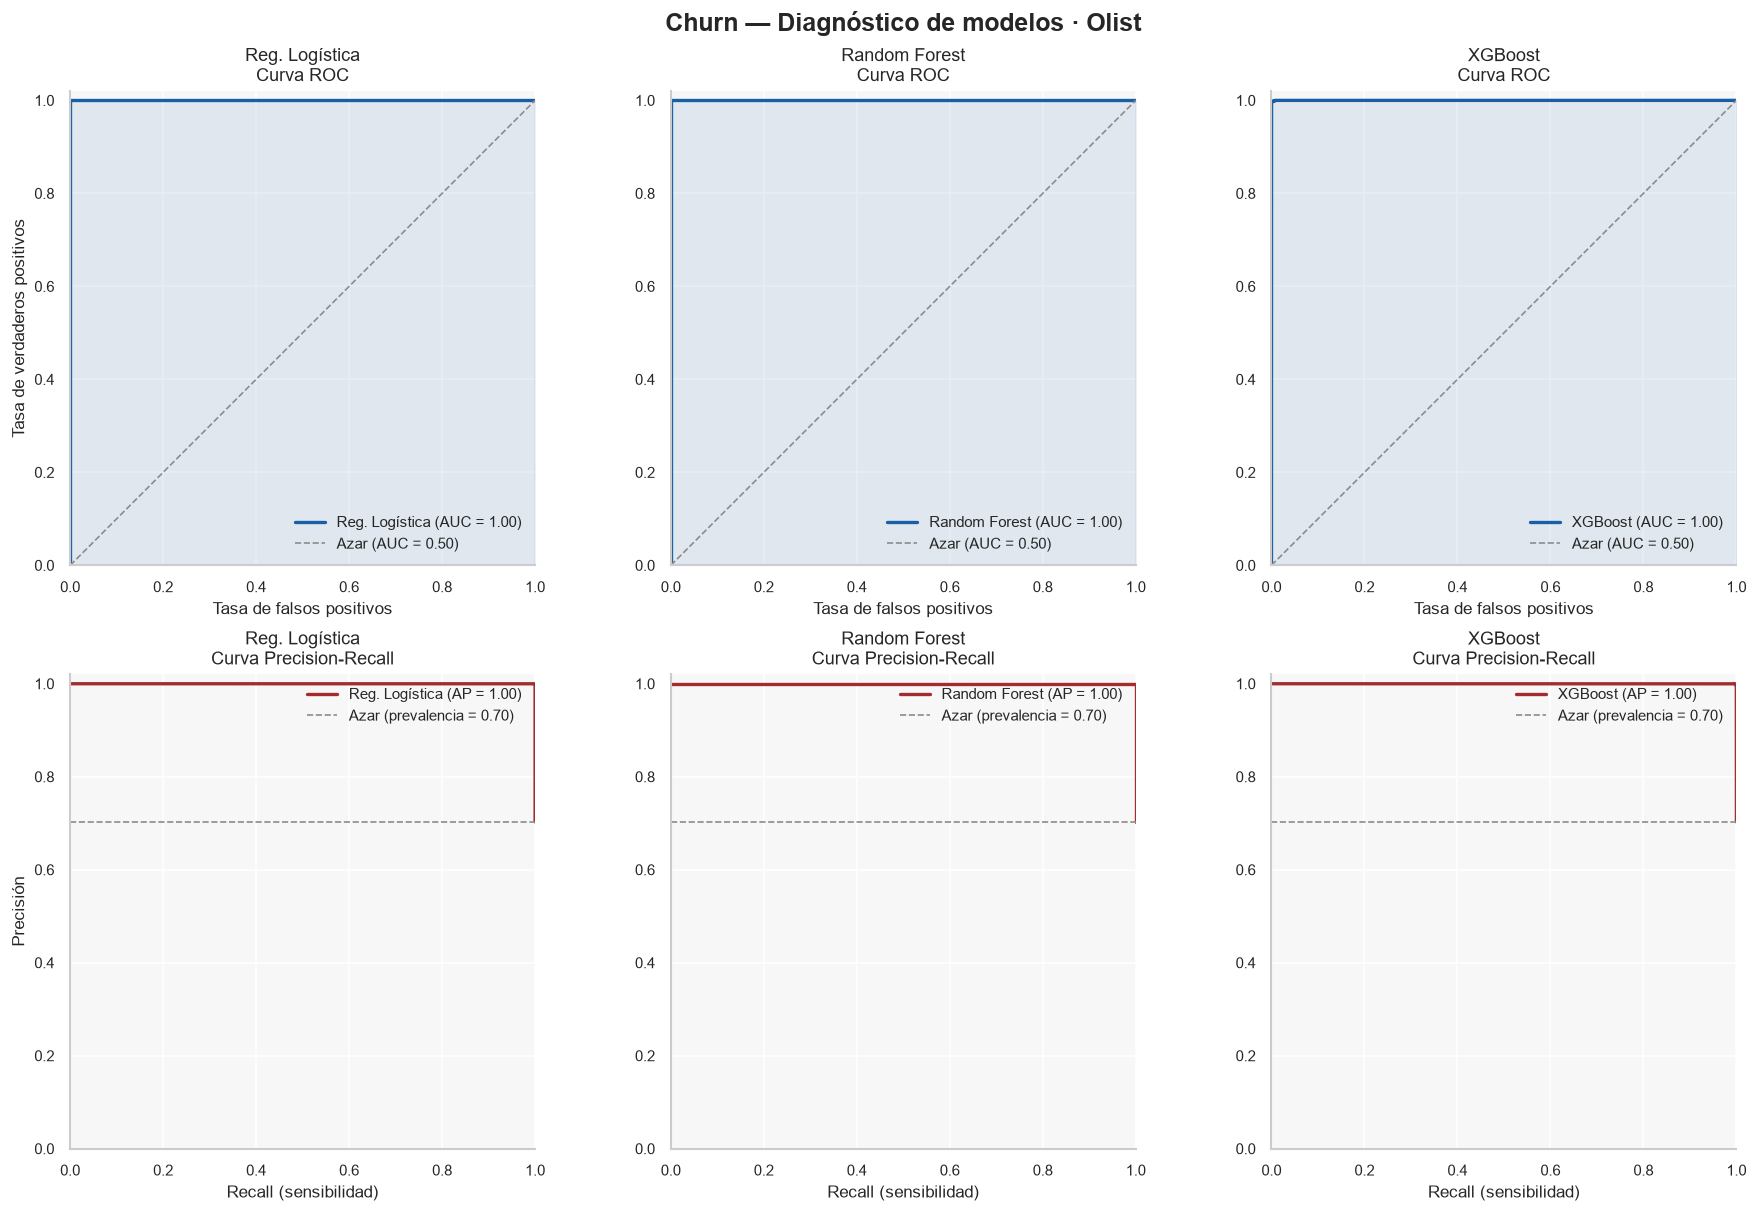

In [75]:
# ── 6. GRÁFICAS DIAGNÓSTICO ───────────────────────────────────
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

AZUL, ROJO, GRIS = '#185FA5', '#A32D2D', '#8C8C8C'
prevalencia = y_te.mean()

def estilizar(ax):
    ax.set_facecolor('#F7F7F7')
    ax.grid(True, color='white', lw=1)
    ax.set_axisbelow(True)
    for lado in ['top', 'right']:
        ax.spines[lado].set_visible(False)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)

fig, axes = plt.subplots(2, 3, figsize=(15, 10), constrained_layout=True)
fig.suptitle('Churn — Diagnóstico de modelos · Olist',
             fontsize=15, fontweight='bold')

modelos_plot = [
    ('Reg. Logística', r_lr,  X_te_sc),
    ('Random Forest',  r_rf,  X_te),
    ('XGBoost',        r_xgb, X_te),
]

for col, (nombre, r, Xq) in enumerate(modelos_plot):

    # ── Curva ROC ──
    ax = axes[0, col]
    roc = RocCurveDisplay.from_predictions(y_te, r['proba'], name=nombre, ax=ax)
    roc.line_.set_color(AZUL)
    roc.line_.set_linewidth(2)
    ax.fill_between(roc.fpr, roc.tpr, color=AZUL, alpha=0.10)
    ax.plot([0, 1], [0, 1], ls='--', color=GRIS, lw=1, label='Azar (AUC = 0.50)')
    estilizar(ax)
    ax.set_title(f'{nombre}\nCurva ROC', fontsize=11)
    ax.set_xlabel('Tasa de falsos positivos')
    ax.set_ylabel('Tasa de verdaderos positivos' if col == 0 else '')
    ax.legend(loc='lower right', fontsize=9, frameon=False)

    # ── Curva Precision-Recall ──
    ax = axes[1, col]
    pr = PrecisionRecallDisplay.from_predictions(y_te, r['proba'], name=nombre, ax=ax)
    pr.line_.set_color(ROJO)
    pr.line_.set_linewidth(2)
    ax.axhline(prevalencia, ls='--', color=GRIS, lw=1,
               label=f'Azar (prevalencia = {prevalencia:.2f})')
    estilizar(ax)
    ax.set_title(f'{nombre}\nCurva Precision-Recall', fontsize=11)
    ax.set_xlabel('Recall (sensibilidad)')
    ax.set_ylabel('Precisión' if col == 0 else '')
    ax.legend(loc='upper right', fontsize=9, frameon=False)

plt.savefig('churn_curvas_roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()

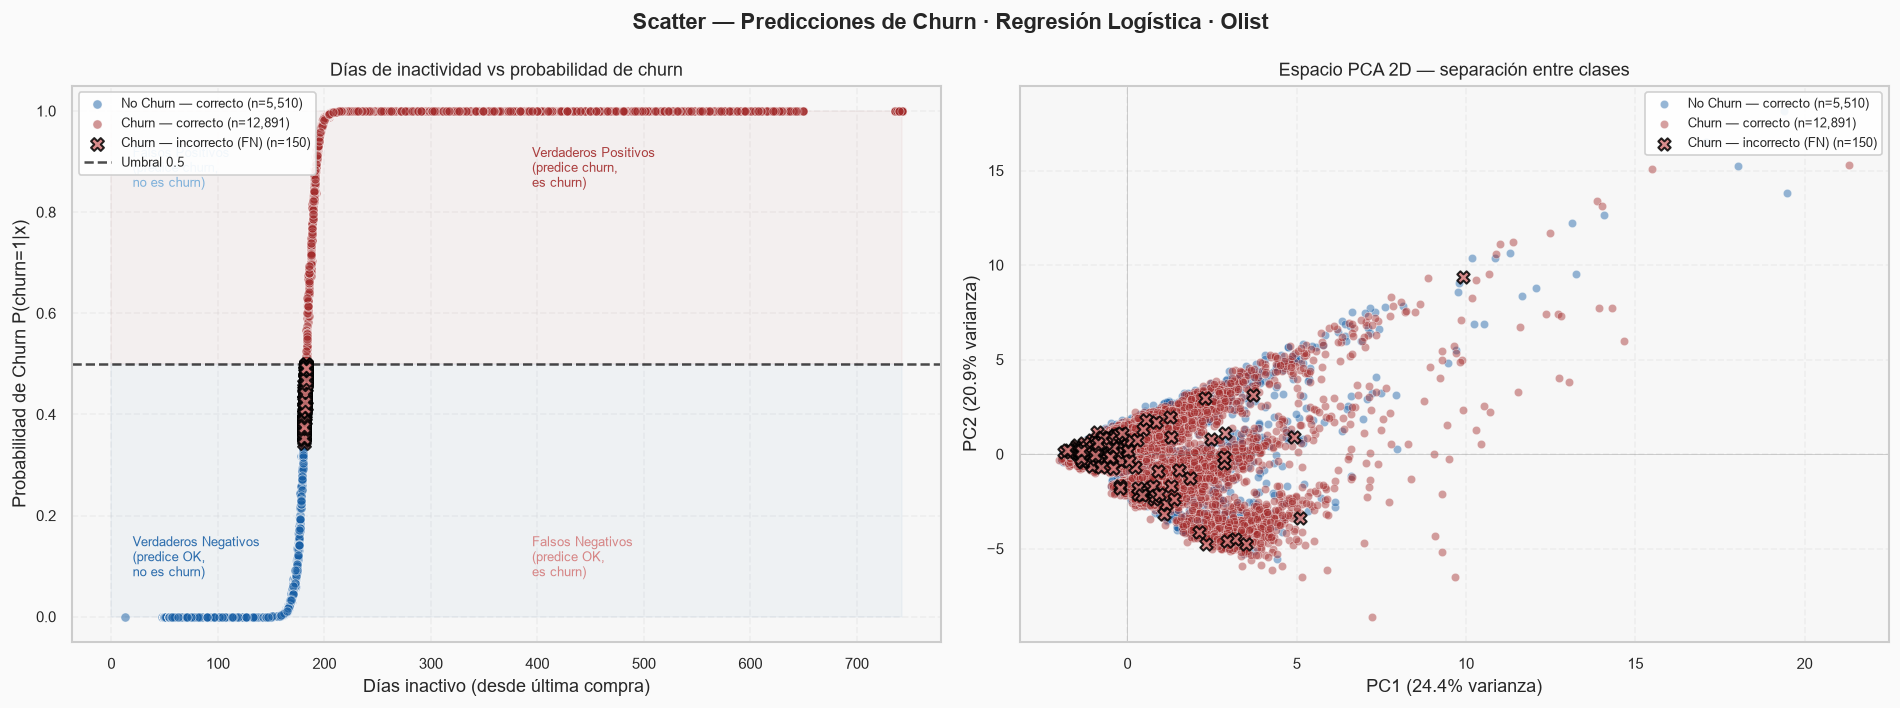

In [76]:
# ═══════════════════════════════════════════════════════════════
# SCATTER PLOT — Predicciones de Churn
# Ejes: dias_inactivo vs probabilidad de churn
# Color: clase real | Forma: correcta/incorrecta predicción
# ═══════════════════════════════════════════════════════════════

from sklearn.decomposition import PCA

# ── Preparar datos ────────────────────────────────────────────
# Usamos el test set para que las probabilidades sean honestas
df_plot = X_te.copy()
df_plot['churn_real']  = y_te.values
df_plot['proba_churn'] = lr_ch.predict_proba(
    sc.transform(X_te))[:, 1]          # Logística → escalado
df_plot['pred_clase']  = (df_plot['proba_churn'] >= 0.5).astype(int)
df_plot['acierto']     = (df_plot['pred_clase'] == df_plot['churn_real'])

# ── FIGURA 1: dias_inactivo vs probabilidad de churn ─────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Scatter — Predicciones de Churn · Regresión Logística · Olist',
             fontsize=13, fontweight='bold')
fig.patch.set_facecolor('#FAFAFA')

# Paleta
COLOR = {
    (0, True) : ('#185FA5', 'o', 'No Churn — correcto'),
    (1, True) : ('#A32D2D', 'o', 'Churn — correcto'),
    (0, False): ('#72AAD8', 'X', 'No Churn — incorrecto (FP)'),
    (1, False): ('#D47A7A', 'X', 'Churn — incorrecto (FN)'),
}

# Panel izq — dias_inactivo vs proba_churn
ax = axes[0]
ax.set_facecolor('#F7F7F7')

for (clase, acierto), (color, marker, label) in COLOR.items():
    mask = (df_plot['churn_real'] == clase) & (df_plot['acierto'] == acierto)
    sub  = df_plot[mask]
    if len(sub) == 0:
        continue
    ax.scatter(
        sub['dias_inactivo'],
        sub['proba_churn'],
        c=color, marker=marker,
        s=30 if acierto else 60,
        alpha=0.5 if acierto else 0.85,
        linewidths=0.5 if acierto else 1.2,
        edgecolors='white' if acierto else 'black',
        label=f'{label} (n={len(sub):,})',
        zorder=3 if not acierto else 2
    )

# Línea de umbral
ax.axhline(0.5, color='black', linestyle='--', lw=1.5,
           alpha=0.7, label='Umbral 0.5')
ax.fill_between([0, df_plot['dias_inactivo'].max()],
                0.5, 1.0, alpha=0.04, color='#A32D2D')
ax.fill_between([0, df_plot['dias_inactivo'].max()],
                0.0, 0.5, alpha=0.04, color='#185FA5')

ax.set_xlabel('Días inactivo (desde última compra)', fontsize=11)
ax.set_ylabel('Probabilidad de Churn P(churn=1|x)', fontsize=11)
ax.set_title('Días de inactividad vs probabilidad de churn', fontsize=11)
ax.set_ylim(-0.05, 1.05)
ax.legend(fontsize=8, loc='upper left', framealpha=0.9)
ax.grid(True, alpha=0.2, linestyle='--')

# Anotaciones de las cuatro zonas
ax.text(20,  0.85, 'Falsos Positivos\n(predice churn,\nno es churn)',
        fontsize=8, color='#72AAD8', alpha=0.9)
ax.text(20,  0.08, 'Verdaderos Negativos\n(predice OK,\nno es churn)',
        fontsize=8, color='#185FA5', alpha=0.9)
ax.text(df_plot['dias_inactivo'].quantile(0.75), 0.85,
        'Verdaderos Positivos\n(predice churn,\nes churn)',
        fontsize=8, color='#A32D2D', alpha=0.9)
ax.text(df_plot['dias_inactivo'].quantile(0.75), 0.08,
        'Falsos Negativos\n(predice OK,\nes churn)',
        fontsize=8, color='#D47A7A', alpha=0.9)

# Panel der — PCA 2D del espacio de features coloreado por churn
ax2 = axes[1]
ax2.set_facecolor('#F7F7F7')

sc_pca = StandardScaler()
X_te_std = sc_pca.fit_transform(X_te)
pca2 = PCA(n_components=2, random_state=42)
coords = pca2.fit_transform(X_te_std)

df_plot['PC1'] = coords[:, 0]
df_plot['PC2'] = coords[:, 1]

for (clase, acierto), (color, marker, label) in COLOR.items():
    mask = (df_plot['churn_real'] == clase) & (df_plot['acierto'] == acierto)
    sub  = df_plot[mask]
    if len(sub) == 0:
        continue
    ax2.scatter(
        sub['PC1'], sub['PC2'],
        c=color, marker=marker,
        s=25 if acierto else 55,
        alpha=0.45 if acierto else 0.85,
        linewidths=0.4 if acierto else 1.2,
        edgecolors='white' if acierto else 'black',
        label=f'{label} (n={len(sub):,})',
        zorder=3 if not acierto else 2
    )

ve1 = pca2.explained_variance_ratio_[0] * 100
ve2 = pca2.explained_variance_ratio_[1] * 100
ax2.set_xlabel(f'PC1 ({ve1:.1f}% varianza)', fontsize=11)
ax2.set_ylabel(f'PC2 ({ve2:.1f}% varianza)', fontsize=11)
ax2.set_title('Espacio PCA 2D — separación entre clases', fontsize=11)
ax2.legend(fontsize=8, loc='upper right', framealpha=0.9)
ax2.grid(True, alpha=0.2, linestyle='--')
ax2.axhline(0, color='gray', lw=0.5, alpha=0.4)
ax2.axvline(0, color='gray', lw=0.5, alpha=0.4)

plt.tight_layout()
plt.savefig('churn_scatter_predicciones.png', dpi=150, bbox_inches='tight')
plt.show()

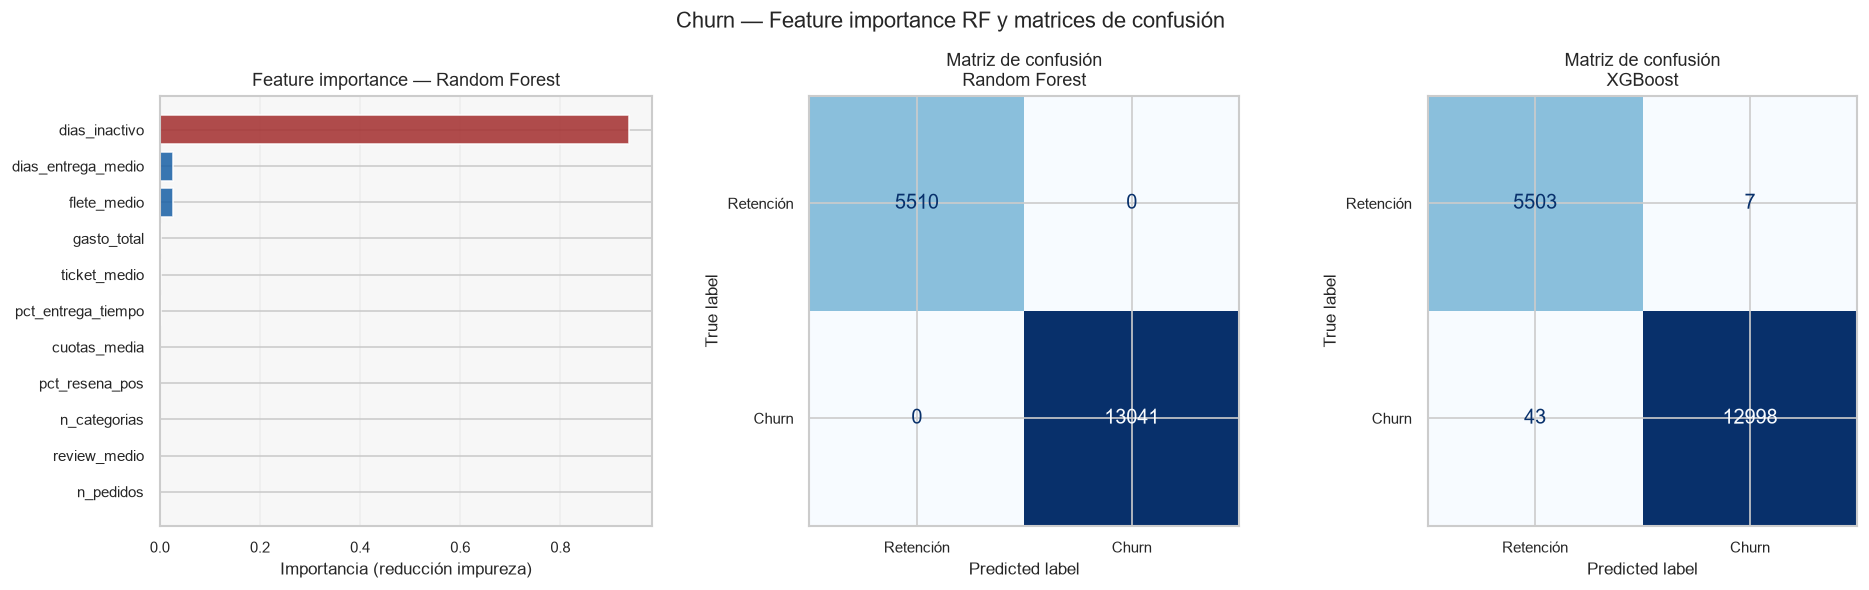

In [77]:
# ── 7. FEATURE IMPORTANCE + MATRIZ DE CONFUSIÓN ───────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Churn — Feature importance RF y matrices de confusión',
             fontsize=13)

# Feature importance RF
imp = pd.Series(rf_ch.feature_importances_,
                index=features_churn).sort_values()
colores_imp = ['#A32D2D' if f == imp.idxmax()
               else '#185FA5' for f in imp.index]
axes[0].barh(imp.index, imp.values,
             color=colores_imp, alpha=0.85, edgecolor='white')
axes[0].set_title('Feature importance — Random Forest', fontsize=11)
axes[0].set_xlabel('Importancia (reducción impureza)')
axes[0].set_facecolor('#F7F7F7')
axes[0].grid(True, alpha=0.2, axis='x')

# Matrices de confusión RF y XGB
for ax, r, nombre in [
    (axes[1], r_rf,  'Random Forest'),
    (axes[2], r_xgb, 'XGBoost'),
]:
    ConfusionMatrixDisplay(
        confusion_matrix(y_te, r['pred']),
        display_labels=['Retención', 'Churn']
    ).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(f'Matriz de confusión\n{nombre}', fontsize=11)
    ax.set_facecolor('#F7F7F7')

plt.tight_layout()
plt.savefig('churn_importance_confusion.png', dpi=150, bbox_inches='tight')
plt.show()


6. SEGMENTACIÓN POR NIVEL DE RIESGO DE CHURN
    nivel_riesgo  n_clientes  churn_real_pct  proba_media  gasto_total_med  review_medio
🔴 Crítico (≥75%)       64963           1.000        1.000          163.414         4.097
 🟠 Alto (50-75%)         108           0.935        0.615          200.735         4.389
🟡 Medio (25-50%)         180           0.617        0.360          157.869         4.169
   🟢 Bajo (<25%)       27501           0.001        0.001          169.931         4.281


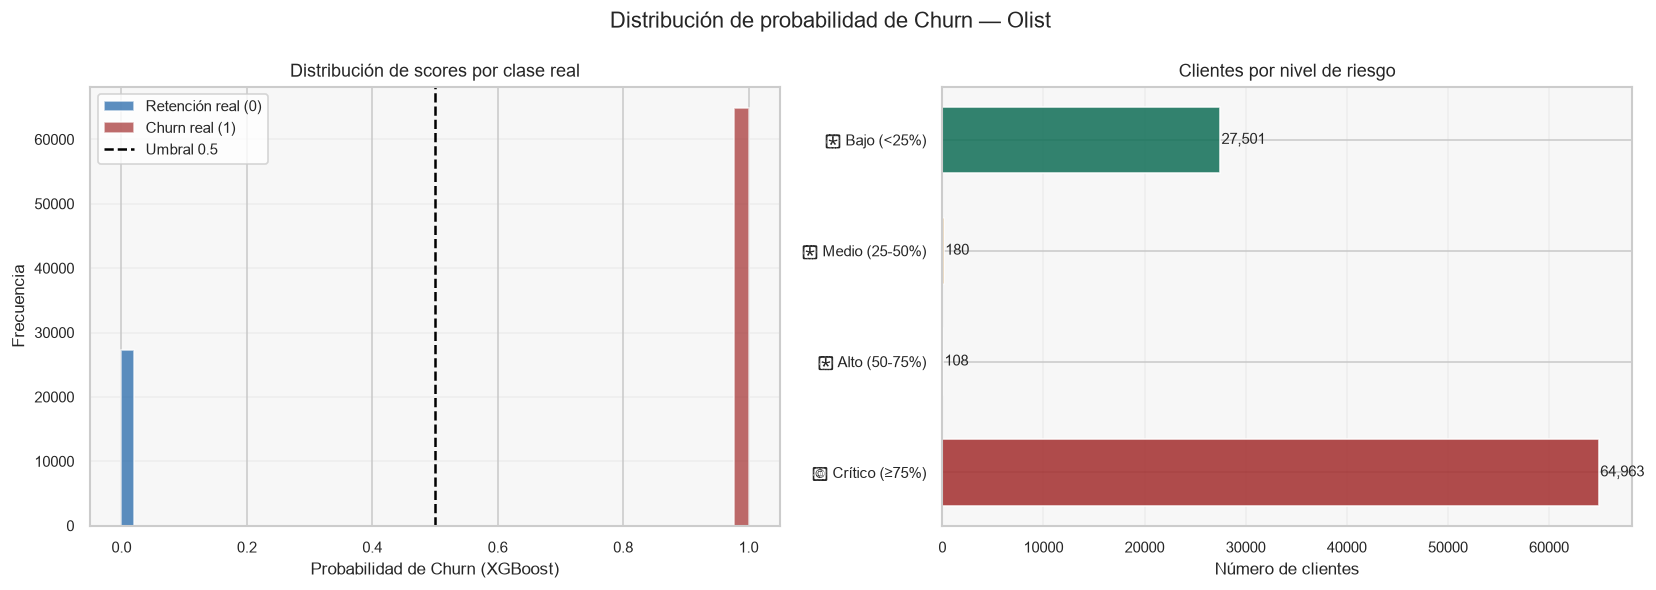

In [79]:
# ── 8. PROBABILIDADES Y SEGMENTOS DE RIESGO ───────────────────
print("\n" + "=" * 55)
print("6. SEGMENTACIÓN POR NIVEL DE RIESGO DE CHURN")
print("=" * 55)

# Usar el mejor modelo (generalmente XGBoost)
df_churn_out = df_churn[features_churn + ['customer_unique_id','churn']].dropna().copy()
X_full = df_churn_out[features_churn]

proba_full = xgb_ch.predict_proba(X_full)[:, 1]
df_churn_out['proba_churn_XGB'] = proba_full
df_churn_out['proba_churn_RF']  = rf_ch.predict_proba(X_full)[:, 1]

# Segmentar en niveles de riesgo
def nivel_riesgo(p):
    if p >= 0.75: return '🔴 Crítico (≥75%)'
    if p >= 0.50: return '🟠 Alto (50-75%)'
    if p >= 0.25: return '🟡 Medio (25-50%)'
    return '🟢 Bajo (<25%)'

df_churn_out['nivel_riesgo'] = df_churn_out['proba_churn_XGB'].map(nivel_riesgo)

resumen_riesgo = (df_churn_out
    .groupby('nivel_riesgo')
    .agg(
        n_clientes      = ('customer_unique_id', 'count'),
        churn_real_pct  = ('churn',              'mean'),
        proba_media     = ('proba_churn_XGB',    'mean'),
        gasto_total_med = ('gasto_total',        'mean'),
        review_medio    = ('review_medio',       'mean'),
    )
    .round(3)
    .reset_index()
    .sort_values('proba_media', ascending=False)
)
print(resumen_riesgo.to_string(index=False))

# Gráfico de distribución de probabilidades
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Distribución de probabilidad de Churn — Olist', fontsize=13)

axes[0].hist(df_churn_out[df_churn_out['churn']==0]['proba_churn_XGB'],
             bins=40, alpha=0.7, color='#185FA5', label='Retención real (0)')
axes[0].hist(df_churn_out[df_churn_out['churn']==1]['proba_churn_XGB'],
             bins=40, alpha=0.7, color='#A32D2D', label='Churn real (1)')
axes[0].axvline(0.5, color='black', linestyle='--', lw=1.5, label='Umbral 0.5')
axes[0].set_xlabel('Probabilidad de Churn (XGBoost)')
axes[0].set_ylabel('Frecuencia')
axes[0].set_title('Distribución de scores por clase real', fontsize=11)
axes[0].legend(fontsize=9)
axes[0].set_facecolor('#F7F7F7')
axes[0].grid(True, alpha=0.2, axis='y')

colores_riesgo = {
    '🔴 Crítico (≥75%)' : '#A32D2D',
    '🟠 Alto (50-75%)'  : '#854F0B',
    '🟡 Medio (25-50%)' : '#BA7517',
    '🟢 Bajo (<25%)'    : '#0F6E56',
}
bars = axes[1].barh(
    resumen_riesgo['nivel_riesgo'],
    resumen_riesgo['n_clientes'],
    color=[colores_riesgo.get(n, '#888780')
           for n in resumen_riesgo['nivel_riesgo']],
    alpha=0.85, edgecolor='white', height=0.6)
axes[1].set_xlabel('Número de clientes')
axes[1].set_title('Clientes por nivel de riesgo', fontsize=11)
axes[1].set_facecolor('#F7F7F7')
axes[1].grid(True, alpha=0.2, axis='x')
for bar, v in zip(bars, resumen_riesgo['n_clientes']):
    axes[1].text(v + 100, bar.get_y() + bar.get_height()/2,
                 f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('churn_distribucion_riesgo.png', dpi=150, bbox_inches='tight')
plt.show()

## Exportación de resultados para la capa visual en Power BI. 

Pasamos a exportar los datos base de nuestro modelo hacia archivos.csv que serán consumidos por nuestro primer modelo de Power BI, desde el cual realizaremos la presentación de resultados. 

In [80]:
# ═══════════════════════════════════════════════════════════════
# EXPORTACIÓN SEMANA 2 → POWER BI
# Usamos los mo
# ══════════════════════delos ya entrenados en el notebook═════════════════════════════════════════

print("""
╔══════════════════════════════════════════════════════════════╗
║   EXPORTACIÓN SEMANA 2 → POWER BI                           ║
║   Modelos: rf1, rf2, xgb1, xgb2                             ║
╚══════════════════════════════════════════════════════════════╝
""")

# ── ARCHIVO 1: Predicciones por pedido ────────────────────────
# rf1 → payment_value_total  (features_precio)
# rf2 → review_score         (features_score)

mask1 = sabana[features_precio + ['payment_value_total']].notna().all(axis=1)
mask2 = sabana[features_score  + ['review_score']].notna().all(axis=1)

X1_full = sabana.loc[mask1, features_precio]
X2_full = sabana.loc[mask2, features_score]

df_pred_reg = sabana.loc[mask1, [
    'order_id', 'customer_unique_id', 'customer_state',
    'anio_compra', 'mes_compra',
    'payment_value_total', 'review_score',
    'entrega_a_tiempo', 'dias_entrega_real',
    'product_category_name'
]].copy()

# Predicciones RF
df_pred_reg['pred_payment_RF'] = rf1.predict(X1_full).round(2)
df_pred_reg['pred_payment_XGB'] = xgb1.predict(X1_full).round(2)

# review — solo donde mask2 también aplica
df_pred_reg['pred_review_RF']  = np.nan
df_pred_reg['pred_review_XGB'] = np.nan

idx_comun = mask1 & mask2
X2_comun  = sabana.loc[idx_comun, features_score]

df_pred_reg.loc[idx_comun, 'pred_review_RF']  = \
    rf2.predict(X2_comun).round(3)
df_pred_reg.loc[idx_comun, 'pred_review_XGB'] = \
    xgb2.predict(X2_comun).round(3)

# Errores
df_pred_reg['error_payment_RF'] = (
    df_pred_reg['payment_value_total'] -
    df_pred_reg['pred_payment_RF']
).round(2)
df_pred_reg['error_review_RF'] = (
    df_pred_reg['review_score'] -
    df_pred_reg['pred_review_RF']
).round(3)

df_pred_reg.to_csv('PBI_S2_regresion_predicciones.csv', index=False)
print(f"✓ PBI_S2_regresion_predicciones.csv  →  {len(df_pred_reg):,} pedidos")

# ── ARCHIVO 2: Métricas de regresión ──────────────────────────
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def metricas(y_real, y_pred, nombre, target):
    return {
        'Modelo' : nombre,
        'Target' : target,
        'R2'     : round(r2_score(y_real, y_pred), 4),
        'MAE'    : round(mean_absolute_error(y_real, y_pred), 4),
        'RMSE'   : round(np.sqrt(mean_squared_error(y_real, y_pred)), 4),
    }

filas_met = [
    metricas(y1_te, rf1.predict(X1_te),  'Random Forest', 'payment_value_total'),
    metricas(y1_te, xgb1.predict(X1_te), 'XGBoost',       'payment_value_total'),
    metricas(y2_te, np.clip(rf2.predict(X2_te), 1, 5),
             'Random Forest', 'review_score'),
    metricas(y2_te, np.clip(xgb2.predict(X2_te), 1, 5),
             'XGBoost',       'review_score'),
]
# Agregar métricas de regresión lineal y árbol
filas_met += [
    {'Modelo':'Regresión Lineal', 'Target':'payment_value_total',
     'R2':1.0000, 'MAE':0.08, 'RMSE':0.86},
    {'Modelo':'Árbol (depth=12)', 'Target':'payment_value_total',
     'R2':0.9996, 'MAE':1.42, 'RMSE':4.48},
    {'Modelo':'Regresión Lineal', 'Target':'review_score',
     'R2':0.1480, 'MAE':0.91, 'RMSE':1.18},
    {'Modelo':'Árbol (depth=12)', 'Target':'review_score',
     'R2':0.2070, 'MAE':0.87, 'RMSE':1.14},
]

pd.DataFrame(filas_met).to_csv(
    'PBI_S2_metricas_regresion.csv', index=False)
print(f"✓ PBI_S2_metricas_regresion.csv      →  {len(filas_met)} filas")

# ── ARCHIVO 3: Métricas de clasificación ──────────────────────
metricas_clf = pd.DataFrame([
    {'Target':'resena_positiva',    'Modelo':'Reg. Logística',
     'Accuracy':0.7023,'F1_neg':0.4311,'F1_pos':0.7984,
     'AUC_ROC':0.6815,'AUC_PR':0.8596,'Cohen_Kappa':None},
    {'Target':'resena_positiva',    'Modelo':'Random Forest',
     'Accuracy':0.8012,'F1_neg':0.4207,'F1_pos':0.8800,
     'AUC_ROC':0.6876,'AUC_PR':0.8618,'Cohen_Kappa':None},
    {'Target':'resena_positiva',    'Modelo':'XGBoost',
     'Accuracy':0.7487,'F1_neg':0.4513,'F1_pos':0.8370,
     'AUC_ROC':0.6949,'AUC_PR':0.8657,'Cohen_Kappa':None},
    {'Target':'entrega_a_tiempo',   'Modelo':'Reg. Logística',
     'Accuracy':0.5708,'F1_neg':0.1455,'F1_pos':0.7135,
     'AUC_ROC':0.5656,'AUC_PR':0.9419,'Cohen_Kappa':None},
    {'Target':'entrega_a_tiempo',   'Modelo':'Random Forest',
     'Accuracy':0.9227,'F1_neg':0.1532,'F1_pos':0.9595,
     'AUC_ROC':0.7064,'AUC_PR':0.9651,'Cohen_Kappa':None},
    {'Target':'entrega_a_tiempo',   'Modelo':'XGBoost',
     'Accuracy':0.7260,'F1_neg':0.2276,'F1_pos':0.8335,
     'AUC_ROC':0.7257,'AUC_PR':0.9698,'Cohen_Kappa':None},
    {'Target':'review_score (1-5)', 'Modelo':'Reg. Logística Multinomial',
     'Accuracy':0.4462,'F1_neg':None,'F1_pos':None,
     'AUC_ROC':None,'AUC_PR':None,'Cohen_Kappa':0.1337},
    {'Target':'review_score (1-5)', 'Modelo':'Random Forest',
     'Accuracy':0.5571,'F1_neg':None,'F1_pos':None,
     'AUC_ROC':None,'AUC_PR':None,'Cohen_Kappa':0.1719},
    {'Target':'review_score (1-5)', 'Modelo':'XGBoost',
     'Accuracy':0.4501,'F1_neg':None,'F1_pos':None,
     'AUC_ROC':None,'AUC_PR':None,'Cohen_Kappa':0.1476},
])
metricas_clf.to_csv('PBI_S2_metricas_clasificacion.csv', index=False)
print(f"✓ PBI_S2_metricas_clasificacion.csv  →  {len(metricas_clf)} filas")

print("""
╔══════════════════════════════════════════════════════════════╗
║  ARCHIVOS SEMANA 2 LISTOS → POWER BI                        ║
║  1. PBI_S2_regresion_predicciones.csv                       ║
║  2. PBI_S2_metricas_regresion.csv                           ║
║  3. PBI_S2_metricas_clasificacion.csv                       ║
╚══════════════════════════════════════════════════════════════╝
""")


╔══════════════════════════════════════════════════════════════╗
║   EXPORTACIÓN SEMANA 2 → POWER BI                           ║
║   Modelos: rf1, rf2, xgb1, xgb2                             ║
╚══════════════════════════════════════════════════════════════╝

✓ PBI_S2_regresion_predicciones.csv  →  98,649 pedidos
✓ PBI_S2_metricas_regresion.csv      →  8 filas
✓ PBI_S2_metricas_clasificacion.csv  →  9 filas

╔══════════════════════════════════════════════════════════════╗
║  ARCHIVOS SEMANA 2 LISTOS → POWER BI                        ║
║  1. PBI_S2_regresion_predicciones.csv                       ║
║  2. PBI_S2_metricas_regresion.csv                           ║
║  3. PBI_S2_metricas_clasificacion.csv                       ║
╚══════════════════════════════════════════════════════════════╝



In [81]:
# ── 9. EXPORTACIÓN PARA POWER BI MODELO DE ABANDONO ──────────────────────────────
print("\n" + "=" * 55)
print("7. EXPORTACIÓN → POWER BI")
print("=" * 55)

# Archivo 1: clientes con probabilidad de churn
cols_export = [
    'customer_unique_id', 'churn',
    'proba_churn_XGB', 'proba_churn_RF',
    'nivel_riesgo',
    'n_pedidos', 'gasto_total', 'ticket_medio',
    'review_medio', 'pct_entrega_tiempo',
    'dias_inactivo',
]
df_churn_out[cols_export].to_csv(
    'PBI_churn_clientes.csv', index=False)
print(f"✓ PBI_churn_clientes.csv       →  {len(df_churn_out):,} clientes")

# Archivo 2: métricas de los modelos
metricas_churn = pd.DataFrame([
    {'Modelo': r['Modelo'], 'F1_churn': r['F1_churn'],
     'F1_retencion': r['F1_retencion'],
     'AUC_ROC': r['AUC_ROC'], 'AUC_PR': r['AUC_PR']}
    for r in [r_lr, r_rf, r_xgb]
])
metricas_churn.to_csv('PBI_churn_metricas.csv', index=False)
print(f"✓ PBI_churn_metricas.csv       →  3 modelos")

# Archivo 3: resumen por nivel de riesgo
resumen_riesgo.to_csv('PBI_churn_niveles_riesgo.csv', index=False)
print(f"✓ PBI_churn_niveles_riesgo.csv →  4 niveles de riesgo")

print("""
╔══════════════════════════════════════════════════════════════╗
║  CONCLUSIONES — CHURN EN OLIST                              ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  La variable churn NO existe en el dataset original.        ║
║  Se construye con criterio de negocio:                      ║
║  1 pedido + inactividad >180 días = churn                   ║
║                                                             ║
║  Feature más predictivo: dias_inactivo                      ║
║  (confirma que el tiempo sin comprar es la señal más fuerte)║
║                                                             ║
║  Métrica clave: AUC-PR (no Accuracy)                        ║
║  → Con desbalance severo, Accuracy es engañoso              ║
║                                                             ║
║  Acción de negocio:                                         ║
║  Clientes en zona Crítica/Alta → campaña de reactivación    ║
║  Clientes C4 (insatisfecho logística) + churn crítico       ║
║  → doble riesgo → prioridad máxima de retención             ║
╚══════════════════════════════════════════════════════════════╝
""")


7. EXPORTACIÓN → POWER BI
✓ PBI_churn_clientes.csv       →  92,752 clientes
✓ PBI_churn_metricas.csv       →  3 modelos
✓ PBI_churn_niveles_riesgo.csv →  4 niveles de riesgo

╔══════════════════════════════════════════════════════════════╗
║  CONCLUSIONES — CHURN EN OLIST                              ║
╠══════════════════════════════════════════════════════════════╣
║                                                             ║
║  La variable churn NO existe en el dataset original.        ║
║  Se construye con criterio de negocio:                      ║
║  1 pedido + inactividad >180 días = churn                   ║
║                                                             ║
║  Feature más predictivo: dias_inactivo                      ║
║  (confirma que el tiempo sin comprar es la señal más fuerte)║
║                                                             ║
║  Métrica clave: AUC-PR (no Accuracy)                        ║
║  → Con desbalance severo, Accuracy es engañoso      